In [1]:
#pip install --upgrade --force-reinstall --no-cache-dir "numpy>=2.0,<3.0" "pandas>=2.2" "scipy>=1.14" "matplotlib>=3.9" "pyarrow>=17" "numexpr>=2.10" "bottleneck>=1.4"


Parte 1

In [2]:
import numpy as np
import pandas as pd
import scipy
import matplotlib
import pyarrow
import numexpr
import bottleneck

from pathlib import Path

{"NumPy": np.__version__,
 "Pandas": pd.__version__,
 "SciPy": scipy.__version__,
 "Matplotlib": matplotlib.__version__,
 "PyArrow": pyarrow.__version__,
 "NumExpr": numexpr.__version__,
 "Bottleneck": bottleneck.__version__}

{'NumPy': '2.4.6',
 'Pandas': '3.1.1',
 'SciPy': '1.17.1',
 'Matplotlib': '3.11.2',
 'PyArrow': '26.0.1',
 'NumExpr': '2.14.2',
 'Bottleneck': '1.6.1'}

In [3]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt

from pathlib import Path

# Reproducibility
RANDOM_SEED = 2027
rng = np.random.default_rng(RANDOM_SEED)

# Output directories
FIGS_DIR = Path("figs")
RESULTS_DIR = Path("results")

FIGS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Scientific figure settings
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25
})

# Environment metadata
ENVIRONMENT = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "random_seed": RANDOM_SEED}

In [4]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt

from pathlib import Path

# Reproducibility
RANDOM_SEED = 2027

# Output directories
FIGS_DIR = Path("figs")
RESULTS_DIR = Path("results")

FIGS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Scientific visualization settings
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "savefig.bbox": "tight"
})

# Environment metadata
ENVIRONMENT = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "random_seed": RANDOM_SEED
}

pd.Series(ENVIRONMENT).to_csv(
    RESULTS_DIR / "environment_metadata.csv",
    header=["value"]
)

In [5]:
EXPERIMENT_ID = "E01_convergence"

# Small-sample validation settings
SAMPLE_SIZES = np.array([10, 25, 50, 100, 250, 500])
PROBABILITIES = np.array([0.10, 0.30, 0.50, 0.70, 0.90])

N_REPLICATIONS = 100

# Statistical criteria
ALPHA = 0.05
CONFIDENCE_LEVEL = 1 - ALPHA
ERROR_TOLERANCE = 0.05

# Mathematical validation
assert np.all(SAMPLE_SIZES > 0)
assert np.all(np.diff(SAMPLE_SIZES) > 0)
assert np.all((PROBABILITIES > 0) & (PROBABILITIES < 1))
assert N_REPLICATIONS > 1
assert 0 < ALPHA < 1
assert ERROR_TOLERANCE > 0

# Save experimental configuration
CONFIG = pd.DataFrame({
    "parameter": [
        "sample_sizes",
        "probabilities",
        "n_replications",
        "alpha",
        "error_tolerance",
        "random_seed"
    ],
    "value": [
        str(SAMPLE_SIZES.tolist()),
        str(PROBABILITIES.tolist()),
        str(N_REPLICATIONS),
        str(ALPHA),
        str(ERROR_TOLERANCE),
        str(RANDOM_SEED)
    ]
})

CONFIG.to_csv(
    RESULTS_DIR / "E01_configuration.csv",
    index=False
)

In [6]:
def simulate_bernoulli(n, p, seed=None):
    """Generate n independent Bernoulli(p) observations."""

    if not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError("n must be a positive integer.")

    if not np.isfinite(p) or not 0 <= p <= 1:
        raise ValueError("p must be between 0 and 1.")

    generator = np.random.default_rng(seed)

    return generator.binomial(1, p, size=n)


# Small-scale functional test
n_test = 20
p_test = 0.50

sample = simulate_bernoulli(
    n=n_test,
    p=p_test,
    seed=RANDOM_SEED
)

successes = int(sample.sum())
p_hat = float(sample.mean())

# Mathematical and computational checks
assert len(sample) == n_test
assert np.all(np.isin(sample, [0, 1]))
assert np.isclose(p_hat, successes / n_test)

assert np.array_equal(
    sample,
    simulate_bernoulli(n_test, p_test, RANDOM_SEED)
)

assert simulate_bernoulli(10, 0.0, RANDOM_SEED).sum() == 0
assert simulate_bernoulli(10, 1.0, RANDOM_SEED).sum() == 10

# Save test results
bernoulli_test = pd.DataFrame({
    "trial": np.arange(1, n_test + 1),
    "outcome": sample,
    "cumulative_successes": np.cumsum(sample),
    "relative_frequency": np.cumsum(sample) /
                          np.arange(1, n_test + 1)
})

bernoulli_test.to_csv(
    RESULTS_DIR / "E01_bernoulli_initial_test.csv",
    index=False
)

bernoulli_test

,trial,outcome,cumulative_successes,relative_frequency
0,1,0,0,0.000000
1,2,0,0,0.000000
2,3,0,0,0.000000
3,4,0,0,0.000000
4,5,0,0,0.000000
5,6,1,1,0.166667
6,7,0,1,0.142857
7,8,1,2,0.250000
8,9,1,3,0.333333
9,10,0,3,0.300000


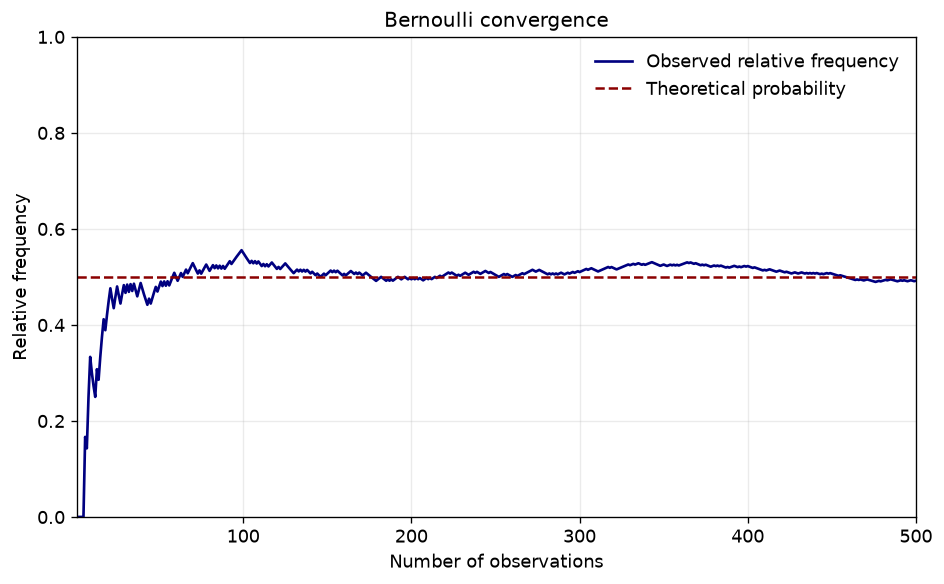

In [7]:
n = 500
p = 0.50

observations = simulate_bernoulli(
    n=n,
    p=p,
    seed=RANDOM_SEED
)

sample_index = np.arange(1, n + 1)

relative_frequency = (
    np.cumsum(observations) / sample_index
)

absolute_error = np.abs(relative_frequency - p)

convergence_data = pd.DataFrame({
    "n": sample_index,
    "relative_frequency": relative_frequency,
    "theoretical_probability": p,
    "absolute_error": absolute_error
})

convergence_data.to_csv(
    RESULTS_DIR / "E01_convergence_trajectory.csv",
    index=False
)

# Individual scientific figure
fig, ax = plt.subplots()

ax.plot(
    sample_index,
    relative_frequency,
    color="navy",
    linewidth=1.6,
    label="Observed relative frequency"
)

ax.axhline(
    p,
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label="Theoretical probability"
)

ax.set(
    xlabel="Number of observations",
    ylabel="Relative frequency",
    title="Bernoulli convergence"
)

ax.set_xlim(1, n)
ax.set_ylim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E01_Figure01_Convergence.png")
fig.savefig(FIGS_DIR / "E01_Figure01_Convergence.pdf")

plt.show()

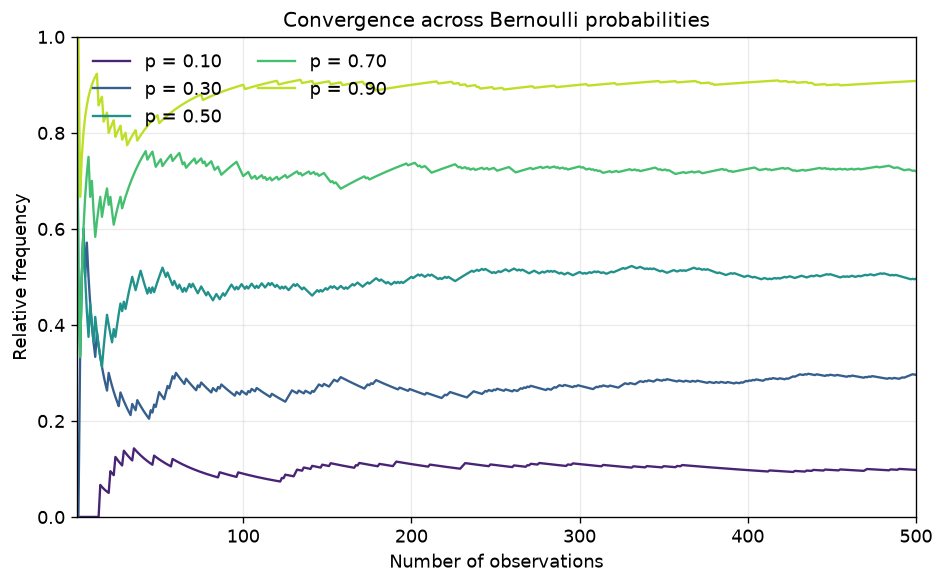

In [8]:
n = 500

probability_cases = [0.10, 0.30, 0.50, 0.70, 0.90]

sample_index = np.arange(1, n + 1)

trajectories = pd.DataFrame({"n": sample_index})

fig, ax = plt.subplots()

colors = plt.cm.viridis(
    np.linspace(0.10, 0.90, len(probability_cases))
)

for i, p in enumerate(probability_cases):

    observations = simulate_bernoulli(
        n=n,
        p=p,
        seed=RANDOM_SEED + i
    )

    relative_frequency = (
        np.cumsum(observations) / sample_index
    )

    trajectories[f"p_{p:.2f}"] = relative_frequency

    ax.plot(
        sample_index,
        relative_frequency,
        color=colors[i],
        linewidth=1.4,
        label=f"p = {p:.2f}"
    )

trajectories.to_csv(
    RESULTS_DIR / "E01_multiple_probabilities.csv",
    index=False
)

ax.set(
    xlabel="Number of observations",
    ylabel="Relative frequency",
    title="Convergence across Bernoulli probabilities"
)

ax.set_xlim(1, n)
ax.set_ylim(0, 1)
ax.legend(frameon=False, ncol=2)

fig.tight_layout()

fig.savefig(
    FIGS_DIR / "E01_Figure02_MultipleProbabilities.png"
)
fig.savefig(
    FIGS_DIR / "E01_Figure02_MultipleProbabilities.pdf"
)

plt.show()

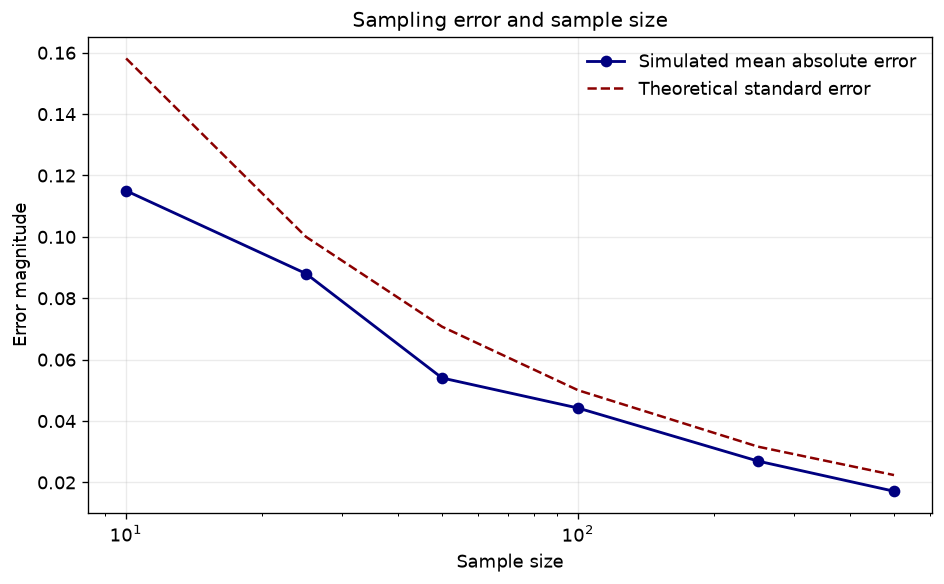

,sample_size,mean_absolute_error,std_absolute_error,theoretical_standard_error
0,10,0.11500,0.085723,0.158114
1,25,0.08800,0.060034,0.100000
2,50,0.05400,0.043531,0.070711
3,100,0.04420,0.032104,0.050000
4,250,0.02692,0.020474,0.031623
5,500,0.01710,0.013389,0.022361


In [9]:
p = 0.50

error_records = []

for n in SAMPLE_SIZES:

    generator = np.random.default_rng(
        RANDOM_SEED + int(n)
    )

    simulations = generator.binomial(
        n=1,
        p=p,
        size=(N_REPLICATIONS, int(n))
    )

    estimates = simulations.mean(axis=1)

    errors = np.abs(estimates - p)

    for replication, error in enumerate(errors, start=1):
        error_records.append({
            "sample_size": int(n),
            "replication": replication,
            "absolute_error": float(error)
        })

error_data = pd.DataFrame(error_records)

error_summary = (
    error_data.groupby("sample_size", as_index=False)
    .agg(
        mean_absolute_error=("absolute_error", "mean"),
        std_absolute_error=("absolute_error", "std")
    )
)

error_summary["theoretical_standard_error"] = np.sqrt(
    p * (1 - p) / error_summary["sample_size"]
)

error_data.to_csv(
    RESULTS_DIR / "E01_absolute_errors.csv",
    index=False
)

error_summary.to_csv(
    RESULTS_DIR / "E01_error_summary.csv",
    index=False
)

# Individual scientific figure
fig, ax = plt.subplots()

ax.plot(
    error_summary["sample_size"],
    error_summary["mean_absolute_error"],
    marker="o",
    color="navy",
    linewidth=1.7,
    label="Simulated mean absolute error"
)

ax.plot(
    error_summary["sample_size"],
    error_summary["theoretical_standard_error"],
    linestyle="--",
    color="darkred",
    linewidth=1.5,
    label="Theoretical standard error"
)

ax.set(
    xlabel="Sample size",
    ylabel="Error magnitude",
    title="Sampling error and sample size"
)

ax.set_xscale("log")
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E01_Figure03_AbsoluteError.png")
fig.savefig(FIGS_DIR / "E01_Figure03_AbsoluteError.pdf")

plt.show()

error_summary

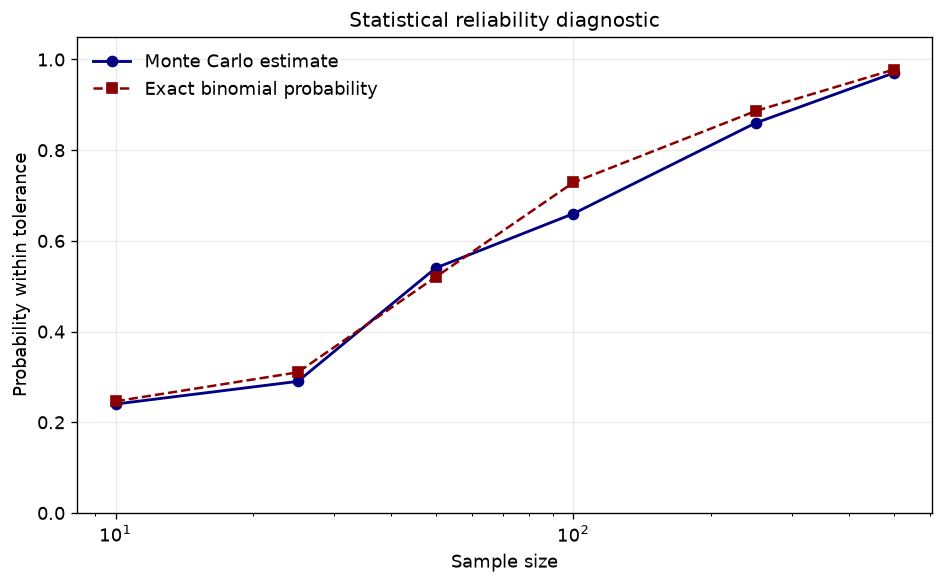

,sample_size,empirical_reliability,theoretical_reliability,absolute_difference
0,10,0.24,0.246094,0.006094
1,25,0.29,0.309962,0.019962
2,50,0.54,0.520112,0.019888
3,100,0.66,0.728747,0.068747
4,250,0.86,0.886334,0.026334
5,500,0.97,0.977534,0.007534


In [10]:
from scipy.stats import binom

p = 0.50
epsilon = ERROR_TOLERANCE

reliability_records = []

for n in SAMPLE_SIZES:

    subset = error_data.loc[
        error_data["sample_size"] == n,
        "absolute_error"
    ]

    empirical_reliability = np.mean(
        subset.to_numpy() <= epsilon + 1e-12
    )

    # Exact binomial probability for the tolerance criterion
    k_min = int(np.ceil(n * (p - epsilon) - 1e-12))
    k_max = int(np.floor(n * (p + epsilon) + 1e-12))

    k_min = max(0, k_min)
    k_max = min(int(n), k_max)

    theoretical_reliability = (
        binom.cdf(k_max, int(n), p)
        - binom.cdf(k_min - 1, int(n), p)
    )

    reliability_records.append({
        "sample_size": int(n),
        "empirical_reliability": empirical_reliability,
        "theoretical_reliability": theoretical_reliability,
        "absolute_difference": abs(
            empirical_reliability - theoretical_reliability
        )
    })

reliability_data = pd.DataFrame(reliability_records)

assert reliability_data[
    ["empirical_reliability", "theoretical_reliability"]
].ge(0).all().all()

assert reliability_data[
    ["empirical_reliability", "theoretical_reliability"]
].le(1).all().all()

reliability_data.to_csv(
    RESULTS_DIR / "E01_reliability_diagnostic.csv",
    index=False
)

# Individual scientific figure
fig, ax = plt.subplots()

ax.plot(
    reliability_data["sample_size"],
    reliability_data["empirical_reliability"],
    marker="o",
    color="navy",
    linewidth=1.7,
    label="Monte Carlo estimate"
)

ax.plot(
    reliability_data["sample_size"],
    reliability_data["theoretical_reliability"],
    marker="s",
    linestyle="--",
    color="darkred",
    linewidth=1.5,
    label="Exact binomial probability"
)

ax.set(
    xlabel="Sample size",
    ylabel="Probability within tolerance",
    title="Statistical reliability diagnostic"
)

ax.set_xscale("log")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E01_Figure04_Reliability.png")
fig.savefig(FIGS_DIR / "E01_Figure04_Reliability.pdf")

plt.show()

reliability_data

In [11]:
p = 0.50

sampling_records = []

for n in SAMPLE_SIZES:

    generator = np.random.default_rng(
        RANDOM_SEED + 1000 + int(n)
    )

    successes = generator.binomial(
        n=int(n),
        p=p,
        size=N_REPLICATIONS
    )

    estimates = successes / n

    for replication, (k, estimate) in enumerate(
        zip(successes, estimates), start=1
    ):
        sampling_records.append({
            "sample_size": int(n),
            "replication": replication,
            "successes": int(k),
            "p_true": p,
            "p_hat": float(estimate)
        })

sampling_data = pd.DataFrame(sampling_records)

# Mathematical validation
assert len(sampling_data) == (
    len(SAMPLE_SIZES) * N_REPLICATIONS
)
assert sampling_data["p_hat"].between(0, 1).all()
assert np.allclose(
    sampling_data["p_hat"],
    sampling_data["successes"] /
    sampling_data["sample_size"]
)

sampling_data.to_csv(
    RESULTS_DIR / "E02_sampling_distributions.csv",
    index=False
)

sampling_data.head(10)


,sample_size,replication,successes,p_true,p_hat
0,10,1,5,0.5,0.5
1,10,2,6,0.5,0.6
2,10,3,4,0.5,0.4
3,10,4,3,0.5,0.3
4,10,5,7,0.5,0.7
5,10,6,6,0.5,0.6
6,10,7,4,0.5,0.4
7,10,8,3,0.5,0.3
8,10,9,5,0.5,0.5
9,10,10,3,0.5,0.3


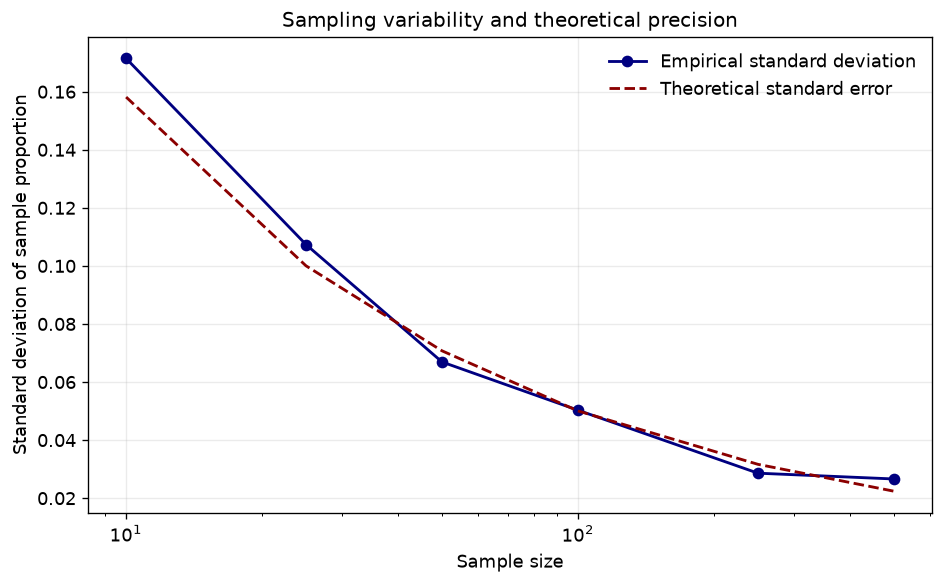

,sample_size,mean_estimate,empirical_variance,empirical_se,theoretical_variance,theoretical_se,absolute_bias
0,10,0.49700,0.029385,0.171420,0.0250,0.158114,0.00300
1,25,0.51000,0.011519,0.107327,0.0100,0.100000,0.01000
2,50,0.48940,0.004472,0.066876,0.0050,0.070711,0.01060
3,100,0.50000,0.002525,0.050252,0.0025,0.050000,0.00000
4,250,0.49852,0.000816,0.028572,0.0010,0.031623,0.00148
5,500,0.49746,0.000706,0.026578,0.0005,0.022361,0.00254


In [12]:
sampling_summary = (
    sampling_data.groupby("sample_size", as_index=False)
    .agg(
        mean_estimate=("p_hat", "mean"),
        empirical_variance=("p_hat", "var"),
        empirical_se=("p_hat", "std")
    )
)

sampling_summary["theoretical_variance"] = (
    p * (1 - p) / sampling_summary["sample_size"]
)

sampling_summary["theoretical_se"] = np.sqrt(
    sampling_summary["theoretical_variance"]
)

sampling_summary["absolute_bias"] = np.abs(
    sampling_summary["mean_estimate"] - p
)

sampling_summary.to_csv(
    RESULTS_DIR / "E02_sampling_summary.csv",
    index=False
)

fig, ax = plt.subplots()

ax.plot(
    sampling_summary["sample_size"],
    sampling_summary["empirical_se"],
    marker="o",
    linewidth=1.7,
    color="navy",
    label="Empirical standard deviation"
)

ax.plot(
    sampling_summary["sample_size"],
    sampling_summary["theoretical_se"],
    linestyle="--",
    linewidth=1.7,
    color="darkred",
    label="Theoretical standard error"
)

ax.set(
    xlabel="Sample size",
    ylabel="Standard deviation of sample proportion",
    title="Sampling variability and theoretical precision"
)

ax.set_xscale("log")
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E02_Figure05_StandardError.png")
fig.savefig(FIGS_DIR / "E02_Figure05_StandardError.pdf")

plt.show()

sampling_summary


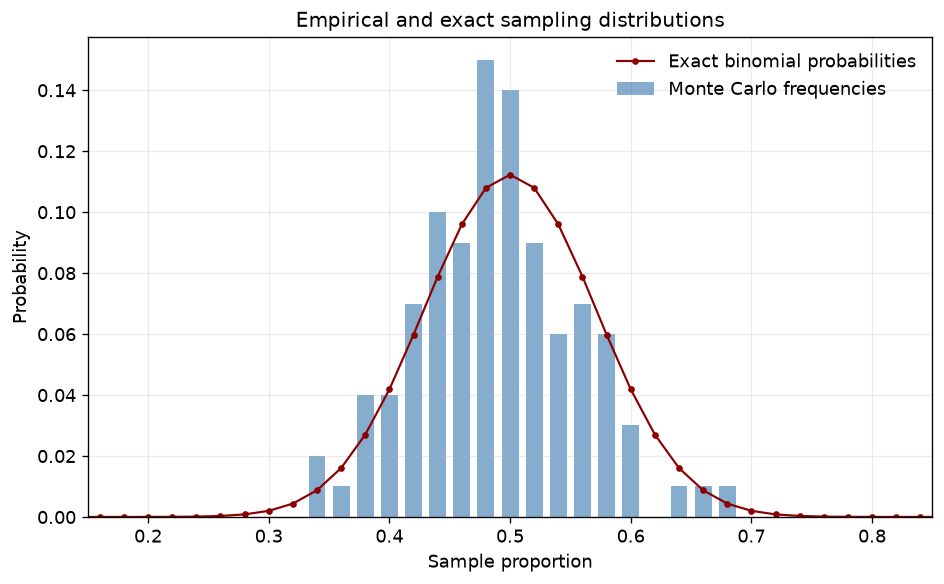

In [13]:
from scipy.stats import binom

n = 50
p = 0.50

subset = sampling_data.loc[
    sampling_data["sample_size"] == n
]

observed_counts = subset["successes"].to_numpy()

k_values = np.arange(n + 1)

empirical_pmf = (
    np.bincount(observed_counts, minlength=n + 1)
    / len(observed_counts)
)

theoretical_pmf = binom.pmf(k_values, n, p)

distribution_comparison = pd.DataFrame({
    "successes": k_values,
    "sample_proportion": k_values / n,
    "empirical_probability": empirical_pmf,
    "theoretical_probability": theoretical_pmf
})

assert np.isclose(empirical_pmf.sum(), 1.0)
assert np.isclose(theoretical_pmf.sum(), 1.0)

distribution_comparison.to_csv(
    RESULTS_DIR / "E02_binomial_comparison.csv",
    index=False
)

fig, ax = plt.subplots()

ax.bar(
    k_values / n,
    empirical_pmf,
    width=0.014,
    color="steelblue",
    alpha=0.65,
    label="Monte Carlo frequencies"
)

ax.plot(
    k_values / n,
    theoretical_pmf,
    marker="o",
    markersize=3,
    linewidth=1.3,
    color="darkred",
    label="Exact binomial probabilities"
)

ax.set(
    xlabel="Sample proportion",
    ylabel="Probability",
    title="Empirical and exact sampling distributions"
)

ax.set_xlim(0.15, 0.85)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E02_Figure06_BinomialDistribution.png")
fig.savefig(FIGS_DIR / "E02_Figure06_BinomialDistribution.pdf")

plt.show()

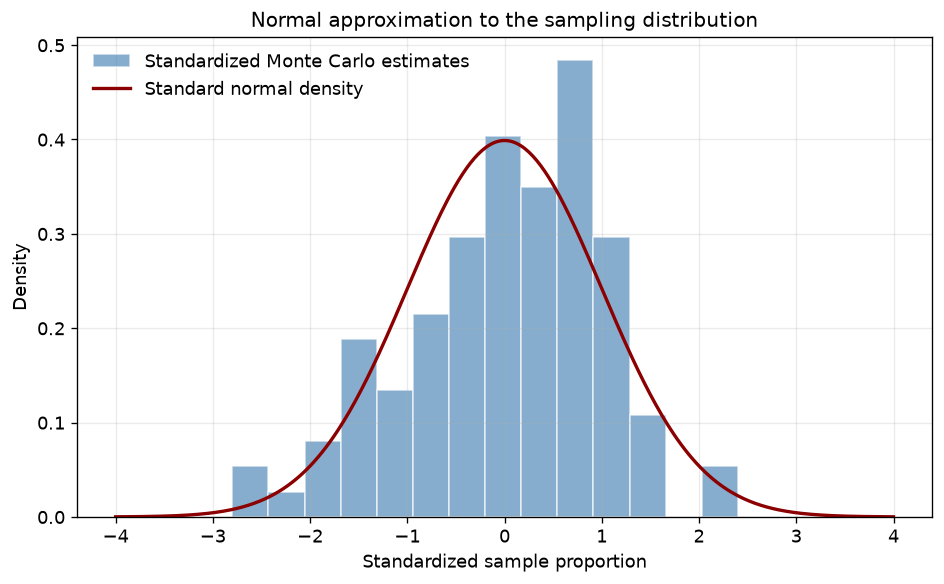

In [14]:
from scipy.stats import norm

n = 100
p = 0.50

subset = sampling_data.loc[
    sampling_data["sample_size"] == n
]

estimates = subset["p_hat"].to_numpy()

theoretical_se = np.sqrt(p * (1 - p) / n)

z_scores = (estimates - p) / theoretical_se

normal_diagnostics = pd.DataFrame({
    "replication": np.arange(1, len(z_scores) + 1),
    "standardized_estimate": z_scores
})

normal_diagnostics.to_csv(
    RESULTS_DIR / "E02_normal_approximation.csv",
    index=False
)

z_grid = np.linspace(-4, 4, 400)

fig, ax = plt.subplots()

ax.hist(
    z_scores,
    bins=14,
    density=True,
    color="steelblue",
    alpha=0.65,
    edgecolor="white",
    label="Standardized Monte Carlo estimates"
)

ax.plot(
    z_grid,
    norm.pdf(z_grid),
    color="darkred",
    linewidth=2,
    label="Standard normal density"
)

ax.set(
    xlabel="Standardized sample proportion",
    ylabel="Density",
    title="Normal approximation to the sampling distribution"
)

ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E02_Figure07_NormalApproximation.png")
fig.savefig(FIGS_DIR / "E02_Figure07_NormalApproximation.pdf")

plt.show()

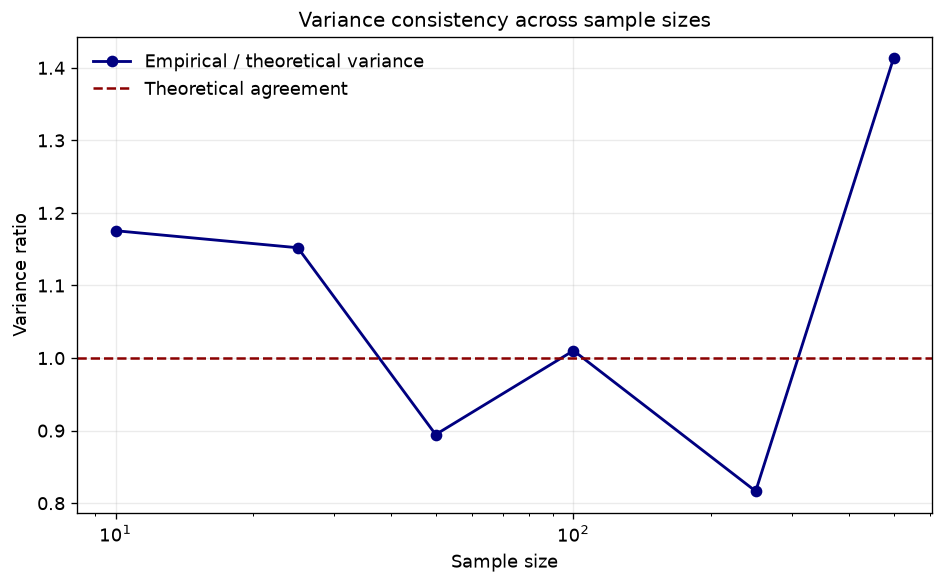

,sample_size,empirical_mean,theoretical_mean,standardized_mean_error,empirical_variance,theoretical_variance,variance_ratio
0,10,0.49700,0.5,-0.189737,0.029385,0.0250,1.175394
1,25,0.51000,0.5,1.000000,0.011519,0.0100,1.151919
2,50,0.48940,0.5,-1.499066,0.004472,0.0050,0.894473
3,100,0.50000,0.5,0.000000,0.002525,0.0025,1.010101
4,250,0.49852,0.5,-0.468017,0.000816,0.0010,0.816373
5,500,0.49746,0.5,-1.135923,0.000706,0.0005,1.412825


In [15]:
diagnostic_records = []

for n in SAMPLE_SIZES:

    subset = sampling_data.loc[
        sampling_data["sample_size"] == n,
        "p_hat"
    ].to_numpy()

    empirical_mean = subset.mean()
    empirical_variance = subset.var(ddof=1)

    theoretical_mean = p
    theoretical_variance = p * (1 - p) / n

    # Standard error of the simulated sample mean
    mc_standard_error = np.sqrt(
        theoretical_variance / len(subset)
    )

    standardized_mean_error = (
        empirical_mean - theoretical_mean
    ) / mc_standard_error

    variance_ratio = (
        empirical_variance / theoretical_variance
    )

    diagnostic_records.append({
        "sample_size": int(n),
        "empirical_mean": empirical_mean,
        "theoretical_mean": theoretical_mean,
        "standardized_mean_error": standardized_mean_error,
        "empirical_variance": empirical_variance,
        "theoretical_variance": theoretical_variance,
        "variance_ratio": variance_ratio
    })

sampling_diagnostics = pd.DataFrame(diagnostic_records)

assert np.isfinite(
    sampling_diagnostics.select_dtypes(include="number")
    .to_numpy()
).all()

assert (
    sampling_diagnostics["empirical_variance"] >= 0
).all()

sampling_diagnostics.to_csv(
    RESULTS_DIR / "E02_validation_diagnostics.csv",
    index=False
)

fig, ax = plt.subplots()

ax.plot(
    sampling_diagnostics["sample_size"],
    sampling_diagnostics["variance_ratio"],
    marker="o",
    linewidth=1.7,
    color="navy",
    label="Empirical / theoretical variance"
)

ax.axhline(
    1.0,
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label="Theoretical agreement"
)

ax.set(
    xlabel="Sample size",
    ylabel="Variance ratio",
    title="Variance consistency across sample sizes"
)

ax.set_xscale("log")
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E02_Figure08_VarianceValidation.png")
fig.savefig(FIGS_DIR / "E02_Figure08_VarianceValidation.pdf")

plt.show()

sampling_diagnostics

In [16]:
from scipy.stats import norm, beta

def binomial_intervals(k, n, alpha=0.05):
    """Compute Wald, Wilson and Clopper-Pearson intervals."""

    k = np.asarray(k, dtype=int)

    if not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError("n must be a positive integer.")

    if np.any((k < 0) | (k > n)):
        raise ValueError("Success counts must be between 0 and n.")

    if not 0 < alpha < 1:
        raise ValueError("alpha must be between 0 and 1.")

    p_hat = k / n
    z = norm.ppf(1 - alpha / 2)

    # Wald interval
    se = np.sqrt(p_hat * (1 - p_hat) / n)

    wald_lower = np.clip(p_hat - z * se, 0, 1)
    wald_upper = np.clip(p_hat + z * se, 0, 1)

    # Wilson score interval
    denominator = 1 + z**2 / n

    center = (
        p_hat + z**2 / (2 * n)
    ) / denominator

    margin = (
        z / denominator
        * np.sqrt(
            p_hat * (1 - p_hat) / n
            + z**2 / (4 * n**2)
        )
    )

    wilson_lower = np.clip(center - margin, 0, 1)
    wilson_upper = np.clip(center + margin, 0, 1)

    # Clopper-Pearson exact interval
    cp_lower = np.zeros(k.shape, dtype=float)
    cp_upper = np.ones(k.shape, dtype=float)

    lower_mask = k > 0
    upper_mask = k < n

    cp_lower[lower_mask] = beta.ppf(
        alpha / 2,
        k[lower_mask],
        n - k[lower_mask] + 1
    )

    cp_upper[upper_mask] = beta.ppf(
        1 - alpha / 2,
        k[upper_mask] + 1,
        n - k[upper_mask]
    )

    return {
        "Wald": (wald_lower, wald_upper),
        "Wilson": (wilson_lower, wilson_upper),
        "Clopper-Pearson": (cp_lower, cp_upper)
    }


# Boundary and mathematical validation
for n in [10, 25, 50, 100]:

    counts = np.arange(n + 1)

    intervals = binomial_intervals(
        counts, n, ALPHA
    )

    for method, (lower, upper) in intervals.items():

        assert np.all(np.isfinite(lower))
        assert np.all(np.isfinite(upper))
        assert np.all(lower >= 0)
        assert np.all(upper <= 1)
        assert np.all(lower <= upper)

        # Symmetry under success/failure exchange
        assert np.allclose(
            lower,
            1 - upper[::-1],
            atol=1e-12
        )

    assert intervals["Wald"][0][0] == 0
    assert intervals["Wald"][1][0] == 0
    assert intervals["Wald"][0][-1] == 1
    assert intervals["Wald"][1][-1] == 1

In [17]:
coverage_records = []

for n in SAMPLE_SIZES:

    for j, p_true in enumerate(PROBABILITIES):

        generator = np.random.default_rng(
            RANDOM_SEED + 3000 + int(n) * 10 + j
        )

        counts = generator.binomial(
            n=int(n),
            p=float(p_true),
            size=N_REPLICATIONS
        )

        intervals = binomial_intervals(
            counts,
            int(n),
            ALPHA
        )

        for method, (lower, upper) in intervals.items():

            covered = (
                (lower <= p_true) &
                (p_true <= upper)
            )

            widths = upper - lower

            coverage_records.append({
                "sample_size": int(n),
                "p_true": float(p_true),
                "method": method,
                "replications": N_REPLICATIONS,
                "coverage": covered.mean(),
                "mean_width": widths.mean()
            })

coverage_data = pd.DataFrame(coverage_records)

assert coverage_data["coverage"].between(0, 1).all()
assert coverage_data["mean_width"].between(0, 1).all()

assert len(coverage_data) == (
    len(SAMPLE_SIZES) *
    len(PROBABILITIES) * 3
)

coverage_data.to_csv(
    RESULTS_DIR / "E03_preliminary_coverage.csv",
    index=False
)

coverage_data

,sample_size,p_true,method,replications,coverage,mean_width
0,10,0.1,Wald,100,0.65,0.260712
1,10,0.1,Wilson,100,0.87,0.378326
2,10,0.1,Clopper-Pearson,100,0.97,0.435122
3,10,0.3,Wald,100,0.85,0.512931
4,10,0.3,Wilson,100,0.94,0.477755
...,...,...,...,...,...,...
85,500,0.7,Wilson,100,0.92,0.080056
86,500,0.7,Clopper-Pearson,100,0.92,0.082119
87,500,0.9,Wald,100,0.93,0.052389
88,500,0.9,Wilson,100,0.94,0.052548


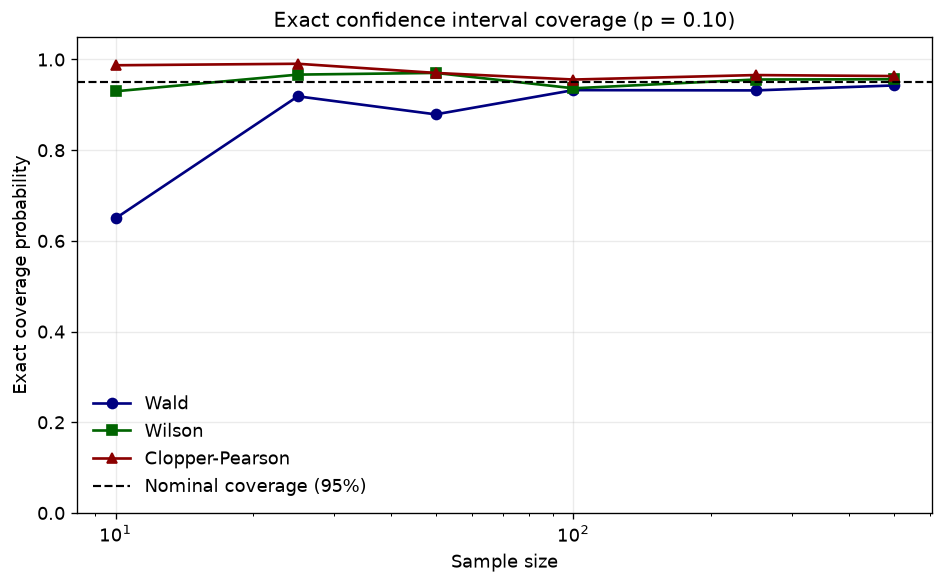

,sample_size,p_true,method,replications,coverage,mean_width,exact_coverage,mc_absolute_error,mc_standard_error
0,10,0.1,Wald,100,0.65,0.260712,0.649687,0.000313,0.047707
1,10,0.1,Wilson,100,0.87,0.378326,0.929809,0.059809,0.025547
2,10,0.1,Clopper-Pearson,100,0.97,0.435122,0.987205,0.017205,0.011239
3,10,0.3,Wald,100,0.85,0.512931,0.840100,0.009900,0.036651
4,10,0.3,Wilson,100,0.94,0.477755,0.924403,0.015597,0.026435
...,...,...,...,...,...,...,...,...,...
85,500,0.7,Wilson,100,0.92,0.080056,0.954713,0.034713,0.020793
86,500,0.7,Clopper-Pearson,100,0.92,0.082119,0.954713,0.034713,0.020793
87,500,0.9,Wald,100,0.93,0.052389,0.942689,0.012689,0.023244
88,500,0.9,Wilson,100,0.94,0.052548,0.956314,0.016314,0.020439


In [18]:
exact_records = []

for n in SAMPLE_SIZES:

    counts = np.arange(int(n) + 1)

    intervals = binomial_intervals(
        counts, int(n), ALPHA
    )

    for p_true in PROBABILITIES:

        probabilities = binom.pmf(
            counts, int(n), float(p_true)
        )

        for method, (lower, upper) in intervals.items():

            covered = (
                (lower <= p_true) &
                (p_true <= upper)
            )

            exact_coverage = probabilities[covered].sum()

            exact_records.append({
                "sample_size": int(n),
                "p_true": float(p_true),
                "method": method,
                "exact_coverage": exact_coverage
            })

exact_coverage_data = pd.DataFrame(exact_records)

coverage_comparison = coverage_data.merge(
    exact_coverage_data,
    on=["sample_size", "p_true", "method"],
    validate="one_to_one"
)

coverage_comparison["mc_absolute_error"] = np.abs(
    coverage_comparison["coverage"] -
    coverage_comparison["exact_coverage"]
)

coverage_comparison["mc_standard_error"] = np.sqrt(
    coverage_comparison["exact_coverage"] *
    (1 - coverage_comparison["exact_coverage"]) /
    N_REPLICATIONS
)

assert coverage_comparison[
    "exact_coverage"
].between(0, 1).all()

coverage_comparison.to_csv(
    RESULTS_DIR / "E03_exact_coverage_validation.csv",
    index=False
)

# Exact coverage comparison at p = 0.10
plot_data = exact_coverage_data.loc[
    np.isclose(exact_coverage_data["p_true"], 0.10)
]

fig, ax = plt.subplots()

styles = {
    "Wald": ("navy", "o"),
    "Wilson": ("darkgreen", "s"),
    "Clopper-Pearson": ("darkred", "^")
}

for method, (color, marker) in styles.items():

    subset = plot_data.loc[
        plot_data["method"] == method
    ].sort_values("sample_size")

    ax.plot(
        subset["sample_size"],
        subset["exact_coverage"],
        marker=marker,
        linewidth=1.6,
        color=color,
        label=method
    )

ax.axhline(
    CONFIDENCE_LEVEL,
    linestyle="--",
    color="black",
    linewidth=1.3,
    label="Nominal coverage (95%)"
)

ax.set(
    xlabel="Sample size",
    ylabel="Exact coverage probability",
    title="Exact confidence interval coverage (p = 0.10)"
)

ax.set_xscale("log")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIGS_DIR / "E03_Figure09_ExactCoverage.png"
)
fig.savefig(
    FIGS_DIR / "E03_Figure09_ExactCoverage.pdf"
)

plt.show()

coverage_comparison

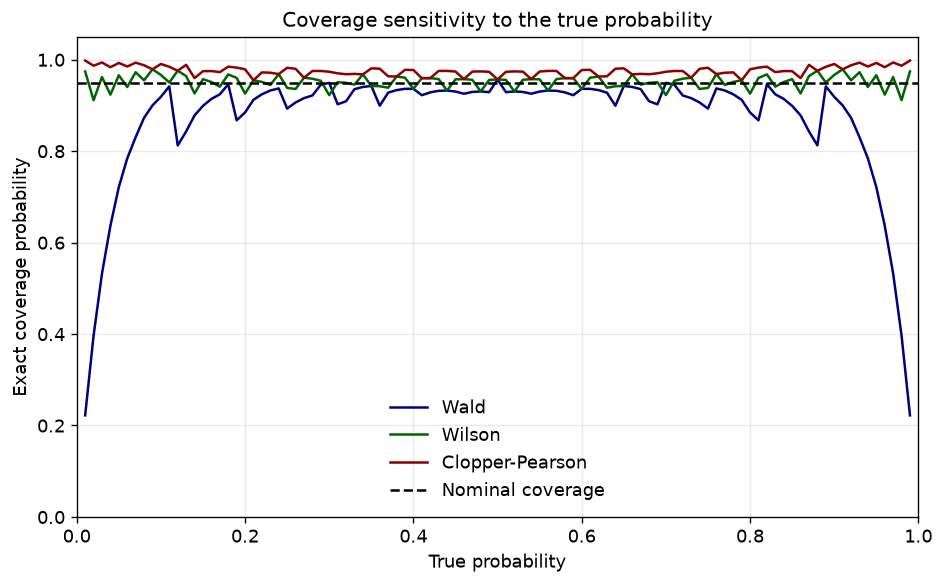

In [19]:
n = 25
p_grid = np.linspace(0.01, 0.99, 99)
counts = np.arange(n + 1)

intervals = binomial_intervals(counts, n, ALPHA)

coverage_records_grid = []

for p_true in p_grid:

    pmf = binom.pmf(counts, n, p_true)

    for method, (lower, upper) in intervals.items():

        coverage = pmf[
            (lower <= p_true) & (p_true <= upper)
        ].sum()

        coverage_records_grid.append({
            "sample_size": n,
            "p_true": p_true,
            "method": method,
            "exact_coverage": coverage
        })

coverage_grid = pd.DataFrame(coverage_records_grid)

assert coverage_grid["exact_coverage"].between(0, 1).all()

coverage_grid.to_csv(
    RESULTS_DIR / "E03_coverage_probability_grid.csv",
    index=False
)

fig, ax = plt.subplots()

for method, color in [
    ("Wald", "navy"),
    ("Wilson", "darkgreen"),
    ("Clopper-Pearson", "darkred")
]:

    subset = coverage_grid[
        coverage_grid["method"] == method
    ]

    ax.plot(
        subset["p_true"],
        subset["exact_coverage"],
        color=color,
        linewidth=1.5,
        label=method
    )

ax.axhline(
    CONFIDENCE_LEVEL,
    color="black",
    linestyle="--",
    label="Nominal coverage"
)

ax.set(
    xlabel="True probability",
    ylabel="Exact coverage probability",
    title="Coverage sensitivity to the true probability"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E03_Figure10_CoverageSensitivity.png")
fig.savefig(FIGS_DIR / "E03_Figure10_CoverageSensitivity.pdf")

plt.show()

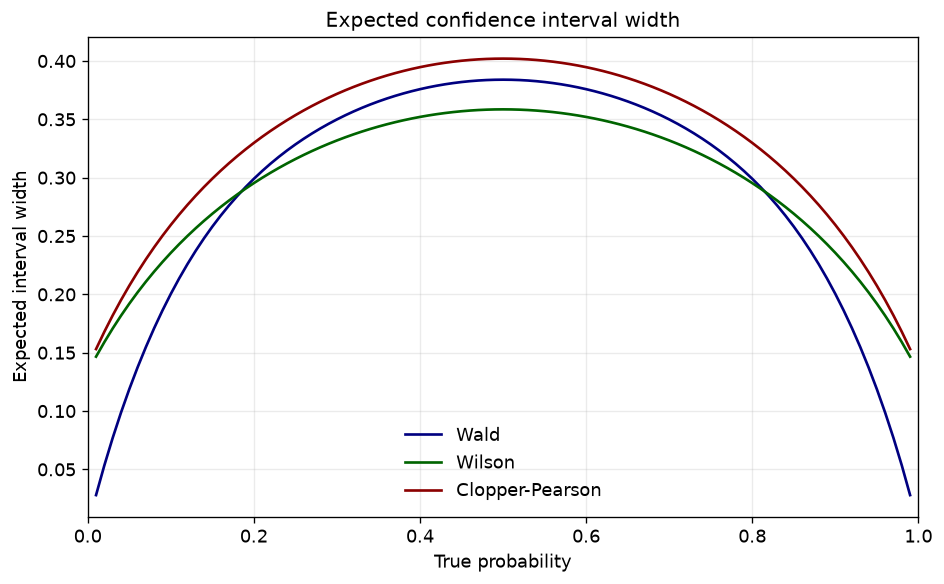

In [20]:
n = 25
counts = np.arange(n + 1)
intervals = binomial_intervals(counts, n, ALPHA)

width_records = []

for p_true in p_grid:

    pmf = binom.pmf(counts, n, p_true)

    for method, (lower, upper) in intervals.items():

        expected_width = np.sum(
            pmf * (upper - lower)
        )

        width_records.append({
            "sample_size": n,
            "p_true": p_true,
            "method": method,
            "expected_width": expected_width
        })

width_data = pd.DataFrame(width_records)

assert width_data["expected_width"].between(0, 1).all()

width_data.to_csv(
    RESULTS_DIR / "E03_expected_interval_width.csv",
    index=False
)

fig, ax = plt.subplots()

for method, color in [
    ("Wald", "navy"),
    ("Wilson", "darkgreen"),
    ("Clopper-Pearson", "darkred")
]:

    subset = width_data[
        width_data["method"] == method
    ]

    ax.plot(
        subset["p_true"],
        subset["expected_width"],
        color=color,
        linewidth=1.6,
        label=method
    )

ax.set(
    xlabel="True probability",
    ylabel="Expected interval width",
    title="Expected confidence interval width"
)

ax.set_xlim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E03_Figure11_ExpectedWidth.png")
fig.savefig(FIGS_DIR / "E03_Figure11_ExpectedWidth.pdf")

plt.show()

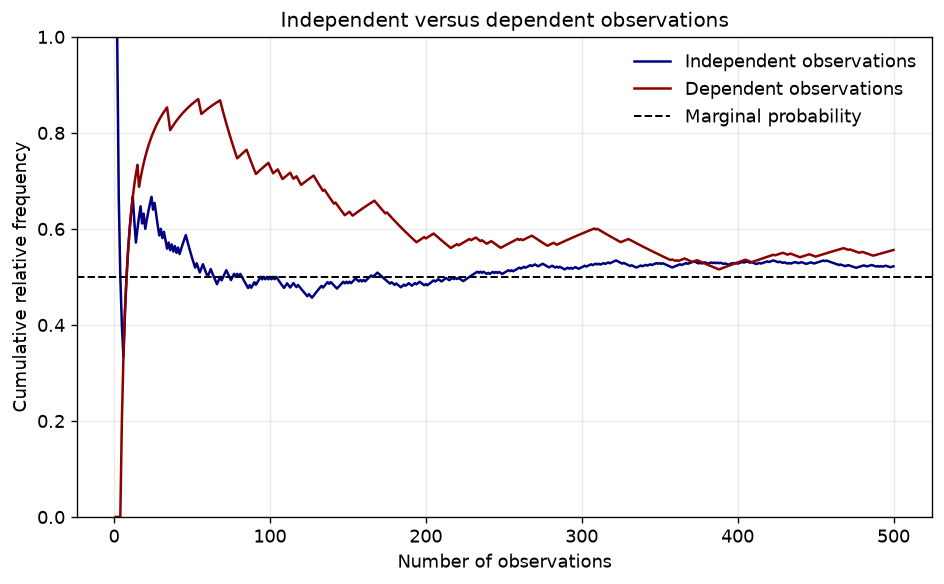

In [21]:
n = 500
p = 0.50
rho = 0.70

generator = np.random.default_rng(RANDOM_SEED + 4000)

# Independent Bernoulli sequence
independent = generator.binomial(1, p, size=n)

# Stationary binary Markov chain
dependent = np.empty(n, dtype=int)
dependent[0] = generator.binomial(1, p)

p11 = p + rho * (1 - p)
p01 = p * (1 - rho)

for t in range(1, n):

    transition_p = (
        p11 if dependent[t - 1] == 1 else p01
    )

    dependent[t] = generator.binomial(1, transition_p)

assert np.all(np.isin(dependent, [0, 1]))
assert np.isclose(p01 / (1 - p11 + p01), p)
assert np.isclose(p11 - p01, rho)

dependence_data = pd.DataFrame({
    "observation": np.arange(1, n + 1),
    "independent": independent,
    "dependent": dependent
})

dependence_data.to_csv(
    RESULTS_DIR / "E04_independent_dependent_sequences.csv",
    index=False
)

fig, ax = plt.subplots()

ax.plot(
    dependence_data["observation"],
    dependence_data["independent"].cumsum() /
    dependence_data["observation"],
    color="navy",
    label="Independent observations"
)

ax.plot(
    dependence_data["observation"],
    dependence_data["dependent"].cumsum() /
    dependence_data["observation"],
    color="darkred",
    label="Dependent observations"
)

ax.axhline(
    p,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Marginal probability"
)

ax.set(
    xlabel="Number of observations",
    ylabel="Cumulative relative frequency",
    title="Independent versus dependent observations"
)

ax.set_ylim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E04_Figure12_Dependence.png")
fig.savefig(FIGS_DIR / "E04_Figure12_Dependence.pdf")

plt.show()

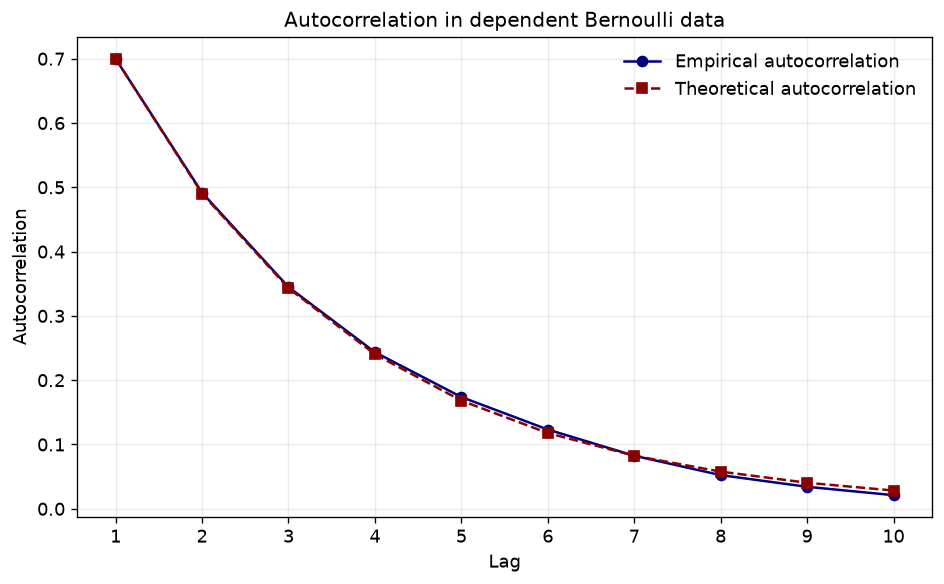

,lag,empirical_acf,theoretical_acf
0,1,0.699760,0.700000
1,2,0.491526,0.490000
2,3,0.344708,0.343000
3,4,0.243427,0.240100
4,5,0.173657,0.168070
5,6,0.123117,0.117649
6,7,0.082353,0.082354
7,8,0.052236,0.057648
8,9,0.034053,0.040354
9,10,0.021020,0.028248


In [22]:
n = 500
n_rep = N_REPLICATIONS
max_lag = 10

generator = np.random.default_rng(RANDOM_SEED + 4100)

chains = np.empty((n_rep, n), dtype=int)
chains[:, 0] = generator.binomial(1, p, size=n_rep)

for t in range(1, n):

    transition_p = np.where(
        chains[:, t - 1] == 1,
        p11,
        p01
    )

    chains[:, t] = generator.binomial(1, transition_p)

# Theoretical-mean-centered covariance estimates
centered = chains - p
variance_theoretical = p * (1 - p)

acf_records = []

for lag in range(1, max_lag + 1):

    empirical_acf = np.mean(
        centered[:, :-lag] * centered[:, lag:]
    ) / variance_theoretical

    acf_records.append({
        "lag": lag,
        "empirical_acf": empirical_acf,
        "theoretical_acf": rho**lag
    })

acf_data = pd.DataFrame(acf_records)

assert np.isfinite(acf_data.to_numpy()).all()

acf_data.to_csv(
    RESULTS_DIR / "E04_autocorrelation_diagnostics.csv",
    index=False
)

fig, ax = plt.subplots()

ax.plot(
    acf_data["lag"],
    acf_data["empirical_acf"],
    marker="o",
    color="navy",
    label="Empirical autocorrelation"
)

ax.plot(
    acf_data["lag"],
    acf_data["theoretical_acf"],
    marker="s",
    linestyle="--",
    color="darkred",
    label="Theoretical autocorrelation"
)

ax.set(
    xlabel="Lag",
    ylabel="Autocorrelation",
    title="Autocorrelation in dependent Bernoulli data"
)

ax.set_xticks(np.arange(1, max_lag + 1))
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E04_Figure13_Autocorrelation.png")
fig.savefig(FIGS_DIR / "E04_Figure13_Autocorrelation.pdf")

plt.show()

acf_data

In [23]:
n = 500
n_rep = N_REPLICATIONS
p_true = 0.50

generator = np.random.default_rng(RANDOM_SEED + 4200)

# Independent samples
iid_counts = generator.binomial(
    n, p_true, size=n_rep
)

# Dependent samples from the Markov chains
dependent_counts = chains.sum(axis=1)

coverage_dependence_records = []

for scenario, counts in [
    ("Independent", iid_counts),
    ("Dependent", dependent_counts)
]:

    lower, upper = binomial_intervals(
        counts, n, ALPHA
    )["Wilson"]

    estimates = counts / n

    coverage_dependence_records.append({
        "scenario": scenario,
        "sample_size": n,
        "mean_estimate": estimates.mean(),
        "empirical_variance": estimates.var(ddof=1),
        "coverage": np.mean(
            (lower <= p_true) & (p_true <= upper)
        ),
        "mean_interval_width": np.mean(upper - lower)
    })

dependence_coverage = pd.DataFrame(
    coverage_dependence_records
)

# Reference variances
iid_variance = p_true * (1 - p_true) / n

markov_variance = (
    p_true * (1 - p_true) / n**2
    * (
        n + 2 * sum(
            (n - h) * rho**h
            for h in range(1, n)
        )
    )
)

dependence_coverage["theoretical_variance"] = [
    iid_variance,
    markov_variance
]

assert dependence_coverage["coverage"].between(0, 1).all()
assert markov_variance >= iid_variance

dependence_coverage.to_csv(
    RESULTS_DIR / "E04_dependence_coverage.csv",
    index=False
)

dependence_coverage

,scenario,sample_size,mean_estimate,empirical_variance,coverage,mean_interval_width,theoretical_variance
0,Independent,500,0.50392,0.000488,0.96,0.087231,0.000500
1,Dependent,500,0.50894,0.002532,0.63,0.086866,0.002818


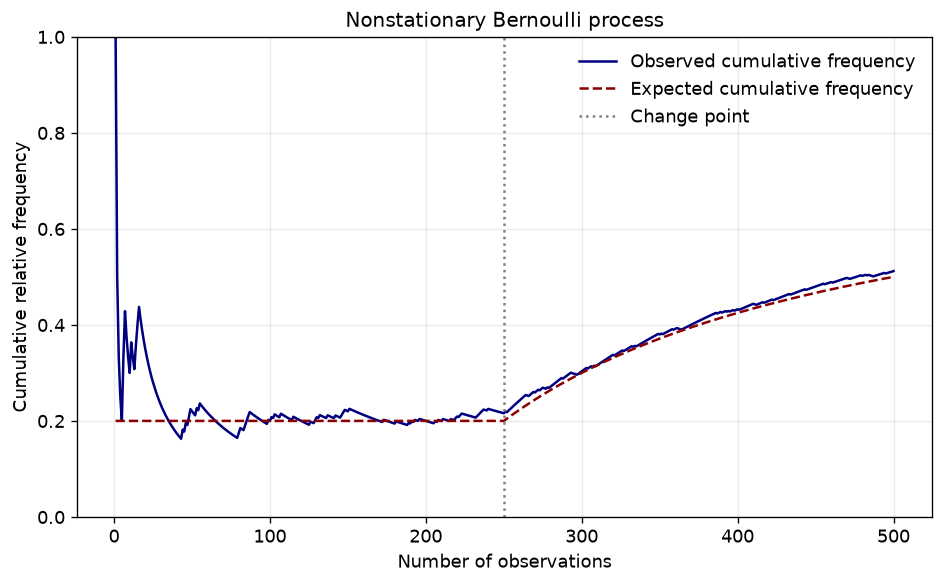

In [24]:
n = 500
change_point = 250

p_sequence = np.concatenate([
    np.full(change_point, 0.20),
    np.full(n - change_point, 0.80)
])

generator = np.random.default_rng(RANDOM_SEED + 4300)

observations = generator.binomial(1, p_sequence)

sample_index = np.arange(1, n + 1)

observed_frequency = (
    np.cumsum(observations) / sample_index
)

expected_frequency = (
    np.cumsum(p_sequence) / sample_index
)

nonstationary_data = pd.DataFrame({
    "observation": sample_index,
    "probability": p_sequence,
    "outcome": observations,
    "observed_frequency": observed_frequency,
    "expected_frequency": expected_frequency
})

assert np.isclose(p_sequence.mean(), 0.50)
assert np.all(np.isin(observations, [0, 1]))

nonstationary_data.to_csv(
    RESULTS_DIR / "E04_nonstationary_process.csv",
    index=False
)

fig, ax = plt.subplots()

ax.plot(
    sample_index,
    observed_frequency,
    color="navy",
    label="Observed cumulative frequency"
)

ax.plot(
    sample_index,
    expected_frequency,
    color="darkred",
    linestyle="--",
    label="Expected cumulative frequency"
)

ax.axvline(
    change_point,
    color="gray",
    linestyle=":",
    label="Change point"
)

ax.set(
    xlabel="Number of observations",
    ylabel="Cumulative relative frequency",
    title="Nonstationary Bernoulli process"
)

ax.set_ylim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E04_Figure14_Nonstationarity.png")
fig.savefig(FIGS_DIR / "E04_Figure14_Nonstationarity.pdf")

plt.show()

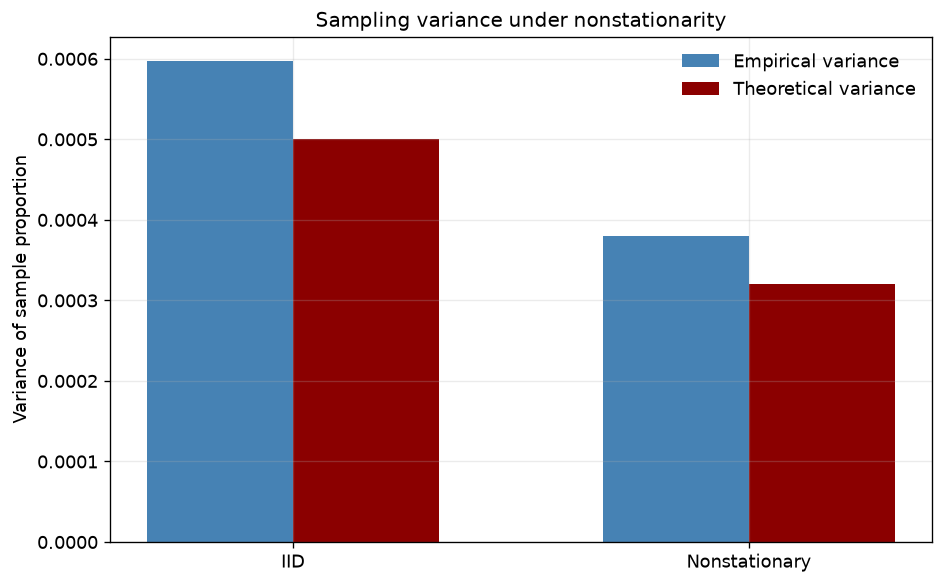

,scenario,empirical_variance,theoretical_variance,variance_ratio
0,IID,0.000597,0.00050,1.194712
1,Nonstationary,0.000380,0.00032,1.188307


In [25]:
n = len(p_sequence)
n_rep = N_REPLICATIONS

generator = np.random.default_rng(RANDOM_SEED + 4400)

iid_samples = generator.binomial(
    1, 0.50, size=(n_rep, n)
)

nonstationary_samples = generator.binomial(
    1, p_sequence, size=(n_rep, n)
)

iid_estimates = iid_samples.mean(axis=1)
nonstationary_estimates = nonstationary_samples.mean(axis=1)

theoretical_iid_variance = 0.25 / n

theoretical_nonstationary_variance = (
    np.sum(p_sequence * (1 - p_sequence)) / n**2
)

variance_comparison = pd.DataFrame({
    "scenario": ["IID", "Nonstationary"],
    "empirical_variance": [
        iid_estimates.var(ddof=1),
        nonstationary_estimates.var(ddof=1)
    ],
    "theoretical_variance": [
        theoretical_iid_variance,
        theoretical_nonstationary_variance
    ]
})

variance_comparison["variance_ratio"] = (
    variance_comparison["empirical_variance"] /
    variance_comparison["theoretical_variance"]
)

assert (
    theoretical_nonstationary_variance
    < theoretical_iid_variance
)

variance_comparison.to_csv(
    RESULTS_DIR / "E04_nonstationary_variance.csv",
    index=False
)

fig, ax = plt.subplots()

x = np.arange(2)
width = 0.32

ax.bar(
    x - width / 2,
    variance_comparison["empirical_variance"],
    width,
    color="steelblue",
    label="Empirical variance"
)

ax.bar(
    x + width / 2,
    variance_comparison["theoretical_variance"],
    width,
    color="darkred",
    label="Theoretical variance"
)

ax.set_xticks(x)
ax.set_xticklabels(variance_comparison["scenario"])

ax.set(
    ylabel="Variance of sample proportion",
    title="Sampling variance under nonstationarity"
)

ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E04_Figure15_NonstationaryVariance.png")
fig.savefig(FIGS_DIR / "E04_Figure15_NonstationaryVariance.pdf")

plt.show()

variance_comparison

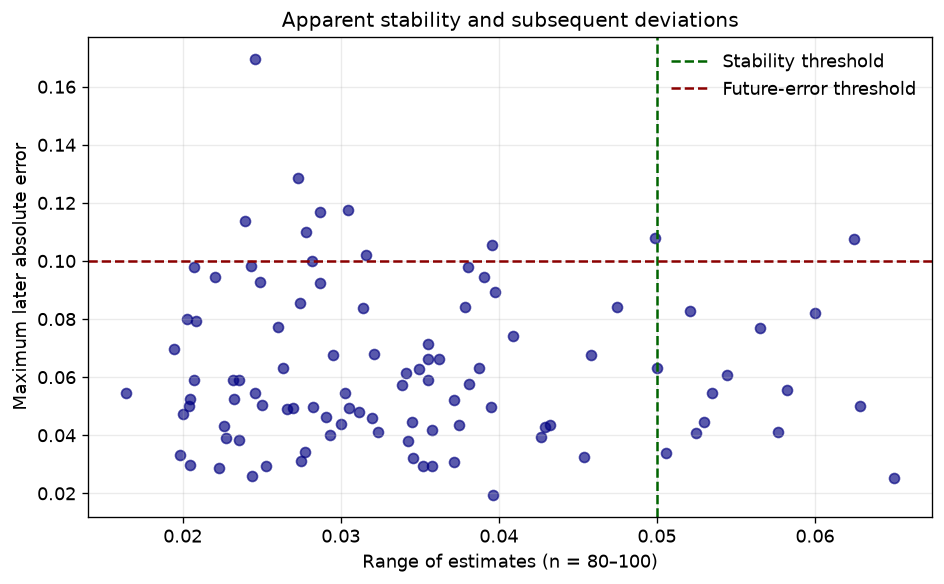

apparently_stable       0.87
subsequent_deviation    0.10
both_conditions         0.09
dtype: float64

In [26]:
n = 500
n_rep = N_REPLICATIONS
p_true = 0.50

generator = np.random.default_rng(RANDOM_SEED + 5000)

samples = generator.binomial(
    1, p_true, size=(n_rep, n)
)

sample_index = np.arange(1, n + 1)

trajectories = (
    np.cumsum(samples, axis=1) / sample_index
)

# Predefined diagnostic windows
stability_window = trajectories[:, 79:100]
future_window = trajectories[:, 100:500]

stability_range = np.ptp(stability_window, axis=1)

future_max_error = np.max(
    np.abs(future_window - p_true),
    axis=1
)

stability_threshold = 0.05
future_error_threshold = 0.10

apparently_stable = (
    stability_range <= stability_threshold
)

subsequent_deviation = (
    future_max_error > future_error_threshold
)

stability_diagnostics = pd.DataFrame({
    "replication": np.arange(1, n_rep + 1),
    "stability_range": stability_range,
    "future_max_error": future_max_error,
    "apparently_stable": apparently_stable,
    "subsequent_deviation": subsequent_deviation,
    "both_conditions": (
        apparently_stable & subsequent_deviation
    )
})

stability_diagnostics.to_csv(
    RESULTS_DIR / "E05_apparent_stability.csv",
    index=False
)

fig, ax = plt.subplots()

ax.scatter(
    stability_range,
    future_max_error,
    color="navy",
    alpha=0.65
)

ax.axvline(
    stability_threshold,
    color="darkgreen",
    linestyle="--",
    label="Stability threshold"
)

ax.axhline(
    future_error_threshold,
    color="darkred",
    linestyle="--",
    label="Future-error threshold"
)

ax.set(
    xlabel="Range of estimates (n = 80–100)",
    ylabel="Maximum later absolute error",
    title="Apparent stability and subsequent deviations"
)

ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E05_Figure16_ApparentStability.png")
fig.savefig(FIGS_DIR / "E05_Figure16_ApparentStability.pdf")

plt.show()

stability_diagnostics[
    ["apparently_stable",
     "subsequent_deviation",
     "both_conditions"]
].mean()

In [27]:
n = 500
n_rep = N_REPLICATIONS
p_null = 0.50
min_n = 20

generator = np.random.default_rng(RANDOM_SEED + 5100)

samples = generator.binomial(
    1, p_null, size=(n_rep, n)
)

cumulative_successes = np.cumsum(samples, axis=1)

sample_sizes = np.arange(min_n, n + 1)

counts = cumulative_successes[:, min_n - 1:]

z = norm.ppf(1 - ALPHA / 2)

p_hat = counts / sample_sizes

denominator = 1 + z**2 / sample_sizes

center = (
    p_hat + z**2 / (2 * sample_sizes)
) / denominator

margin = (
    z / denominator
    * np.sqrt(
        p_hat * (1 - p_hat) / sample_sizes
        + z**2 / (4 * sample_sizes**2)
    )
)

lower = center - margin
upper = center + margin

# Rejection of the true null value
rejections = (
    (lower > p_null) | (upper < p_null)
)

fixed_rejection = rejections[:, -1]

sequential_rejection = rejections.any(axis=1)

first_rejection = np.where(
    sequential_rejection,
    sample_sizes[np.argmax(rejections, axis=1)],
    np.nan
)

stopping_results = pd.DataFrame({
    "replication": np.arange(1, n_rep + 1),
    "fixed_rejection": fixed_rejection,
    "sequential_rejection": sequential_rejection,
    "first_rejection_n": first_rejection
})

assert np.all(
    ~fixed_rejection | sequential_rejection
)

stopping_results.to_csv(
    RESULTS_DIR / "E05_optional_stopping.csv",
    index=False
)

stopping_summary = pd.DataFrame({
    "procedure": ["Fixed sample", "Repeated testing"],
    "rejection_rate": [
        fixed_rejection.mean(),
        sequential_rejection.mean()
    ],
    "replications": n_rep
})

stopping_summary.to_csv(
    RESULTS_DIR / "E05_optional_stopping_summary.csv",
    index=False
)

stopping_summary

,procedure,rejection_rate,replications
0,Fixed sample,0.06,100
1,Repeated testing,0.40,100


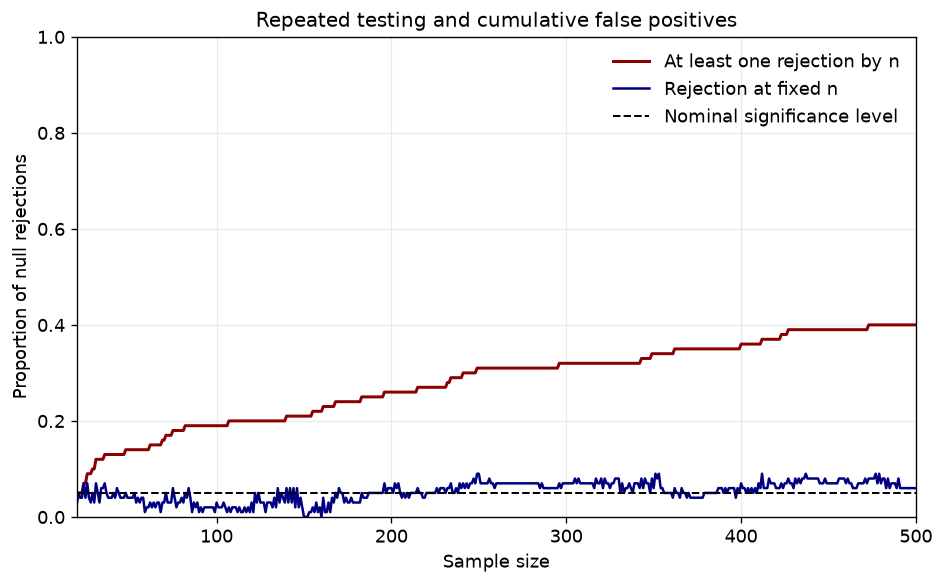

,sample_size,cumulative_rejection_rate,fixed_sample_rejection_rate
476,496,0.4,0.06
477,497,0.4,0.06
478,498,0.4,0.06
479,499,0.4,0.06
480,500,0.4,0.06


In [28]:
cumulative_rejections = np.maximum.accumulate(
    rejections, axis=1
)

cumulative_rejection_rate = (
    cumulative_rejections.mean(axis=0)
)

fixed_rejection_rate = rejections.mean(axis=0)

stopping_curve = pd.DataFrame({
    "sample_size": sample_sizes,
    "cumulative_rejection_rate": cumulative_rejection_rate,
    "fixed_sample_rejection_rate": fixed_rejection_rate
})

assert np.all(
    np.diff(cumulative_rejection_rate) >= -1e-12
)

assert np.all(
    cumulative_rejection_rate + 1e-12
    >= fixed_rejection_rate
)

stopping_curve.to_csv(
    RESULTS_DIR / "E05_stopping_rejection_curve.csv",
    index=False
)

fig, ax = plt.subplots()

ax.plot(
    sample_sizes,
    cumulative_rejection_rate,
    color="darkred",
    linewidth=1.8,
    label="At least one rejection by n"
)

ax.plot(
    sample_sizes,
    fixed_rejection_rate,
    color="navy",
    linewidth=1.5,
    label="Rejection at fixed n"
)

ax.axhline(
    ALPHA,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Nominal significance level"
)

ax.set(
    xlabel="Sample size",
    ylabel="Proportion of null rejections",
    title="Repeated testing and cumulative false positives"
)

ax.set_xlim(min_n, n)
ax.set_ylim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "E05_Figure17_OptionalStopping.png")
fig.savefig(FIGS_DIR / "E05_Figure17_OptionalStopping.pdf")

plt.show()

stopping_curve.tail()

In [29]:
def diagnostic_record(experiment, scenario, metric, value, reference=np.nan):
    return {
        "experiment": experiment,
        "scenario": scenario,
        "metric": metric,
        "value": float(value),
        "reference": float(reference)
    }


records = []

# E01 — Convergence reliability
for row in reliability_data.itertuples():
    records.append(diagnostic_record(
        "E01", f"n={row.sample_size}",
        "reliability",
        row.empirical_reliability,
        row.theoretical_reliability
    ))

# E02 — Sampling variance
for row in sampling_diagnostics.itertuples():
    records.append(diagnostic_record(
        "E02", f"n={row.sample_size}",
        "sampling_variance",
        row.empirical_variance,
        row.theoretical_variance
    ))

# E03 — Interval coverage
for row in coverage_comparison.itertuples():
    records.append(diagnostic_record(
        "E03",
        f"{row.method}, n={row.sample_size}, p={row.p_true:.2f}",
        "coverage",
        row.coverage,
        row.exact_coverage
    ))

# E04 — Dependence and nonstationarity
for row in dependence_coverage.itertuples():
    records.append(diagnostic_record(
        "E04", row.scenario,
        "sampling_variance",
        row.empirical_variance,
        row.theoretical_variance
    ))

for row in variance_comparison.itertuples():
    records.append(diagnostic_record(
        "E04", row.scenario,
        "nonstationary_variance",
        row.empirical_variance,
        row.theoretical_variance
    ))

# E05 — Optional stopping
for row in stopping_summary.itertuples():
    records.append(diagnostic_record(
        "E05", row.procedure,
        "false_positive_rate",
        row.rejection_rate,
        ALPHA if row.procedure == "Fixed sample" else np.nan
    ))

integrated_diagnostics = pd.DataFrame(records)

integrated_diagnostics["absolute_difference"] = np.abs(
    integrated_diagnostics["value"] -
    integrated_diagnostics["reference"]
)

integrated_diagnostics.to_csv(
    RESULTS_DIR / "Integrated_Diagnostics.csv",
    index=False
)

assert np.isfinite(integrated_diagnostics["value"]).all()

integrated_diagnostics.groupby(
    ["experiment", "metric"]
).agg(
    scenarios=("scenario", "count"),
    mean_absolute_difference=("absolute_difference", "mean"))

scenarios  mean_absolute_difference
experiment metric                                                     
E01        reliability                     6                  0.024760
E02        sampling_variance               6                  0.001141
E03        coverage                       90                  0.016367
E04        nonstationary_variance          2                  0.000079
           sampling_variance               2                  0.000149
E05        false_positive_rate             2                  0.010000

In [30]:
from scipy.stats import binomtest

validation_checks = {}

# E01 — Bernoulli sampling
x = simulate_bernoulli(100, 0.50, RANDOM_SEED)

validation_checks["E01_binary"] = np.isin(x, [0, 1]).all()

validation_checks["E01_reproducible"] = np.array_equal(
    x, simulate_bernoulli(100, 0.50, RANDOM_SEED)
)

# E02 — Binomial moments
n_check = 50
p_check = 0.30

validation_checks["E02_mean"] = np.isclose(
    binom.mean(n_check, p_check),
    n_check * p_check
)

validation_checks["E02_variance"] = np.isclose(
    binom.var(n_check, p_check),
    n_check * p_check * (1 - p_check)
)

# E03 — Interval consistency
k_check = np.arange(26)
ci = binomial_intervals(k_check, 25, ALPHA)

validation_checks["E03_bounds"] = all(
    np.all((lower >= 0) & (upper <= 1) & (lower <= upper))
    for lower, upper in ci.values()
)

# Clopper-Pearson validation against scipy
for k in [0, 1, 5, 12, 24, 25]:
    scipy_ci = binomtest(k, 25).proportion_ci(
        confidence_level=CONFIDENCE_LEVEL,
        method="exact"
    )

    lower, upper = ci["Clopper-Pearson"]

    assert np.isclose(lower[k], scipy_ci.low)
    assert np.isclose(upper[k], scipy_ci.high)

validation_checks["E03_exact_reference"] = True

# E04 — Markov stationary distribution and autocorrelation
validation_checks["E04_stationary"] = np.isclose(
    p01 / (1 - p11 + p01), p
)

validation_checks["E04_autocorrelation"] = np.isclose(
    p11 - p01, rho
)

validation_checks["E04_nonstationary_variance"] = np.isclose(
    theoretical_nonstationary_variance,
    np.sum(p_sequence * (1 - p_sequence)) / len(p_sequence)**2
)

# E05 — Optional stopping logical consistency
validation_checks["E05_stopping"] = np.all(
    ~fixed_rejection | sequential_rejection
)

validation_table = pd.DataFrame({
    "test": list(validation_checks.keys()),
    "passed": list(validation_checks.values())
})

validation_table.to_csv(
    RESULTS_DIR / "Mathematical_Validation.csv",
    index=False
)

assert validation_table["passed"].all()

validation_table

,test,passed
0,E01_binary,True
1,E01_reproducible,True
2,E02_mean,True
3,E02_variance,True
4,E03_bounds,True
5,E03_exact_reference,True
6,E04_stationary,True
7,E04_autocorrelation,True
8,E04_nonstationary_variance,True
9,E05_stopping,True


In [31]:
# E01 — Reproduce the convergence trajectory
reproduced_sample = simulate_bernoulli(
    500, 0.50, RANDOM_SEED
)

reproduced_frequency = (
    np.cumsum(reproduced_sample) / np.arange(1, 501)
)

saved_convergence = pd.read_csv(
    RESULTS_DIR / "E01_convergence_trajectory.csv"
)

e01_reproducible = np.allclose(
    reproduced_frequency,
    saved_convergence["relative_frequency"].to_numpy(),
    rtol=0,
    atol=1e-14
)

# E02 — Reproduce the sampling distributions
e02_checks = []

for n in SAMPLE_SIZES:

    generator = np.random.default_rng(
        RANDOM_SEED + 1000 + int(n)
    )

    reproduced_counts = generator.binomial(
        int(n), 0.50, size=N_REPLICATIONS
    )

    saved_counts = sampling_data.loc[
        sampling_data["sample_size"] == n,
        "successes"
    ].to_numpy()

    e02_checks.append(
        np.array_equal(reproduced_counts, saved_counts)
    )

# Independent generator reproducibility
generator_a = np.random.default_rng(RANDOM_SEED)
generator_b = np.random.default_rng(RANDOM_SEED)

generator_reproducible = np.array_equal(
    generator_a.binomial(1, 0.50, 1000),
    generator_b.binomial(1, 0.50, 1000)
)

reproducibility_table = pd.DataFrame({
    "test": [
        "E01_convergence",
        "E02_sampling_distributions",
        "Random_generator"
    ],
    "passed": [
        e01_reproducible,
        all(e02_checks),
        generator_reproducible
    ]
})

reproducibility_table.to_csv(
    RESULTS_DIR / "Reproducibility_Validation.csv",
    index=False
)

assert reproducibility_table["passed"].all()

reproducibility_table

,test,passed
0,E01_convergence,True
1,E02_sampling_distributions,True
2,Random_generator,True


In [32]:
from time import perf_counter

benchmark_sizes = [1000, 5000, 10000]
benchmark_replications = 100

performance_records = []

for n in benchmark_sizes:

    generator = np.random.default_rng(
        RANDOM_SEED + 6000 + n
    )

    start = perf_counter()

    samples = generator.binomial(
        1, 0.50,
        size=(benchmark_replications, n)
    )

    estimates = samples.mean(axis=1)
    errors = np.abs(estimates - 0.50)

    elapsed = perf_counter() - start

    performance_records.append({
        "sample_size": n,
        "replications": benchmark_replications,
        "total_observations": n * benchmark_replications,
        "elapsed_seconds": elapsed,
        "array_memory_mb": samples.nbytes / (1024**2),
        "mean_absolute_error": errors.mean()
    })

    del samples, estimates, errors

performance_table = pd.DataFrame(performance_records)

assert np.isfinite(
    performance_table.select_dtypes(include="number")
    .to_numpy()
).all()

performance_table.to_csv(
    RESULTS_DIR / "Computational_Performance.csv",
    index=False
)

performance_table

,sample_size,replications,total_observations,elapsed_seconds,array_memory_mb,mean_absolute_error
0,1000,100,100000,0.004303,0.762939,0.012240
1,5000,100,500000,0.018885,3.814697,0.005752
2,10000,100,1000000,0.033757,7.629395,0.003699


In [33]:
# Expected scientific figures
expected_figures = {
    f"Figure{i:02d}" for i in range(1, 18)
}

# Verify individual figures in both formats
figure_audit = []

for number in range(1, 18):

    matching_png = list(
        FIGS_DIR.glob(f"*Figure{number:02d}_*.png")
    )

    matching_pdf = list(
        FIGS_DIR.glob(f"*Figure{number:02d}_*.pdf")
    )

    figure_audit.append({
        "figure": f"Figure{number:02d}",
        "png_exists": len(matching_png) == 1,
        "pdf_exists": len(matching_pdf) == 1
    })

figure_audit = pd.DataFrame(figure_audit)

# Consolidate validation results
validation_summary = pd.DataFrame({
    "category": [
        "Mathematical validation",
        "Reproducibility",
        "Figure generation",
        "Numerical results",
        "Performance benchmark"
    ],
    "passed": [
        bool(validation_table["passed"].all()),
        bool(reproducibility_table["passed"].all()),
        bool(figure_audit[
            ["png_exists", "pdf_exists"]
        ].all().all()),
        (RESULTS_DIR / "Integrated_Diagnostics.csv").is_file(),
        (RESULTS_DIR / "Computational_Performance.csv").is_file()
    ]
})

figure_audit.to_csv(
    RESULTS_DIR / "Figure_Audit.csv",
    index=False
)

validation_summary.to_csv(
    RESULTS_DIR / "Preliminary_Validation_Summary.csv",
    index=False
)

assert validation_summary["passed"].all()

validation_summary

,category,passed
0,Mathematical validation,True
1,Reproducibility,True
2,Figure generation,True
3,Numerical results,True
4,Performance benchmark,True


Parte 2

In [34]:
from scipy.stats import binom, norm, binomtest
from time import perf_counter

VALIDATION_SIZES = np.array([1000, 10000, 100000])
VALIDATION_PROBABILITIES = np.array([0.10, 0.50, 0.90])

VALIDATION_REPLICATIONS = 500
VALIDATION_SEED = RANDOM_SEED + 10000

VALIDATION_EPSILON = ERROR_TOLERANCE
VALIDATION_ALPHA = ALPHA

assert np.all(VALIDATION_SIZES > 0)
assert np.all(np.diff(VALIDATION_SIZES) > 0)
assert np.all(
    (VALIDATION_PROBABILITIES > 0) &
    (VALIDATION_PROBABILITIES < 1)
)
assert VALIDATION_REPLICATIONS >= 100

validation_config = pd.DataFrame({
    "parameter": [
        "sample_sizes",
        "probabilities",
        "replications",
        "error_tolerance",
        "alpha",
        "seed"
    ],
    "value": [
        str(VALIDATION_SIZES.tolist()),
        str(VALIDATION_PROBABILITIES.tolist()),
        str(VALIDATION_REPLICATIONS),
        str(VALIDATION_EPSILON),
        str(VALIDATION_ALPHA),
        str(VALIDATION_SEED)
    ]
})

validation_config.to_csv(
    RESULTS_DIR / "Intermediate_Configuration.csv",
    index=False)

In [35]:
records = []

for i, n in enumerate(VALIDATION_SIZES):
    for j, p_true in enumerate(VALIDATION_PROBABILITIES):

        generator = np.random.default_rng(
            VALIDATION_SEED + 100 * i + j
        )

        successes = generator.binomial(
            n=int(n),
            p=float(p_true),
            size=VALIDATION_REPLICATIONS
        )

        estimates = successes / n

        for r, (k, estimate) in enumerate(
            zip(successes, estimates), start=1
        ):
            records.append({
                "sample_size": int(n),
                "p_true": float(p_true),
                "replication": r,
                "successes": int(k),
                "estimate": float(estimate),
                "absolute_error": abs(estimate - p_true)
            })

intermediate_data = pd.DataFrame(records)

assert len(intermediate_data) == (
    len(VALIDATION_SIZES) *
    len(VALIDATION_PROBABILITIES) *
    VALIDATION_REPLICATIONS
)

assert intermediate_data["estimate"].between(0, 1).all()

intermediate_data.to_csv(
    RESULTS_DIR / "Intermediate_Binomial_Data.csv",
    index=False)

In [36]:
convergence_records = []

for (n, p_true), group in intermediate_data.groupby(
    ["sample_size", "p_true"]
):

    errors = (
        group["estimate"].to_numpy() - p_true
    )

    squared_errors = errors**2
    absolute_errors = np.abs(errors)

    theoretical_rmse = np.sqrt(
        p_true * (1 - p_true) / n
    )

    rmse = np.sqrt(squared_errors.mean())

    convergence_records.append({
        "sample_size": int(n),
        "p_true": float(p_true),
        "bias": errors.mean(),
        "mc_se_bias": errors.std(ddof=1) / np.sqrt(len(errors)),
        "mae": absolute_errors.mean(),
        "mc_se_mae": absolute_errors.std(ddof=1) / np.sqrt(len(errors)),
        "rmse": rmse,
        "theoretical_rmse": theoretical_rmse,
        "rmse_ratio": rmse / theoretical_rmse
    })

intermediate_convergence = pd.DataFrame(convergence_records)

assert np.isfinite(
    intermediate_convergence.select_dtypes(
        include="number"
    ).to_numpy()
).all()

intermediate_convergence.to_csv(
    RESULTS_DIR / "Intermediate_Convergence_Diagnostics.csv",
    index=False
)

intermediate_convergence

,sample_size,p_true,bias,mc_se_bias,mae,mc_se_mae,rmse,theoretical_rmse,rmse_ratio
0,1000,0.1,0.000098,0.000416,0.007194,0.000264,0.009297,0.009487,0.979943
1,1000,0.5,-0.000314,0.000680,0.011946,0.000420,0.015191,0.015811,0.960737
2,1000,0.9,-0.000352,0.000426,0.007216,0.000278,0.009515,0.009487,1.002929
3,10000,0.1,0.000275,0.000136,0.002392,0.000085,0.003057,0.003000,1.019058
4,10000,0.5,-0.000468,0.000225,0.004080,0.000132,0.005038,0.005000,1.007564
5,10000,0.9,-0.000144,0.000138,0.002451,0.000085,0.003095,0.003000,1.031597
6,100000,0.1,0.000003,0.000043,0.000777,0.000026,0.000966,0.000949,1.018490
7,100000,0.5,-0.000074,0.000071,0.001277,0.000043,0.001597,0.001581,1.009944
8,100000,0.9,-0.000010,0.000046,0.000816,0.000027,0.001018,0.000949,1.073280


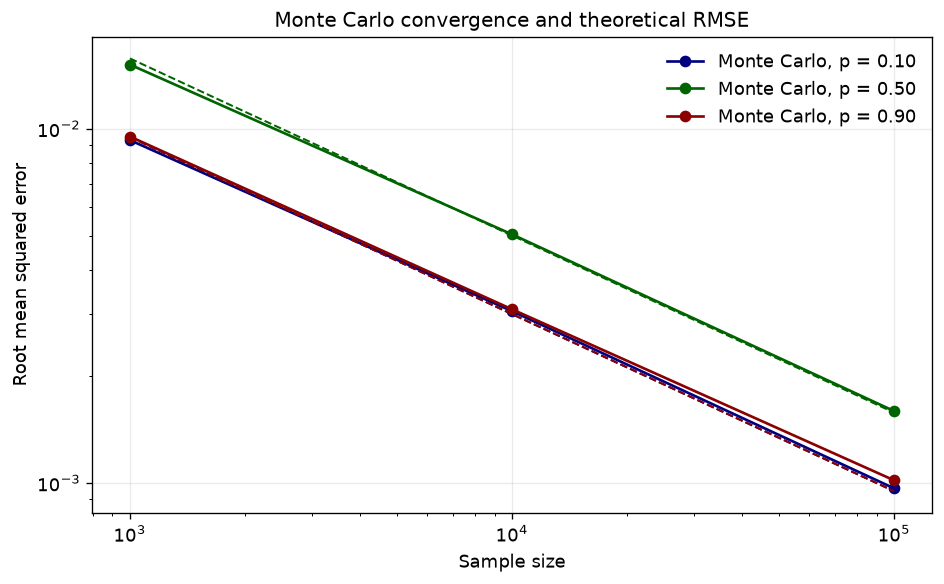

In [37]:
fig, ax = plt.subplots()

colors = ["navy", "darkgreen", "darkred"]

for p_true, color in zip(
    VALIDATION_PROBABILITIES, colors
):

    subset = intermediate_convergence.loc[
        np.isclose(
            intermediate_convergence["p_true"], p_true
        )
    ].sort_values("sample_size")

    ax.plot(
        subset["sample_size"],
        subset["rmse"],
        marker="o",
        color=color,
        linewidth=1.6,
        label=f"Monte Carlo, p = {p_true:.2f}"
    )

    ax.plot(
        subset["sample_size"],
        subset["theoretical_rmse"],
        linestyle="--",
        color=color,
        linewidth=1.2
    )

ax.set(
    xlabel="Sample size",
    ylabel="Root mean squared error",
    title="Monte Carlo convergence and theoretical RMSE"
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure18_RMSE_Convergence.png")
fig.savefig(FIGS_DIR / "Figure18_RMSE_Convergence.pdf")

plt.show()

In [38]:
reliability_records = []

for (n, p_true), group in intermediate_data.groupby(
    ["sample_size", "p_true"]
):

    errors = group["absolute_error"].to_numpy()

    accepted = (
        errors <= VALIDATION_EPSILON + 1e-12
    )

    successes_mc = int(accepted.sum())
    replications = len(accepted)

    empirical_reliability = accepted.mean()

    mc_ci = binomtest(
        successes_mc, replications
    ).proportion_ci(
        confidence_level=0.95,
        method="wilson"
    )

    k_min = max(
        0,
        int(np.ceil(
            n * (p_true - VALIDATION_EPSILON) - 1e-10
        ))
    )

    k_max = min(
        int(n),
        int(np.floor(
            n * (p_true + VALIDATION_EPSILON) + 1e-10
        ))
    )

    exact_reliability = (
        binom.cdf(k_max, int(n), p_true)
        - binom.cdf(k_min - 1, int(n), p_true)
    )

    reliability_records.append({
        "sample_size": int(n),
        "p_true": float(p_true),
        "empirical_reliability": empirical_reliability,
        "exact_reliability": exact_reliability,
        "mc_ci_lower": mc_ci.low,
        "mc_ci_upper": mc_ci.high,
        "mc_standard_error": np.sqrt(
            exact_reliability *
            (1 - exact_reliability) / replications
        )
    })

intermediate_reliability = pd.DataFrame(reliability_records)

intermediate_reliability["absolute_difference"] = np.abs(
    intermediate_reliability["empirical_reliability"] -
    intermediate_reliability["exact_reliability"]
)

intermediate_reliability["reference_inside_mc_ci"] = (
    (intermediate_reliability["mc_ci_lower"] <=
     intermediate_reliability["exact_reliability"]) &
    (intermediate_reliability["exact_reliability"] <=
     intermediate_reliability["mc_ci_upper"])
)

assert intermediate_reliability[
    ["empirical_reliability", "exact_reliability"]
].ge(0).all().all()

assert intermediate_reliability[
    ["empirical_reliability", "exact_reliability"]
].le(1).all().all()

intermediate_reliability.to_csv(
    RESULTS_DIR / "Intermediate_Reliability.csv",
    index=False
)

intermediate_reliability

,sample_size,p_true,empirical_reliability,exact_reliability,mc_ci_lower,mc_ci_upper,mc_standard_error,absolute_difference,reference_inside_mc_ci
0,1000,0.1,1.000,1.000000,0.992376,1.000000,0.000024,2.802308e-07,True
1,1000,0.5,0.998,0.998608,0.988759,0.999647,0.001667,6.082584e-04,True
2,1000,0.9,1.000,1.000000,0.992376,1.000000,0.000024,2.802308e-07,True
3,10000,0.1,1.000,1.000000,0.992376,1.000000,0.000000,0.000000e+00,True
4,10000,0.5,1.000,1.000000,0.992376,1.000000,0.000000,0.000000e+00,True
5,10000,0.9,1.000,1.000000,0.992376,1.000000,0.000000,0.000000e+00,True
6,100000,0.1,1.000,1.000000,0.992376,1.000000,0.000000,0.000000e+00,True
7,100000,0.5,1.000,1.000000,0.992376,1.000000,0.000000,0.000000e+00,True
8,100000,0.9,1.000,1.000000,0.992376,1.000000,0.000000,0.000000e+00,True


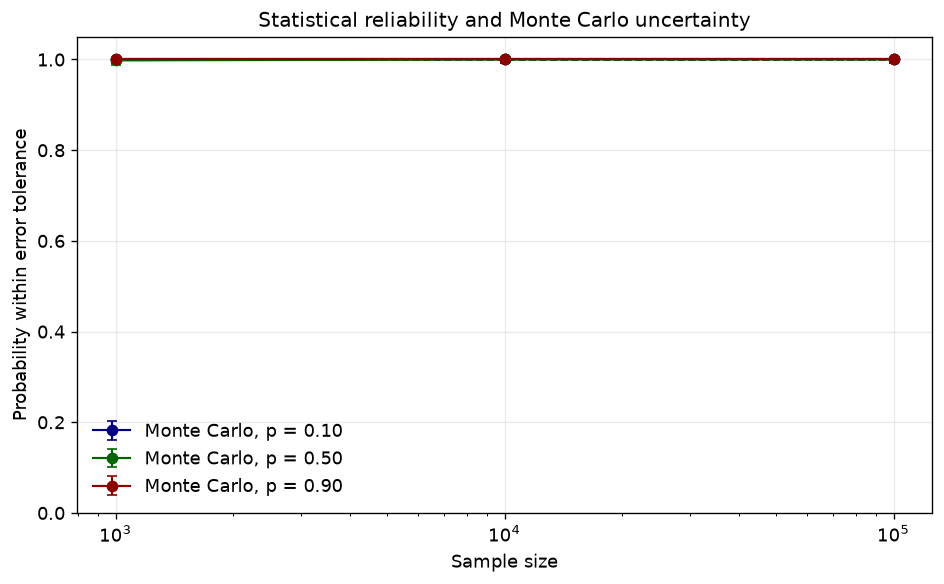

In [39]:
fig, ax = plt.subplots()

colors = ["navy", "darkgreen", "darkred"]

for p_true, color in zip(
    VALIDATION_PROBABILITIES, colors
):

    subset = intermediate_reliability.loc[
        np.isclose(
            intermediate_reliability["p_true"], p_true
        )
    ].sort_values("sample_size")

    estimates = subset["empirical_reliability"].to_numpy()

    lower_errors = (
        estimates - subset["mc_ci_lower"].to_numpy()
    )

    upper_errors = (
        subset["mc_ci_upper"].to_numpy() - estimates
    )

    ax.errorbar(
        subset["sample_size"],
        estimates,
        yerr=np.vstack([lower_errors, upper_errors]),
        marker="o",
        capsize=3,
        linewidth=1.3,
        color=color,
        label=f"Monte Carlo, p = {p_true:.2f}"
    )

    ax.plot(
        subset["sample_size"],
        subset["exact_reliability"],
        linestyle="--",
        color=color,
        linewidth=1.2
    )

ax.set(
    xlabel="Sample size",
    ylabel="Probability within error tolerance",
    title="Statistical reliability and Monte Carlo uncertainty"
)

ax.set_xscale("log")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure19_Reliability_Validation.png")
fig.savefig(FIGS_DIR / "Figure19_Reliability_Validation.pdf")

plt.show()

In [40]:
CI_SIZES = [25, 100, 1000]
CI_PROBABILITIES = [0.05, 0.50, 0.95]
CI_REPLICATIONS = 500

ci_records = []

for i, n in enumerate(CI_SIZES):

    k_grid = np.arange(n + 1)
    exact_intervals = binomial_intervals(
        k_grid, n, VALIDATION_ALPHA
    )

    for j, p_true in enumerate(CI_PROBABILITIES):

        generator = np.random.default_rng(
            VALIDATION_SEED + 2000 + 100 * i + j
        )

        counts = generator.binomial(
            n, p_true, size=CI_REPLICATIONS
        )

        simulated_intervals = binomial_intervals(
            counts, n, VALIDATION_ALPHA
        )

        pmf = binom.pmf(k_grid, n, p_true)

        for method in exact_intervals:

            exact_lower, exact_upper = exact_intervals[method]
            sim_lower, sim_upper = simulated_intervals[method]

            exact_covered = (
                (exact_lower <= p_true) &
                (p_true <= exact_upper)
            )

            simulated_covered = (
                (sim_lower <= p_true) &
                (p_true <= sim_upper)
            )

            exact_coverage = pmf[exact_covered].sum()
            empirical_coverage = simulated_covered.mean()

            ci_records.append({
                "sample_size": n,
                "p_true": p_true,
                "method": method,
                "exact_coverage": exact_coverage,
                "empirical_coverage": empirical_coverage,
                "mc_standard_error": np.sqrt(
                    exact_coverage *
                    (1 - exact_coverage) / CI_REPLICATIONS
                ),
                "mean_width": np.mean(sim_upper - sim_lower)
            })

intermediate_ci = pd.DataFrame(ci_records)

intermediate_ci["absolute_difference"] = np.abs(
    intermediate_ci["empirical_coverage"] -
    intermediate_ci["exact_coverage"]
)

assert intermediate_ci[
    ["exact_coverage", "empirical_coverage"]
].ge(0).all().all()

assert intermediate_ci[
    ["exact_coverage", "empirical_coverage"]
].le(1).all().all()

intermediate_ci.to_csv(
    RESULTS_DIR / "Intermediate_Confidence_Intervals.csv",
    index=False
)

intermediate_ci

,sample_size,p_true,method,exact_coverage,empirical_coverage,mc_standard_error,mean_width,absolute_difference
0,25,0.05,Wald,0.721397,0.714,0.020049,0.116471,0.007397
1,25,0.05,Wilson,0.965909,0.968,0.008115,0.190771,0.002091
2,25,0.05,Clopper-Pearson,0.992835,0.992,0.003772,0.205949,0.000835
3,25,0.50,Wald,0.956715,0.960,0.009101,0.384496,0.003285
4,25,0.50,Wilson,0.956715,0.960,0.009101,0.358934,0.003285
5,25,0.50,Clopper-Pearson,0.956715,0.960,0.009101,0.402484,0.003285
6,25,0.95,Wald,0.721397,0.724,0.020049,0.122748,0.002603
7,25,0.95,Wilson,0.965909,0.956,0.008115,0.194163,0.009909
8,25,0.95,Clopper-Pearson,0.992835,0.982,0.003772,0.210018,0.010835
9,100,0.05,Wald,0.877463,0.882,0.014664,0.080564,0.004537


In [41]:
DEP_N = 1000
DEP_REPLICATIONS = 300
DEP_P = 0.50
DEP_RHO = 0.70

generator = np.random.default_rng(VALIDATION_SEED + 3000)

iid_counts = generator.binomial(
    DEP_N, DEP_P, size=DEP_REPLICATIONS
)

chains = np.empty(
    (DEP_REPLICATIONS, DEP_N), dtype=np.int8
)

chains[:, 0] = generator.binomial(
    1, DEP_P, size=DEP_REPLICATIONS
)

p11_dep = DEP_P + DEP_RHO * (1 - DEP_P)
p01_dep = DEP_P * (1 - DEP_RHO)

for t in range(1, DEP_N):

    transition_p = np.where(
        chains[:, t - 1] == 1,
        p11_dep,
        p01_dep
    )

    chains[:, t] = generator.binomial(
        1, transition_p
    )

dependent_counts = chains.sum(axis=1)

lags = np.arange(1, DEP_N)

iid_variance = DEP_P * (1 - DEP_P) / DEP_N

dependent_variance = (
    DEP_P * (1 - DEP_P) / DEP_N**2
    * (
        DEP_N + 2 * np.sum(
            (DEP_N - lags) * DEP_RHO**lags
        )
    )
)

dep_records = []

for scenario, counts, theoretical_var in [
    ("Independent", iid_counts, iid_variance),
    ("Dependent", dependent_counts, dependent_variance)
]:

    estimates = counts / DEP_N

    lower, upper = binomial_intervals(
        counts, DEP_N, VALIDATION_ALPHA
    )["Wilson"]

    dep_records.append({
        "scenario": scenario,
        "sample_size": DEP_N,
        "replications": DEP_REPLICATIONS,
        "empirical_variance": estimates.var(ddof=1),
        "theoretical_variance": theoretical_var,
        "variance_ratio": (
            estimates.var(ddof=1) / theoretical_var
        ),
        "coverage": np.mean(
            (lower <= DEP_P) & (DEP_P <= upper)
        )
    })

intermediate_dependence = pd.DataFrame(dep_records)

assert dependent_variance > iid_variance
assert intermediate_dependence["coverage"].between(0, 1).all()

intermediate_dependence.to_csv(
    RESULTS_DIR / "Intermediate_Dependence.csv",
    index=False
)

intermediate_dependence

,scenario,sample_size,replications,empirical_variance,theoretical_variance,variance_ratio,coverage
0,Independent,1000,300,0.000256,0.000250,1.025501,0.936667
1,Dependent,1000,300,0.001355,0.001413,0.959238,0.586667


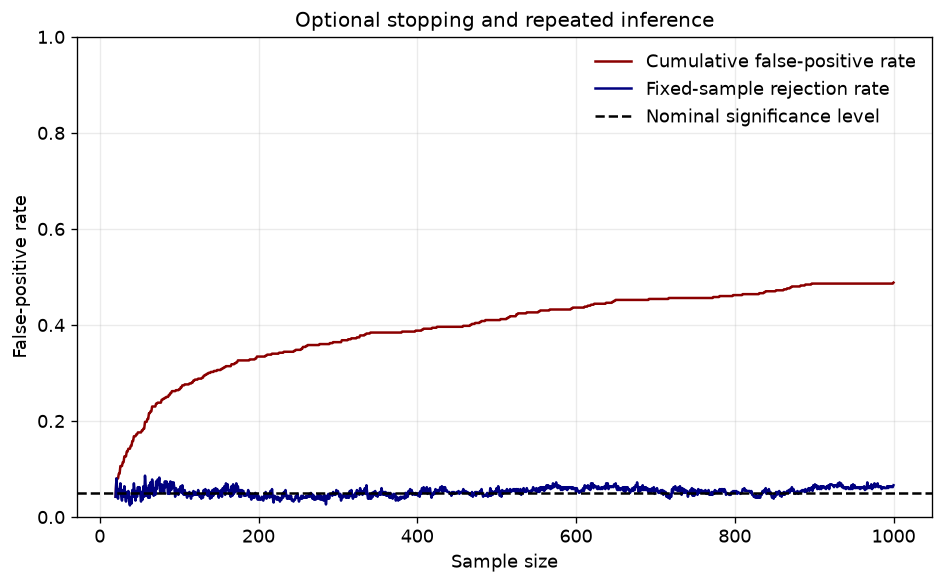

,procedure,false_positive_rate,replications
0,Fixed sample,0.066,500
1,Repeated monitoring,0.488,500


In [42]:
STOP_N = 1000
STOP_REPLICATIONS = 500
STOP_MIN_N = 20
STOP_P = 0.50

generator = np.random.default_rng(VALIDATION_SEED + 4000)

samples = generator.binomial(
    1, STOP_P, size=(STOP_REPLICATIONS, STOP_N)
)

sample_sizes = np.arange(STOP_MIN_N, STOP_N + 1)

counts = np.cumsum(samples, axis=1)[:, STOP_MIN_N - 1:]

estimates = counts / sample_sizes

z = norm.ppf(1 - VALIDATION_ALPHA / 2)
denominator = 1 + z**2 / sample_sizes

center = (
    estimates + z**2 / (2 * sample_sizes)
) / denominator

margin = (
    z / denominator
    * np.sqrt(
        estimates * (1 - estimates) / sample_sizes
        + z**2 / (4 * sample_sizes**2)
    )
)

rejected = (
    (center - margin > STOP_P) |
    (center + margin < STOP_P)
)

fixed_rate = rejected[:, -1].mean()
sequential_rate = rejected.any(axis=1).mean()

assert sequential_rate >= fixed_rate

stopping_validation = pd.DataFrame({
    "procedure": ["Fixed sample", "Repeated monitoring"],
    "false_positive_rate": [fixed_rate, sequential_rate],
    "replications": STOP_REPLICATIONS
})

stopping_validation.to_csv(
    RESULTS_DIR / "Intermediate_Optional_Stopping.csv",
    index=False
)

cumulative_rate = np.maximum.accumulate(
    rejected, axis=1
).mean(axis=0)

fixed_rate_by_n = rejected.mean(axis=0)

fig, ax = plt.subplots()

ax.plot(
    sample_sizes,
    cumulative_rate,
    color="darkred",
    label="Cumulative false-positive rate"
)

ax.plot(
    sample_sizes,
    fixed_rate_by_n,
    color="navy",
    label="Fixed-sample rejection rate"
)

ax.axhline(
    VALIDATION_ALPHA,
    color="black",
    linestyle="--",
    label="Nominal significance level"
)

ax.set(
    xlabel="Sample size",
    ylabel="False-positive rate",
    title="Optional stopping and repeated inference"
)

ax.set_ylim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure20_Optional_Stopping.png")
fig.savefig(FIGS_DIR / "Figure20_Optional_Stopping.pdf")

plt.show()

stopping_validation

In [43]:
BENCHMARK_SIZES = [1000, 10000, 100000]
BENCHMARK_REPLICATIONS = 100
BENCHMARK_BATCH_SIZE = 20
BENCHMARK_REPEATS = 5

benchmark_records = []

for n in BENCHMARK_SIZES:

    times = []
    checksum = 0

    for repeat in range(BENCHMARK_REPEATS):

        generator = np.random.default_rng(
            VALIDATION_SEED + 5000 + n + repeat
        )

        start = perf_counter()

        for start_rep in range(
            0, BENCHMARK_REPLICATIONS, BENCHMARK_BATCH_SIZE
        ):

            batch_size = min(
                BENCHMARK_BATCH_SIZE,
                BENCHMARK_REPLICATIONS - start_rep
            )

            samples = generator.binomial(
                1, 0.50, size=(batch_size, n)
            )

            estimates = samples.mean(axis=1)
            checksum += int(samples.sum())

        elapsed = perf_counter() - start
        times.append(elapsed)

    benchmark_records.append({
        "sample_size": n,
        "replications": BENCHMARK_REPLICATIONS,
        "observations_per_run": n * BENCHMARK_REPLICATIONS,
        "median_time_seconds": np.median(times),
        "min_time_seconds": np.min(times),
        "max_time_seconds": np.max(times),
        "observations_per_second": (
            n * BENCHMARK_REPLICATIONS / np.median(times)
        ),
        "batch_array_memory_mb": (
            BENCHMARK_BATCH_SIZE * n * 8 / 1024**2
        ),
        "checksum": checksum
    })

performance_validation = pd.DataFrame(benchmark_records)

assert np.isfinite(
    performance_validation.select_dtypes(
        include="number"
    ).to_numpy()
).all()

assert (
    performance_validation["median_time_seconds"] > 0
).all()

performance_validation.to_csv(
    RESULTS_DIR / "Intermediate_Performance_Benchmark.csv",
    index=False
)

performance_validation

,sample_size,replications,observations_per_run,median_time_seconds,min_time_seconds,max_time_seconds,observations_per_second,batch_array_memory_mb,checksum
0,1000,100,100000,0.003324,0.002866,0.004395,3.008424e+07,0.152588,249849
1,10000,100,1000000,0.030713,0.029290,0.031901,3.255971e+07,1.525879,2501289
2,100000,100,10000000,0.296604,0.287980,0.320035,3.371500e+07,15.258789,24997898


In [44]:
AUDIT_SEED = RANDOM_SEED + 20000
AUDIT_ALPHA = 0.05

# Diagnostic thresholds, not formal hypothesis-test decisions
MAX_STANDARDIZED_ERROR = 4.0
MAX_RELATIVE_VARIANCE_ERROR = 0.25
MAX_STANDARDIZED_MC_DISCREPANCY = 4.0

AUDIT_REPLICATIONS = 300

validation_criteria = pd.DataFrame({
    "criterion": [
        "maximum_standardized_error",
        "maximum_relative_variance_error",
        "maximum_standardized_mc_discrepancy",
        "audit_replications",
        "audit_seed"
    ],
    "value": [
        MAX_STANDARDIZED_ERROR,
        MAX_RELATIVE_VARIANCE_ERROR,
        MAX_STANDARDIZED_MC_DISCREPANCY,
        AUDIT_REPLICATIONS,
        AUDIT_SEED
    ]
})

validation_criteria.to_csv(
    RESULTS_DIR / "Audit_Validation_Criteria.csv",
    index=False)

In [45]:
moment_records = []

for (n, p_true), group in intermediate_data.groupby(
    ["sample_size", "p_true"]
):

    estimates = group["estimate"].to_numpy()
    r = len(estimates)

    theoretical_variance = p_true * (1 - p_true) / n
    empirical_variance = estimates.var(ddof=1)

    mc_se_mean = np.sqrt(theoretical_variance / r)

    standardized_mean_error = (
        estimates.mean() - p_true
    ) / mc_se_mean

    relative_variance_error = abs(
        empirical_variance / theoretical_variance - 1
    )

    moment_records.append({
        "sample_size": int(n),
        "p_true": float(p_true),
        "empirical_mean": estimates.mean(),
        "theoretical_mean": float(p_true),
        "empirical_variance": empirical_variance,
        "theoretical_variance": theoretical_variance,
        "standardized_mean_error": standardized_mean_error,
        "relative_variance_error": relative_variance_error
    })

moment_validation = pd.DataFrame(moment_records)

moment_validation["mean_within_tolerance"] = (
    moment_validation["standardized_mean_error"].abs()
    <= MAX_STANDARDIZED_ERROR
)

moment_validation["variance_within_tolerance"] = (
    moment_validation["relative_variance_error"]
    <= MAX_RELATIVE_VARIANCE_ERROR
)

moment_validation.to_csv(
    RESULTS_DIR / "Audit_Sampling_Moments.csv",
    index=False
)

moment_validation

,sample_size,p_true,empirical_mean,theoretical_mean,empirical_variance,theoretical_variance,standardized_mean_error,relative_variance_error,mean_within_tolerance,variance_within_tolerance
0,1000,0.1,0.100098,0.1,8.658958e-05,9.000000e-05,0.230988,0.037894,True,True
1,1000,0.5,0.499686,0.5,2.311176e-04,2.500000e-04,-0.444063,0.075529,True,True
2,1000,0.9,0.899648,0.9,9.058527e-05,9.000000e-05,-0.829672,0.006503,True,True
3,10000,0.1,0.100275,0.1,9.289163e-06,9.000000e-06,2.051220,0.032129,True,True
4,10000,0.5,0.499532,0.5,2.521141e-05,2.500000e-05,-2.091171,0.008457,True,True
5,10000,0.9,0.899856,0.9,9.576099e-06,9.000000e-06,-1.074803,0.064011,True,True
6,100000,0.1,0.100003,0.1,9.354502e-07,9.000000e-07,0.072596,0.039389,True,True
7,100000,0.5,0.499926,0.5,2.549580e-06,2.500000e-06,-1.047649,0.019832,True,True
8,100000,0.9,0.899990,0.9,1.038708e-06,9.000000e-07,-0.242773,0.154120,True,True


In [46]:
n = 1000
k = np.arange(n + 1)

mae_records = []

for p_true in VALIDATION_PROBABILITIES:

    probabilities = binom.pmf(k, n, p_true)

    exact_mae = np.sum(
        probabilities * np.abs(k / n - p_true)
    )

    subset = intermediate_data.loc[
        (intermediate_data["sample_size"] == n) &
        np.isclose(intermediate_data["p_true"], p_true)
    ]

    errors = subset["absolute_error"].to_numpy()

    mae_records.append({
        "sample_size": n,
        "p_true": float(p_true),
        "empirical_mae": errors.mean(),
        "exact_mae": exact_mae,
        "mc_standard_error": (
            errors.std(ddof=1) / np.sqrt(len(errors))
        )
    })

mae_validation = pd.DataFrame(mae_records)

mae_validation["standardized_difference"] = (
    (mae_validation["empirical_mae"] -
     mae_validation["exact_mae"]) /
    mae_validation["mc_standard_error"]
)

mae_validation["within_tolerance"] = (
    mae_validation["standardized_difference"].abs()
    <= MAX_STANDARDIZED_MC_DISCREPANCY
)

mae_validation.to_csv(
    RESULTS_DIR / "Audit_Exact_MAE.csv",
    index=False
)

mae_validation

,sample_size,p_true,empirical_mae,exact_mae,mc_standard_error,standardized_difference,within_tolerance
0,1000,0.1,0.007194,0.007563,0.000264,-1.399946,True
1,1000,0.5,0.011946,0.012613,0.000420,-1.586715,True
2,1000,0.9,0.007216,0.007563,0.000278,-1.250023,True


In [47]:
AUDIT_CI_SIZES = [25, 100, 1000]
AUDIT_P_GRID = np.linspace(0.01, 0.99, 99)

ci_audit_records = []

for n in AUDIT_CI_SIZES:

    counts = np.arange(n + 1)
    intervals = binomial_intervals(counts, n, AUDIT_ALPHA)

    for p_true in AUDIT_P_GRID:

        pmf = binom.pmf(counts, n, p_true)

        for method, (lower, upper) in intervals.items():

            covered = (
                (lower <= p_true) & (p_true <= upper)
            )

            ci_audit_records.append({
                "sample_size": n,
                "p_true": float(p_true),
                "method": method,
                "exact_coverage": pmf[covered].sum(),
                "expected_width": np.sum(
                    pmf * (upper - lower)
                )
            })

ci_audit = pd.DataFrame(ci_audit_records)

ci_audit["coverage_shortfall"] = np.maximum(
    0, (1 - AUDIT_ALPHA) - ci_audit["exact_coverage"]
)

ci_audit_summary = (
    ci_audit.groupby(["sample_size", "method"], as_index=False)
    .agg(
        minimum_coverage=("exact_coverage", "min"),
        mean_coverage=("exact_coverage", "mean"),
        mean_expected_width=("expected_width", "mean"),
        maximum_shortfall=("coverage_shortfall", "max")
    )
)

assert ci_audit["exact_coverage"].between(0, 1).all()

# Clopper-Pearson guarantees at least nominal coverage
cp_coverage = ci_audit.loc[
    ci_audit["method"] == "Clopper-Pearson",
    "exact_coverage"
]

assert np.all(cp_coverage >= 1 - AUDIT_ALPHA - 1e-10)

ci_audit.to_csv(
    RESULTS_DIR / "Audit_Exact_CI_Grid.csv",
    index=False
)

ci_audit_summary.to_csv(
    RESULTS_DIR / "Audit_Exact_CI_Summary.csv",
    index=False
)

ci_audit_summary

,sample_size,method,minimum_coverage,mean_coverage,mean_expected_width,maximum_shortfall
0,25,Clopper-Pearson,0.954873,0.975773,0.329611,0.000000
1,25,Wald,0.222072,0.869985,0.290963,0.727928
2,25,Wilson,0.911355,0.951474,0.295948,0.038645
3,100,Clopper-Pearson,0.954256,0.964911,0.162677,0.000000
4,100,Wald,0.633433,0.926933,0.153331,0.316567
5,100,Wilson,0.920627,0.949227,0.153419,0.029373
6,1000,Clopper-Pearson,0.951079,0.954983,0.050037,0.000000
7,1000,Wald,0.926955,0.948159,0.049073,0.023045
8,1000,Wilson,0.945685,0.949773,0.049056,0.004315


In [48]:
coverage_audit = intermediate_ci.copy()

coverage_audit["standardized_discrepancy"] = np.where(
    coverage_audit["mc_standard_error"] > 0,
    (
        coverage_audit["empirical_coverage"] -
        coverage_audit["exact_coverage"]
    ) / coverage_audit["mc_standard_error"],
    np.where(
        np.isclose(
            coverage_audit["empirical_coverage"],
            coverage_audit["exact_coverage"],
            atol=1e-12
        ),
        0.0,
        np.inf
    )
)

coverage_audit["within_tolerance"] = (
    coverage_audit["standardized_discrepancy"].abs()
    <= MAX_STANDARDIZED_MC_DISCREPANCY
)

coverage_audit.to_csv(
    RESULTS_DIR / "Audit_MC_Coverage_Consistency.csv",
    index=False
)

coverage_audit_summary = (
    coverage_audit.groupby("method", as_index=False)
    .agg(
        scenarios=("sample_size", "count"),
        maximum_absolute_z=(
            "standardized_discrepancy",
            lambda x: np.max(np.abs(x))
        ),
        scenarios_within_tolerance=(
            "within_tolerance", "sum"
        )
    )
)

coverage_audit_summary.to_csv(
    RESULTS_DIR / "Audit_MC_Coverage_Summary.csv",
    index=False
)

coverage_audit_summary

,method,scenarios,maximum_absolute_z,scenarios_within_tolerance
0,Clopper-Pearson,9,2.872572,9
1,Wald,9,2.126459,9
2,Wilson,9,1.605159,9


In [49]:
MARKOV_N = 500
MARKOV_REPLICATIONS = AUDIT_REPLICATIONS
MARKOV_RHOS = [0.0, 0.30, 0.70]
MARKOV_P = 0.50

markov_records = []

for i, rho_value in enumerate(MARKOV_RHOS):

    generator = np.random.default_rng(
        AUDIT_SEED + 1000 + i
    )

    sequences = np.empty(
        (MARKOV_REPLICATIONS, MARKOV_N),
        dtype=np.int8
    )

    sequences[:, 0] = generator.binomial(
        1, MARKOV_P, size=MARKOV_REPLICATIONS
    )

    p11 = MARKOV_P + rho_value * (1 - MARKOV_P)
    p01 = MARKOV_P * (1 - rho_value)

    for t in range(1, MARKOV_N):

        transition = np.where(
            sequences[:, t - 1] == 1,
            p11,
            p01
        )

        sequences[:, t] = generator.binomial(
            1, transition
        )

    estimates = sequences.mean(axis=1)

    lags = np.arange(1, MARKOV_N)

    theoretical_variance = (
        MARKOV_P * (1 - MARKOV_P) / MARKOV_N**2
        * (
            MARKOV_N + 2 * np.sum(
                (MARKOV_N - lags) * rho_value**lags
            )
        )
    )

    empirical_variance = estimates.var(ddof=1)

    markov_records.append({
        "rho": rho_value,
        "sample_size": MARKOV_N,
        "replications": MARKOV_REPLICATIONS,
        "empirical_mean": estimates.mean(),
        "empirical_variance": empirical_variance,
        "theoretical_variance": theoretical_variance,
        "variance_ratio": (
            empirical_variance / theoretical_variance
        )
    })

markov_audit = pd.DataFrame(markov_records)

assert np.all(
    np.diff(markov_audit["theoretical_variance"]) > 0
)

markov_audit.to_csv(
    RESULTS_DIR / "Audit_Markov_Robustness.csv",
    index=False
)

markov_audit

,rho,sample_size,replications,empirical_mean,empirical_variance,theoretical_variance,variance_ratio
0,0.0,500,300,0.501107,0.000492,0.000500,0.984031
1,0.3,500,300,0.500813,0.000922,0.000927,0.994045
2,0.7,500,300,0.498853,0.003151,0.002818,1.118115


In [50]:
NS_N = 500
NS_REPLICATIONS = AUDIT_REPLICATIONS

probability_scenarios = {
    "Stationary": np.full(NS_N, 0.50),
    "Low_to_high": np.r_[
        np.full(250, 0.20),
        np.full(250, 0.80)
    ],
    "High_to_low": np.r_[
        np.full(250, 0.80),
        np.full(250, 0.20)
    ]
}

nonstationary_records = []

for i, (scenario, probabilities) in enumerate(
    probability_scenarios.items()
):

    generator = np.random.default_rng(
        AUDIT_SEED + 2000 + i
    )

    samples = generator.binomial(
        1, probabilities,
        size=(NS_REPLICATIONS, NS_N)
    )

    estimates = samples.mean(axis=1)

    first_half = samples[:, :250].mean(axis=1)
    second_half = samples[:, 250:].mean(axis=1)

    theoretical_variance = (
        np.sum(probabilities * (1 - probabilities))
        / NS_N**2
    )

    nonstationary_records.append({
        "scenario": scenario,
        "theoretical_global_mean": probabilities.mean(),
        "empirical_global_mean": estimates.mean(),
        "first_half_mean": first_half.mean(),
        "second_half_mean": second_half.mean(),
        "empirical_variance": estimates.var(ddof=1),
        "theoretical_variance": theoretical_variance
    })

nonstationary_audit = pd.DataFrame(
    nonstationary_records
)

assert np.allclose(
    nonstationary_audit["theoretical_global_mean"],
    0.50
)

nonstationary_audit.to_csv(
    RESULTS_DIR / "Audit_Nonstationarity.csv",
    index=False
)

nonstationary_audit

,scenario,theoretical_global_mean,empirical_global_mean,first_half_mean,second_half_mean,empirical_variance,theoretical_variance
0,Stationary,0.5,0.499827,0.49808,0.501573,0.000476,0.00050
1,Low_to_high,0.5,0.500187,0.20092,0.799453,0.000319,0.00032
2,High_to_low,0.5,0.501353,0.79936,0.203347,0.000340,0.00032


In [51]:
STOP_AUDIT_N = 500
STOP_AUDIT_REPLICATIONS = 300
STOP_AUDIT_MIN_N = 20
STOP_AUDIT_P = 0.50
STOP_AUDIT_RUNS = 3

stop_records = []

for run in range(STOP_AUDIT_RUNS):

    generator = np.random.default_rng(
        AUDIT_SEED + 3000 + run
    )

    samples = generator.binomial(
        1, STOP_AUDIT_P,
        size=(STOP_AUDIT_REPLICATIONS, STOP_AUDIT_N)
    )

    n_grid = np.arange(
        STOP_AUDIT_MIN_N, STOP_AUDIT_N + 1
    )

    counts = np.cumsum(
        samples, axis=1
    )[:, STOP_AUDIT_MIN_N - 1:]

    estimates = counts / n_grid

    z = norm.ppf(1 - AUDIT_ALPHA / 2)

    denominator = 1 + z**2 / n_grid

    center = (
        estimates + z**2 / (2 * n_grid)
    ) / denominator

    margin = (
        z / denominator
        * np.sqrt(
            estimates * (1 - estimates) / n_grid
            + z**2 / (4 * n_grid**2)
        )
    )

    rejected = (
        (center - margin > STOP_AUDIT_P) |
        (center + margin < STOP_AUDIT_P)
    )

    stop_records.append({
        "run": run + 1,
        "replications": STOP_AUDIT_REPLICATIONS,
        "fixed_rejections": int(rejected[:, -1].sum()),
        "sequential_rejections": int(
            rejected.any(axis=1).sum()
        )
    })

stopping_robustness = pd.DataFrame(stop_records)

stopping_robustness["fixed_rate"] = (
    stopping_robustness["fixed_rejections"] /
    STOP_AUDIT_REPLICATIONS
)

stopping_robustness["sequential_rate"] = (
    stopping_robustness["sequential_rejections"] /
    STOP_AUDIT_REPLICATIONS
)

assert (
    stopping_robustness["sequential_rejections"] >=
    stopping_robustness["fixed_rejections"]
).all()

stopping_robustness.to_csv(
    RESULTS_DIR / "Audit_Optional_Stopping_Robustness.csv",
    index=False
)

stopping_robustness

,run,replications,fixed_rejections,sequential_rejections,fixed_rate,sequential_rate
0,1,300,16,107,0.053333,0.356667
1,2,300,19,109,0.063333,0.363333
2,3,300,21,115,0.070000,0.383333


In [52]:
AUDIT_BENCHMARK_SIZES = [1000, 10000, 100000]
AUDIT_BENCHMARK_REPS = 100
AUDIT_BENCHMARK_RUNS = 3
AUDIT_BATCH_SIZE = 20

benchmark_records = []

for n in AUDIT_BENCHMARK_SIZES:

    for method in ["Aggregated", "Individual"]:

        times = []
        checksums = []

        for run in range(AUDIT_BENCHMARK_RUNS):

            generator = np.random.default_rng(
                AUDIT_SEED + 4000 + n + run
            )

            start = perf_counter()

            if method == "Aggregated":

                counts = generator.binomial(
                    n, 0.50,
                    size=AUDIT_BENCHMARK_REPS
                )

                estimates = counts / n
                checksum = float(estimates.sum())

            else:

                checksum = 0.0

                for start_rep in range(
                    0, AUDIT_BENCHMARK_REPS,
                    AUDIT_BATCH_SIZE
                ):

                    batch_size = min(
                        AUDIT_BATCH_SIZE,
                        AUDIT_BENCHMARK_REPS - start_rep
                    )

                    samples = generator.binomial(
                        1, 0.50,
                        size=(batch_size, n)
                    )

                    checksum += float(
                        samples.mean(axis=1).sum()
                    )

            elapsed = perf_counter() - start

            times.append(elapsed)
            checksums.append(checksum)

        benchmark_records.append({
            "method": method,
            "sample_size": n,
            "replications": AUDIT_BENCHMARK_REPS,
            "median_seconds": np.median(times),
            "min_seconds": np.min(times),
            "max_seconds": np.max(times),
            "observations_per_second": (
                n * AUDIT_BENCHMARK_REPS /
                np.median(times)
            ),
            "estimated_array_memory_mb": (
                (AUDIT_BENCHMARK_REPS * 8)
                if method == "Aggregated"
                else (AUDIT_BATCH_SIZE * n * 8)
            ) / 1024**2,
            "checksum_mean": np.mean(checksums)
        })

scalability_audit = pd.DataFrame(benchmark_records)

assert (scalability_audit["median_seconds"] > 0).all()
assert np.isfinite(
    scalability_audit.select_dtypes(
        include="number"
    ).to_numpy()
).all()

scalability_audit.to_csv(
    RESULTS_DIR / "Audit_Computational_Scalability.csv",
    index=False
)

scalability_audit

,method,sample_size,replications,median_seconds,min_seconds,max_seconds,observations_per_second,estimated_array_memory_mb,checksum_mean
0,Aggregated,1000,100,0.000063,0.000036,0.000406,1.594896e+09,0.000763,49.940667
1,Individual,1000,100,0.003999,0.003816,0.004157,2.500938e+07,0.152588,49.824333
2,Aggregated,10000,100,0.000051,0.000036,0.000227,1.980198e+10,0.000763,50.064700
3,Individual,10000,100,0.031481,0.029387,0.032383,3.176529e+07,1.525879,50.004233
4,Aggregated,100000,100,0.000036,0.000036,0.000052,2.754821e+11,0.000763,50.000327
5,Individual,100000,100,0.286147,0.283305,0.289487,3.494706e+07,15.258789,49.997823


In [53]:
audit_results = [
    {
        "component": "E01-E02",
        "criterion": "Sampling mean agreement",
        "passed": bool(
            moment_validation["mean_within_tolerance"].all()
        )
    },
    {
        "component": "E02",
        "criterion": "Sampling variance agreement",
        "passed": bool(
            moment_validation["variance_within_tolerance"].all()
        )
    },
    {
        "component": "E02",
        "criterion": "Exact MAE consistency",
        "passed": bool(
            mae_validation["within_tolerance"].all()
        )
    },
    {
        "component": "E03",
        "criterion": "Exact Clopper-Pearson coverage",
        "passed": bool(
            (cp_coverage >= 1 - AUDIT_ALPHA - 1e-10).all()
        )
    },
    {
        "component": "E03",
        "criterion": "Monte Carlo coverage agreement",
        "passed": bool(
            coverage_audit["within_tolerance"].all()
        )
    },
    {
        "component": "E04",
        "criterion": "Theoretical Markov variance ordering",
        "passed": bool(
            np.all(np.diff(
                markov_audit["theoretical_variance"]
            ) > 0)
        )
    },
    {
        "component": "E04",
        "criterion": "Nonstationary global mean",
        "passed": bool(
            np.allclose(
                nonstationary_audit["theoretical_global_mean"],
                0.50
            )
        )
    },
    {
        "component": "E05",
        "criterion": "Sequential rejection consistency",
        "passed": bool(
            (
                stopping_robustness["sequential_rejections"]
                >= stopping_robustness["fixed_rejections"]
            ).all()
        )
    },
    {
        "component": "Performance",
        "criterion": "Finite positive execution times",
        "passed": bool(
            (scalability_audit["median_seconds"] > 0).all()
        )
    }
]

final_audit = pd.DataFrame(audit_results)

final_audit["status"] = np.where(
    final_audit["passed"],
    "PASS",
    "REVIEW"
)

final_audit.to_csv(
    RESULTS_DIR / "Final_Preliminary_Audit.csv",
    index=False
)

audit_summary = pd.DataFrame({
    "total_checks": [len(final_audit)],
    "passed_checks": [int(final_audit["passed"].sum())],
    "checks_requiring_review": [
        int((~final_audit["passed"]).sum())
    ],
    "all_checks_passed": [bool(final_audit["passed"].all())]
})

audit_summary.to_csv(
    RESULTS_DIR / "Final_Preliminary_Audit_Summary.csv",
    index=False
)

final_audit

,component,criterion,passed,status
0,E01-E02,Sampling mean agreement,True,PASS
1,E02,Sampling variance agreement,True,PASS
2,E02,Exact MAE consistency,True,PASS
3,E03,Exact Clopper-Pearson coverage,True,PASS
4,E03,Monte Carlo coverage agreement,True,PASS
5,E04,Theoretical Markov variance ordering,True,PASS
6,E04,Nonstationary global mean,True,PASS
7,E05,Sequential rejection consistency,True,PASS
8,Performance,Finite positive execution times,True,PASS


In [54]:
from scipy.stats import binom

z_tolerance = 1.96
records = []

for (n, p_true), group in intermediate_data.groupby(
    ["sample_size", "p_true"]
):
    se = np.sqrt(p_true * (1 - p_true) / n)
    epsilon = z_tolerance * se

    estimates = group["estimate"].to_numpy()
    accepted = np.abs(estimates - p_true) <= epsilon

    k_min = max(0, int(np.ceil(n * (p_true - epsilon) - 1e-10)))
    k_max = min(int(n), int(np.floor(n * (p_true + epsilon) + 1e-10)))

    exact = binom.cdf(k_max, int(n), p_true) - binom.cdf(
        k_min - 1, int(n), p_true
    )

    empirical = accepted.mean()
    mc_se = np.sqrt(exact * (1 - exact) / len(estimates))

    records.append({
        "n": int(n),
        "p": float(p_true),
        "standardized_tolerance": z_tolerance,
        "empirical_reliability": empirical,
        "exact_reliability": exact,
        "mc_standard_error": mc_se,
        "absolute_difference": abs(empirical - exact)
    })

standardized_reliability = pd.DataFrame(records)

standardized_reliability.to_csv(
    RESULTS_DIR / "Standardized_Reliability.csv",
    index=False
)

standardized_reliability

,n,p,standardized_tolerance,empirical_reliability,exact_reliability,mc_standard_error,absolute_difference
0,1000,0.1,1.96,0.946,0.949098,0.009830,0.003098
1,1000,0.5,1.96,0.952,0.946322,0.010079,0.005678
2,1000,0.9,1.96,0.946,0.949098,0.009830,0.003098
3,10000,0.1,1.96,0.934,0.948850,0.009852,0.014850
4,10000,0.5,1.96,0.946,0.951167,0.009638,0.005167
5,10000,0.9,1.96,0.928,0.948850,0.009852,0.020850
6,100000,0.1,1.96,0.948,0.949460,0.009797,0.001460
7,100000,0.5,1.96,0.948,0.949706,0.009774,0.001706
8,100000,0.9,1.96,0.936,0.949460,0.009797,0.013460


In [55]:
from scipy.stats import norm

calibration_records = []

for row in standardized_reliability.itertuples():

    if row.mc_standard_error > 0:
        z_score = (
            row.empirical_reliability - row.exact_reliability
        ) / row.mc_standard_error
    else:
        z_score = (
            0.0 if np.isclose(
                row.empirical_reliability,
                row.exact_reliability,
                atol=1e-12
            ) else np.inf
        )

    calibration_records.append({
        "n": row.n,
        "p": row.p,
        "standardized_discrepancy": z_score,
        "within_tolerance": abs(z_score) <= 4.0
    })

calibrated_diagnostics = pd.DataFrame(calibration_records)

calibrated_diagnostics.to_csv(
    RESULTS_DIR / "Calibrated_MC_Diagnostics.csv",
    index=False
)

calibrated_diagnostics

,n,p,standardized_discrepancy,within_tolerance
0,1000,0.1,-0.315152,True
1,1000,0.5,0.563316,True
2,1000,0.9,-0.315152,True
3,10000,0.1,-1.507305,True
4,10000,0.5,-0.536096,True
5,10000,0.9,-2.116304,True
6,100000,0.1,-0.149020,True
7,100000,0.5,-0.174541,True
8,100000,0.9,-1.373945,True


In [56]:
from time import perf_counter

benchmark_records = []

for n in [1000, 10000, 100000]:

    times = []
    checksums = []

    for repeat in range(5):

        rng_benchmark = np.random.default_rng(
            RANDOM_SEED + 30000 + n + repeat
        )

        start = perf_counter()
        total = 0

        for _ in range(1000):
            counts = rng_benchmark.binomial(
                n, 0.50, size=100
            )
            total += int(counts.sum())

        times.append(perf_counter() - start)
        checksums.append(total)

    benchmark_records.append({
        "sample_size": n,
        "replications_per_run": 100000,
        "median_seconds": np.median(times),
        "min_seconds": np.min(times),
        "max_seconds": np.max(times),
        "time_per_replication": np.median(times) / 100000,
        "checksums_valid": all(x > 0 for x in checksums)
    })

calibrated_benchmark = pd.DataFrame(benchmark_records)

assert np.isfinite(
    calibrated_benchmark.select_dtypes(include="number")
    .to_numpy()
).all()

assert calibrated_benchmark["checksums_valid"].all()

calibrated_benchmark.to_csv(
    RESULTS_DIR / "Calibrated_Computational_Benchmark.csv",
    index=False
)

calibrated_benchmark

,sample_size,replications_per_run,median_seconds,min_seconds,max_seconds,time_per_replication,checksums_valid
0,1000,100000,0.012308,0.011682,0.021218,1.230790e-07,True
1,10000,100000,0.011386,0.010028,0.011782,1.138590e-07,True
2,100000,100000,0.011198,0.010130,0.013482,1.119760e-07,True


Parte 3

In [57]:
DESIGN_SAMPLE_SIZES = np.array([
    100, 500, 1000, 5000, 10000, 50000, 100000
])

DESIGN_PROBABILITIES = np.array([
    0.01, 0.05, 0.10, 0.30, 0.50,
    0.70, 0.90, 0.95, 0.99
])

DESIGN_CONFIDENCE = 0.95
DESIGN_MC_HALF_WIDTH = 0.01
DESIGN_SEED = RANDOM_SEED + 50000

DESIGN_BATCH_SIZE = 500

assert np.all(np.diff(DESIGN_SAMPLE_SIZES) > 0)
assert np.all((DESIGN_PROBABILITIES > 0) &
              (DESIGN_PROBABILITIES < 1))
assert 0 < DESIGN_CONFIDENCE < 1

design_config = pd.DataFrame({
    "parameter": [
        "sample_sizes",
        "probabilities",
        "confidence_level",
        "target_mc_half_width",
        "batch_size",
        "random_seed"
    ],
    "value": [
        str(DESIGN_SAMPLE_SIZES.tolist()),
        str(DESIGN_PROBABILITIES.tolist()),
        str(DESIGN_CONFIDENCE),
        str(DESIGN_MC_HALF_WIDTH),
        str(DESIGN_BATCH_SIZE),
        str(DESIGN_SEED)
    ]
})

design_config.to_csv(
    RESULTS_DIR / "Definitive_Design_Configuration.csv",
    index=False
)

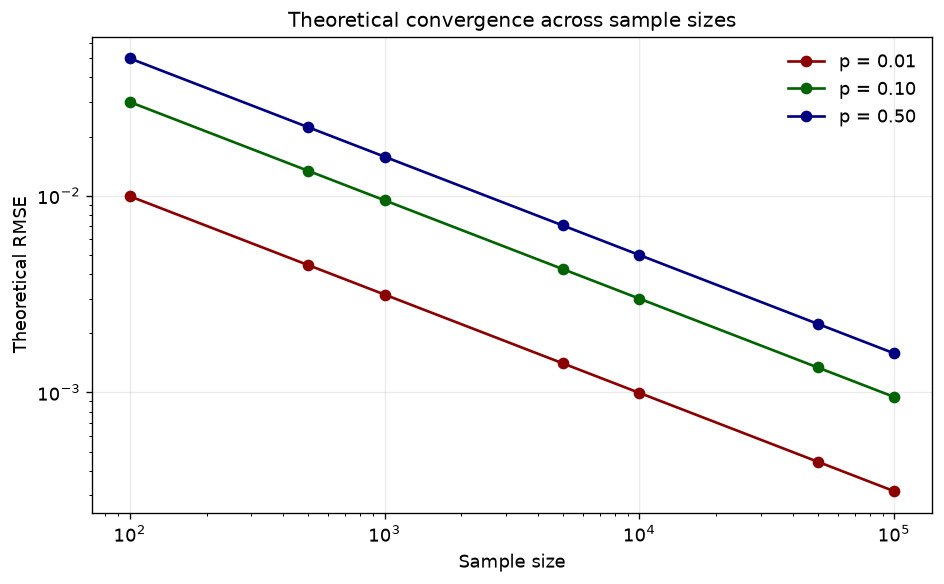

In [58]:
design_records = []

for p_true in DESIGN_PROBABILITIES:
    for n in DESIGN_SAMPLE_SIZES:

        theoretical_rmse = np.sqrt(
            p_true * (1 - p_true) / n
        )

        design_records.append({
            "sample_size": int(n),
            "p_true": float(p_true),
            "theoretical_variance": p_true * (1 - p_true) / n,
            "theoretical_rmse": theoretical_rmse,
            "normal_approximation_criterion": (
                min(n * p_true, n * (1 - p_true)) >= 10
            )
        })

sample_size_design = pd.DataFrame(design_records)

sample_size_design.to_csv(
    RESULTS_DIR / "Definitive_Sample_Size_Design.csv",
    index=False
)

fig, ax = plt.subplots()

for p_true, color in [
    (0.01, "darkred"),
    (0.10, "darkgreen"),
    (0.50, "navy")
]:

    subset = sample_size_design.loc[
        np.isclose(sample_size_design["p_true"], p_true)
    ]

    ax.plot(
        subset["sample_size"],
        subset["theoretical_rmse"],
        marker="o",
        linewidth=1.6,
        color=color,
        label=f"p = {p_true:.2f}"
    )

ax.set(
    xlabel="Sample size",
    ylabel="Theoretical RMSE",
    title="Theoretical convergence across sample sizes"
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure21_TheoreticalConvergence.png")
fig.savefig(FIGS_DIR / "Figure21_TheoreticalConvergence.pdf")

plt.show()

In [59]:
z = norm.ppf((1 + DESIGN_CONFIDENCE) / 2)

MC_EVENT_PROBABILITIES = np.array([
    0.01, 0.05, 0.10, 0.50, 0.90, 0.95, 0.99
])

MC_TARGET_HALF_WIDTHS = np.array([0.02, 0.01, 0.005])

replication_records = []

for q in MC_EVENT_PROBABILITIES:
    for delta in MC_TARGET_HALF_WIDTHS:

        required = int(np.ceil(
            z**2 * q * (1 - q) / delta**2
        ))

        replication_records.append({
            "event_probability": float(q),
            "target_half_width": float(delta),
            "required_replications": required
        })

replication_design = pd.DataFrame(replication_records)

# Conservative design for an unknown event probability
DESIGN_REPLICATIONS = int(np.ceil(
    z**2 * 0.25 / DESIGN_MC_HALF_WIDTH**2
))

replication_design.to_csv(
    RESULTS_DIR / "Definitive_Replication_Design.csv",
    index=False
)

assert DESIGN_REPLICATIONS > 0

DESIGN_REPLICATIONS

9604

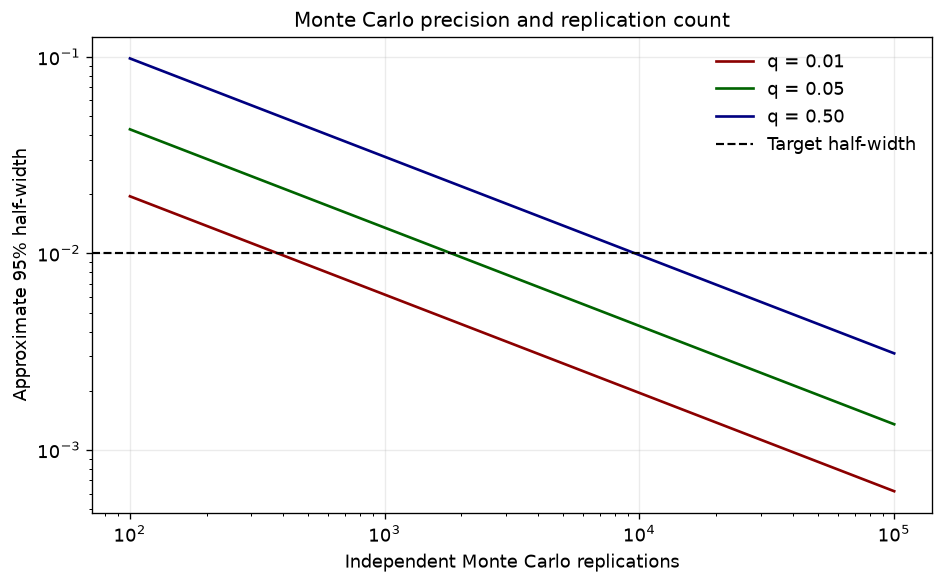

In [60]:
replication_grid = np.unique(
    np.geomspace(100, 100000, 150).astype(int)
)

fig, ax = plt.subplots()

for q, color in [
    (0.01, "darkred"),
    (0.05, "darkgreen"),
    (0.50, "navy")
]:

    half_width = (
        z * np.sqrt(q * (1 - q) / replication_grid)
    )

    ax.plot(
        replication_grid,
        half_width,
        color=color,
        linewidth=1.6,
        label=f"q = {q:.2f}"
    )

ax.axhline(
    DESIGN_MC_HALF_WIDTH,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label="Target half-width"
)

ax.set(
    xlabel="Independent Monte Carlo replications",
    ylabel="Approximate 95% half-width",
    title="Monte Carlo precision and replication count"
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure22_MonteCarloPrecision.png")
fig.savefig(FIGS_DIR / "Figure22_MonteCarloPrecision.pdf")

plt.show()

In [61]:
workload_records = []

for n in DESIGN_SAMPLE_SIZES:

    total = (
        int(n) * DESIGN_REPLICATIONS *
        len(DESIGN_PROBABILITIES)
    )

    workload_records.append({
        "sample_size": int(n),
        "probability_scenarios": len(DESIGN_PROBABILITIES),
        "replications_per_scenario": DESIGN_REPLICATIONS,
        "total_observations_equivalent": total,
        "individual_batch_memory_mb": (
            min(DESIGN_BATCH_SIZE, DESIGN_REPLICATIONS)
            * int(n) * 8 / 1024**2
        ),
        "aggregated_count_memory_mb": (
            DESIGN_REPLICATIONS * 8 / 1024**2
        )
    })

computational_workload = pd.DataFrame(workload_records)

computational_workload.to_csv(
    RESULTS_DIR / "Definitive_Computational_Workload.csv",
    index=False
)

design_summary = pd.DataFrame({
    "metric": [
        "sample_size_scenarios",
        "probability_scenarios",
        "total_parameter_combinations",
        "replications_per_combination",
        "total_equivalent_observations",
        "maximum_individual_batch_memory_mb"
    ],
    "value": [
        len(DESIGN_SAMPLE_SIZES),
        len(DESIGN_PROBABILITIES),
        len(DESIGN_SAMPLE_SIZES) * len(DESIGN_PROBABILITIES),
        DESIGN_REPLICATIONS,
        computational_workload[
            "total_observations_equivalent"
        ].sum(),
        computational_workload[
            "individual_batch_memory_mb"
        ].max()
    ]
})

design_summary.to_csv(
    RESULTS_DIR / "Definitive_Design_Summary.csv",
    index=False
)

design_summary

,metric,value
0,sample_size_scenarios,7.000000e+00
1,probability_scenarios,9.000000e+00
2,total_parameter_combinations,6.300000e+01
3,replications_per_combination,9.604000e+03
4,total_equivalent_observations,1.440024e+10
5,maximum_individual_batch_memory_mb,3.814697e+02


Parte 4

In [62]:
from scipy.stats import binom, norm
from time import perf_counter

E01_SIZES = DESIGN_SAMPLE_SIZES.copy()
E01_PROBABILITIES = DESIGN_PROBABILITIES.copy()

E01_REPLICATIONS = DESIGN_REPLICATIONS
E01_BATCH_SIZE = DESIGN_BATCH_SIZE
E01_SEED = DESIGN_SEED + 1000

E01_EPSILON = 0.05
E01_Z_TOLERANCE = 1.96

E01_FAMILY_ALPHA = 0.05
E01_N_COMPARISONS = (
    len(E01_SIZES) * len(E01_PROBABILITIES) * 3
)

E01_Z_CRITICAL = norm.ppf(
    1 - E01_FAMILY_ALPHA / (2 * E01_N_COMPARISONS)
)

assert E01_REPLICATIONS >= 9604
assert E01_BATCH_SIZE > 0

e01_configuration = pd.DataFrame({
    "parameter": [
        "sample_sizes",
        "probabilities",
        "replications",
        "batch_size",
        "fixed_tolerance",
        "standardized_tolerance",
        "family_alpha",
        "family_comparisons",
        "seed"
    ],
    "value": [
        str(E01_SIZES.tolist()),
        str(E01_PROBABILITIES.tolist()),
        E01_REPLICATIONS,
        E01_BATCH_SIZE,
        E01_EPSILON,
        E01_Z_TOLERANCE,
        E01_FAMILY_ALPHA,
        E01_N_COMPARISONS,
        E01_SEED
    ]
})

e01_configuration.to_csv(
    RESULTS_DIR / "E01_Definitive_Configuration.csv",
    index=False)

In [63]:
e01_records = []
e01_timing_records = []

for i, n in enumerate(E01_SIZES):
    for j, p_true in enumerate(E01_PROBABILITIES):

        seed = E01_SEED + 100 * i + j
        generator = np.random.default_rng(seed)

        start = perf_counter()
        batches = []

        for start_rep in range(
            0, E01_REPLICATIONS, E01_BATCH_SIZE
        ):

            batch_size = min(
                E01_BATCH_SIZE,
                E01_REPLICATIONS - start_rep
            )

            counts = generator.binomial(
                int(n),
                float(p_true),
                size=batch_size
            )

            batches.append(counts)

        successes = np.concatenate(batches)
        elapsed = perf_counter() - start

        estimates = successes / n

        e01_records.append(pd.DataFrame({
            "sample_size": int(n),
            "p_true": float(p_true),
            "replication": np.arange(
                1, E01_REPLICATIONS + 1
            ),
            "successes": successes,
            "estimate": estimates,
            "error": estimates - p_true,
            "absolute_error": np.abs(estimates - p_true)
        }))

        e01_timing_records.append({
            "sample_size": int(n),
            "p_true": float(p_true),
            "seed": seed,
            "replications": E01_REPLICATIONS,
            "generation_seconds": elapsed
        })

e01_data = pd.concat(e01_records, ignore_index=True)
e01_timing = pd.DataFrame(e01_timing_records)

assert len(e01_data) == (
    len(E01_SIZES) *
    len(E01_PROBABILITIES) *
    E01_REPLICATIONS
)

assert e01_data["estimate"].between(0, 1).all()

assert np.allclose(
    e01_data["estimate"],
    e01_data["successes"] / e01_data["sample_size"]
)

e01_data.to_csv(
    RESULTS_DIR / "E01_Definitive_Replications.csv.gz",
    index=False,
    compression="gzip",
    float_format="%.17g"
)

e01_timing.to_csv(
    RESULTS_DIR / "E01_Definitive_Timing.csv",
    index=False
)

e01_timing

,sample_size,p_true,seed,replications,generation_seconds
0,100,0.01,53027,9604,0.001712
1,100,0.05,53028,9604,0.000816
2,100,0.10,53029,9604,0.001093
3,100,0.30,53030,9604,0.002818
4,100,0.50,53031,9604,0.001172
...,...,...,...,...,...
58,100000,0.50,53631,9604,0.000546
59,100000,0.70,53632,9604,0.000552
60,100000,0.90,53633,9604,0.000547
61,100000,0.95,53634,9604,0.000545


In [64]:
e01_summary_records = []

for (n, p_true), group in e01_data.groupby(
    ["sample_size", "p_true"]
):

    errors = group["error"].to_numpy()
    absolute_errors = np.abs(errors)
    squared_errors = errors**2

    theoretical_variance = p_true * (1 - p_true) / n

    theoretical_mae = (
        2 * p_true * (1 - p_true)
        * binom.pmf(int(np.floor(n * p_true)), n - 1, p_true)
    )

    e01_summary_records.append({
        "sample_size": int(n),
        "p_true": float(p_true),
        "replications": len(errors),
        "bias": errors.mean(),
        "mc_se_bias": errors.std(ddof=1) / np.sqrt(len(errors)),
        "empirical_variance": errors.var(ddof=1),
        "theoretical_variance": theoretical_variance,
        "mae": absolute_errors.mean(),
        "exact_mae": theoretical_mae,
        "mc_se_mae": (
            absolute_errors.std(ddof=1) / np.sqrt(len(errors))
        ),
        "rmse": np.sqrt(squared_errors.mean()),
        "theoretical_rmse": np.sqrt(theoretical_variance),
        "mc_se_mse": (
            squared_errors.std(ddof=1) / np.sqrt(len(errors))
        )
    })

e01_summary = pd.DataFrame(e01_summary_records)

e01_summary["rmse_ratio"] = (
    e01_summary["rmse"] /
    e01_summary["theoretical_rmse"]
)

e01_summary["variance_ratio"] = (
    e01_summary["empirical_variance"] /
    e01_summary["theoretical_variance"]
)

assert np.isfinite(
    e01_summary.select_dtypes(include="number").to_numpy()
).all()

e01_summary.to_csv(
    RESULTS_DIR / "E01_Definitive_Convergence.csv",
    index=False
)

e01_summary

,sample_size,p_true,replications,bias,mc_se_bias,empirical_variance,theoretical_variance,mae,exact_mae,mc_se_mae,rmse,theoretical_rmse,mc_se_mse,rmse_ratio,variance_ratio
0,100,0.01,9604,-2.915452e-05,0.000101,9.836424e-05,9.900000e-05,0.007264,0.007321,0.000069,0.009917,0.009950,1.728392e-06,0.996736,0.993578
1,100,0.05,9604,-5.206164e-05,0.000225,4.840544e-04,4.750000e-04,0.017312,0.017102,0.000139,0.022000,0.021794,7.328577e-06,1.009436,1.019062
2,100,0.10,9604,2.019992e-04,0.000305,8.953252e-04,9.000000e-04,0.023688,0.023736,0.000187,0.029921,0.030000,1.301284e-05,0.997370,0.994806
3,100,0.30,9604,-2.738442e-04,0.000463,2.059479e-03,2.100000e-03,0.036180,0.036449,0.000280,0.045380,0.045826,2.945278e-05,0.990272,0.980704
4,100,0.50,9604,5.154102e-04,0.000515,2.542492e-03,2.500000e-03,0.040197,0.039795,0.000311,0.050423,0.050000,3.626203e-05,1.008463,1.016997
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,100000,0.50,9604,2.155352e-07,0.000016,2.469874e-06,2.500000e-06,0.001250,0.001262,0.000010,0.001572,0.001581,3.630899e-08,0.993905,0.987949
59,100000,0.70,9604,-4.447105e-06,0.000015,2.141708e-06,2.100000e-06,0.001168,0.001156,0.000009,0.001463,0.001449,3.077109e-08,1.009834,1.019861
60,100000,0.90,9604,-1.787797e-06,0.000010,8.928841e-07,9.000000e-07,0.000753,0.000757,0.000006,0.000945,0.000949,1.304587e-08,0.995989,0.992093
61,100000,0.95,9604,5.528946e-07,0.000007,4.830434e-07,4.750000e-07,0.000556,0.000550,0.000004,0.000695,0.000689,6.843140e-09,1.008379,1.016934


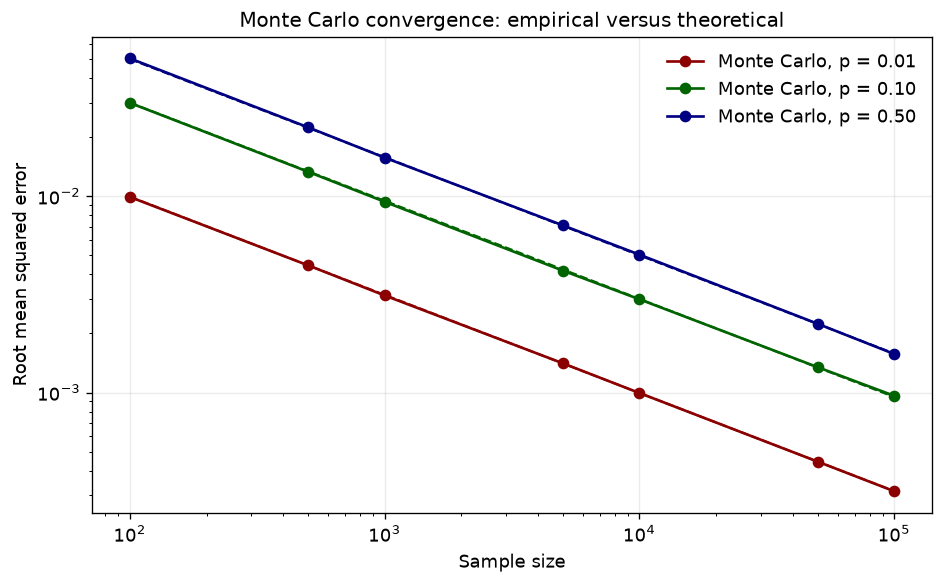

In [65]:
fig, ax = plt.subplots()

for p_true, color in [
    (0.01, "darkred"),
    (0.10, "darkgreen"),
    (0.50, "navy")
]:

    subset = e01_summary.loc[
        np.isclose(e01_summary["p_true"], p_true)
    ].sort_values("sample_size")

    ax.plot(
        subset["sample_size"],
        subset["rmse"],
        marker="o",
        color=color,
        linewidth=1.6,
        label=f"Monte Carlo, p = {p_true:.2f}"
    )

    ax.plot(
        subset["sample_size"],
        subset["theoretical_rmse"],
        linestyle="--",
        color=color,
        linewidth=1.3
    )

ax.set(
    xlabel="Sample size",
    ylabel="Root mean squared error",
    title="Monte Carlo convergence: empirical versus theoretical"
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIGS_DIR / "Figure23_E01_Definitive_RMSE.png"
)
fig.savefig(
    FIGS_DIR / "Figure23_E01_Definitive_RMSE.pdf"
)

plt.show()

In [66]:
e01_reliability_records = []

for (n, p_true), group in e01_data.groupby(
    ["sample_size", "p_true"]
):

    errors = group["absolute_error"].to_numpy()
    se = np.sqrt(p_true * (1 - p_true) / n)

    for criterion, epsilon in [
        ("Fixed", E01_EPSILON),
        ("Standardized", E01_Z_TOLERANCE * se)
    ]:

        successes_mc = int(np.count_nonzero(
            errors <= epsilon + 1e-12
        ))

        empirical = successes_mc / len(errors)

        lower_k = max(
            0, int(np.ceil(n * (p_true - epsilon) - 1e-10))
        )

        upper_k = min(
            int(n),
            int(np.floor(n * (p_true + epsilon) + 1e-10))
        )

        if binom.cdf(upper_k, int(n), p_true) < 0.5:
            exact = (
                binom.cdf(upper_k, int(n), p_true)
                - binom.cdf(lower_k - 1, int(n), p_true)
            )
        else:
            exact = (
                binom.sf(lower_k - 1, int(n), p_true)
                - binom.sf(upper_k, int(n), p_true)
            )

        exact = float(np.clip(exact, 0, 1))

        e01_reliability_records.append({
            "sample_size": int(n),
            "p_true": float(p_true),
            "criterion": criterion,
            "epsilon": float(epsilon),
            "replications": len(errors),
            "successes_mc": successes_mc,
            "empirical_reliability": empirical,
            "exact_reliability": exact,
            "mc_se": np.sqrt(
                exact * (1 - exact) / len(errors)
            )
        })

e01_reliability = pd.DataFrame(e01_reliability_records)

e01_reliability["absolute_difference"] = np.abs(
    e01_reliability["empirical_reliability"] -
    e01_reliability["exact_reliability"]
)

assert e01_reliability[
    ["empirical_reliability", "exact_reliability"]
].ge(0).all().all()

assert e01_reliability[
    ["empirical_reliability", "exact_reliability"]
].le(1).all().all()

e01_reliability.to_csv(
    RESULTS_DIR / "E01_Definitive_Reliability.csv",
    index=False
)

e01_reliability

,sample_size,p_true,criterion,epsilon,replications,successes_mc,empirical_reliability,exact_reliability,mc_se,absolute_difference
0,100,0.01,Fixed,0.050000,9604,9604,1.000000,0.999929,0.000086,0.000071
1,100,0.01,Standardized,0.019502,9604,8854,0.921908,0.920627,0.002758,0.001281
2,100,0.05,Fixed,0.050000,9604,9500,0.989171,0.988528,0.001087,0.000644
3,100,0.05,Standardized,0.042717,9604,9284,0.966681,0.965891,0.001852,0.000789
4,100,0.10,Fixed,0.050000,9604,9011,0.938255,0.936398,0.002490,0.001857
...,...,...,...,...,...,...,...,...,...,...
121,100000,0.90,Standardized,0.001859,9604,9120,0.949604,0.949460,0.002235,0.000144
122,100000,0.95,Fixed,0.050000,9604,9604,1.000000,1.000000,0.000000,0.000000
123,100000,0.95,Standardized,0.001351,9604,9095,0.947001,0.950712,0.002209,0.003710
124,100000,0.99,Fixed,0.050000,9604,9604,1.000000,1.000000,0.000000,0.000000


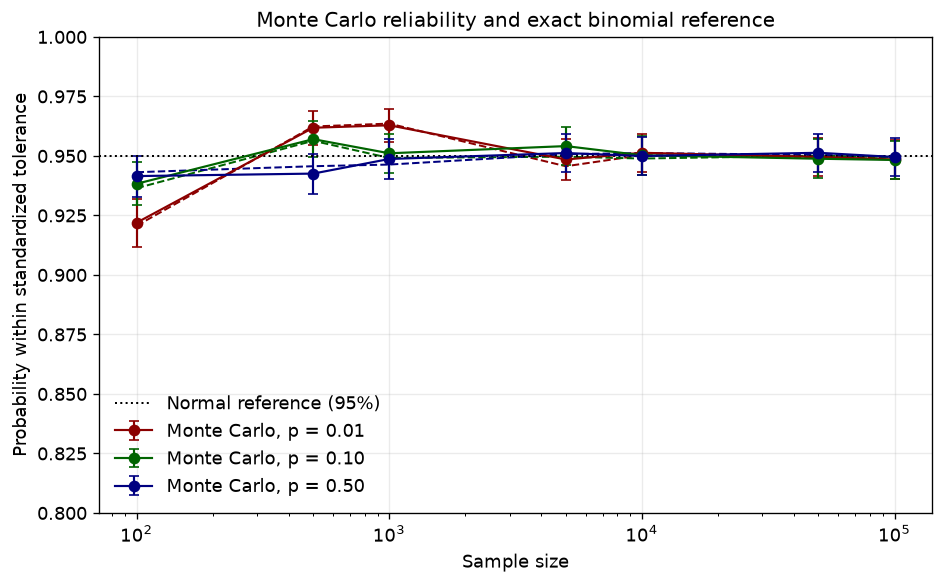

In [67]:
fig, ax = plt.subplots()

for p_true, color in [
    (0.01, "darkred"),
    (0.10, "darkgreen"),
    (0.50, "navy")
]:

    subset = e01_reliability.loc[
        (e01_reliability["criterion"] == "Standardized") &
        np.isclose(e01_reliability["p_true"], p_true)
    ].sort_values("sample_size")

    ax.errorbar(
        subset["sample_size"],
        subset["empirical_reliability"],
        yerr=E01_Z_CRITICAL * subset["mc_se"],
        marker="o",
        capsize=3,
        color=color,
        linewidth=1.3,
        label=f"Monte Carlo, p = {p_true:.2f}"
    )

    ax.plot(
        subset["sample_size"],
        subset["exact_reliability"],
        linestyle="--",
        color=color,
        linewidth=1.2
    )

ax.axhline(
    0.95,
    color="black",
    linestyle=":",
    linewidth=1.2,
    label="Normal reference (95%)"
)

ax.set(
    xlabel="Sample size",
    ylabel="Probability within standardized tolerance",
    title="Monte Carlo reliability and exact binomial reference"
)

ax.set_xscale("log")
ax.set_ylim(0.80, 1.00)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIGS_DIR / "Figure24_E01_Definitive_Reliability.png"
)
fig.savefig(
    FIGS_DIR / "Figure24_E01_Definitive_Reliability.pdf"
)

plt.show()

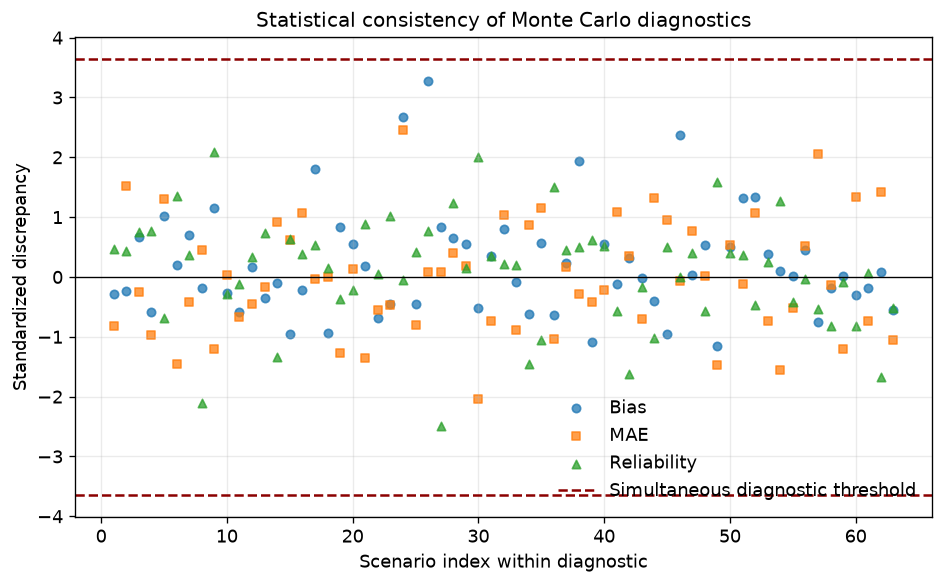

,diagnostic,scenarios,maximum_absolute_z,scenarios_within_tolerance
0,Bias,63,3.275007,63
1,MAE,63,2.451748,63
2,Reliability,63,2.493451,63


In [68]:
e01_audit_records = []

for row in e01_summary.itertuples():

    z_bias = (
        row.bias /
        np.sqrt(row.theoretical_variance / row.replications)
    )

    z_mae = (
        (row.mae - row.exact_mae) / row.mc_se_mae
        if row.mc_se_mae > 0 else 0.0
    )

    e01_audit_records.extend([
        {
            "sample_size": row.sample_size,
            "p_true": row.p_true,
            "diagnostic": "Bias",
            "z_score": z_bias
        },
        {
            "sample_size": row.sample_size,
            "p_true": row.p_true,
            "diagnostic": "MAE",
            "z_score": z_mae
        }
    ])

for row in e01_reliability.loc[
    e01_reliability["criterion"] == "Standardized"
].itertuples():

    if row.mc_se > 0:
        z_reliability = (
            row.empirical_reliability -
            row.exact_reliability
        ) / row.mc_se
    else:
        z_reliability = (
            0.0 if np.isclose(
                row.empirical_reliability,
                row.exact_reliability,
                atol=1e-12
            ) else np.inf
        )

    e01_audit_records.append({
        "sample_size": row.sample_size,
        "p_true": row.p_true,
        "diagnostic": "Reliability",
        "z_score": z_reliability
    })

e01_audit = pd.DataFrame(e01_audit_records)

assert len(e01_audit) == E01_N_COMPARISONS

e01_audit["within_tolerance"] = (
    e01_audit["z_score"].abs() <= E01_Z_CRITICAL
)

e01_audit.to_csv(
    RESULTS_DIR / "E01_Definitive_Audit.csv",
    index=False
)

e01_audit_summary = (
    e01_audit.groupby("diagnostic", as_index=False)
    .agg(
        scenarios=("z_score", "size"),
        maximum_absolute_z=("z_score", lambda x: np.max(np.abs(x))),
        scenarios_within_tolerance=("within_tolerance", "sum")
    )
)

e01_audit_summary.to_csv(
    RESULTS_DIR / "E01_Definitive_Audit_Summary.csv",
    index=False
)

# Figure 25 — Standardized diagnostic discrepancies
fig, ax = plt.subplots()

for diagnostic, marker in [
    ("Bias", "o"),
    ("MAE", "s"),
    ("Reliability", "^")
]:

    subset = e01_audit.loc[
        e01_audit["diagnostic"] == diagnostic
    ]

    ax.scatter(
        np.arange(len(subset)) + 1,
        subset["z_score"],
        marker=marker,
        s=25,
        alpha=0.75,
        label=diagnostic
    )

ax.axhline(
    E01_Z_CRITICAL,
    color="darkred",
    linestyle="--",
    label="Simultaneous diagnostic threshold"
)

ax.axhline(
    -E01_Z_CRITICAL,
    color="darkred",
    linestyle="--"
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set(
    xlabel="Scenario index within diagnostic",
    ylabel="Standardized discrepancy",
    title="Statistical consistency of Monte Carlo diagnostics"
)

ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIGS_DIR / "Figure25_E01_Statistical_Audit.png"
)
fig.savefig(
    FIGS_DIR / "Figure25_E01_Statistical_Audit.pdf"
)

plt.show()

e01_audit_summary

Parte 5

In [69]:
E02_SIZES = np.array([25, 100, 1000, 10000])
E02_PROBABILITIES = np.array([0.01, 0.05, 0.50, 0.95, 0.99])
E02_REPLICATIONS = DESIGN_REPLICATIONS
E02_SEED = DESIGN_SEED + 2000

e02_records = []

for i, n in enumerate(E02_SIZES):
    for j, p_true in enumerate(E02_PROBABILITIES):

        generator = np.random.default_rng(
            E02_SEED + 100 * i + j
        )

        counts = generator.binomial(
            int(n), float(p_true),
            size=E02_REPLICATIONS
        )

        estimates = counts / n
        se = np.sqrt(p_true * (1 - p_true) / n)

        e02_records.append(pd.DataFrame({
            "sample_size": int(n),
            "p_true": float(p_true),
            "replication": np.arange(1, E02_REPLICATIONS + 1),
            "successes": counts,
            "estimate": estimates,
            "z_score": (estimates - p_true) / se
        }))

e02_data = pd.concat(e02_records, ignore_index=True)

assert len(e02_data) == (
    len(E02_SIZES) * len(E02_PROBABILITIES) *
    E02_REPLICATIONS
)
assert e02_data["estimate"].between(0, 1).all()

e02_data.to_csv(
    RESULTS_DIR / "E02_Definitive_Distributions.csv.gz",
    index=False,
    compression="gzip")

In [70]:
e02_summary = (
    e02_data.groupby(["sample_size", "p_true"], as_index=False)
    .agg(
        mean_estimate=("estimate", "mean"),
        empirical_variance=("estimate", "var"),
        mean_z=("z_score", "mean"),
        variance_z=("z_score", "var")
    )
)

e02_summary["theoretical_variance"] = (
    e02_summary["p_true"] *
    (1 - e02_summary["p_true"]) /
    e02_summary["sample_size"]
)

e02_summary["variance_ratio"] = (
    e02_summary["empirical_variance"] /
    e02_summary["theoretical_variance"]
)

e02_summary["standardized_mean_error"] = (
    (e02_summary["mean_estimate"] - e02_summary["p_true"]) /
    np.sqrt(
        e02_summary["theoretical_variance"] /
        E02_REPLICATIONS
    )
)

assert np.isfinite(
    e02_summary.select_dtypes(include="number").to_numpy()
).all()

e02_summary.to_csv(
    RESULTS_DIR / "E02_Definitive_Moments.csv",
    index=False
)

e02_summary

,sample_size,p_true,mean_estimate,empirical_variance,mean_z,variance_z,theoretical_variance,variance_ratio,standardized_mean_error
0,25,0.01,0.009946,3.902501e-04,-0.002721,0.985480,3.960000e-04,0.985480,-0.266643
1,25,0.05,0.050396,1.895959e-03,0.009077,0.997873,1.900000e-03,0.997873,0.889571
2,25,0.50,0.500204,9.982339e-03,0.002041,0.998234,1.000000e-02,0.998234,0.200000
3,25,0.95,0.949792,1.922981e-03,-0.004778,1.012095,1.900000e-03,1.012095,-0.468195
4,25,0.99,0.989863,3.957324e-04,-0.006907,0.999324,3.960000e-04,0.999324,-0.676862
5,100,0.01,0.009914,9.697264e-05,-0.008686,0.979522,9.900000e-05,0.979522,-0.851205
6,100,0.05,0.050117,4.774414e-04,0.005351,1.005140,4.750000e-04,1.005140,0.524379
7,100,0.50,0.499910,2.457682e-03,-0.001791,0.983073,2.500000e-03,0.983073,-0.175510
8,100,0.95,0.949409,4.784381e-04,-0.027136,1.007238,4.750000e-04,1.007238,-2.659350
9,100,0.99,0.989981,1.002392e-04,-0.001884,1.012517,9.900000e-05,1.012517,-0.184599


In [71]:
from scipy.stats import binom, norm

e02_normal_records = []

for n in E02_SIZES:
    k = np.arange(int(n) + 1)

    for p_true in E02_PROBABILITIES:

        mu = n * p_true
        sigma = np.sqrt(n * p_true * (1 - p_true))

        exact_cdf = binom.cdf(k, int(n), p_true)

        normal_cdf = norm.cdf(
            (k + 0.5 - mu) / sigma
        )

        ks_distance = np.max(
            np.abs(exact_cdf - normal_cdf)
        )

        e02_normal_records.append({
            "sample_size": int(n),
            "p_true": float(p_true),
            "np": float(n * p_true),
            "n_one_minus_p": float(n * (1 - p_true)),
            "cdf_max_difference": ks_distance
        })

e02_normal_diagnostics = pd.DataFrame(
    e02_normal_records
)

assert e02_normal_diagnostics[
    "cdf_max_difference"
].between(0, 1).all()

e02_normal_diagnostics.to_csv(
    RESULTS_DIR / "E02_Normal_Approximation_Diagnostics.csv",
    index=False
)

e02_normal_diagnostics

,sample_size,p_true,np,n_one_minus_p,cdf_max_difference
0,25,0.01,0.25,24.75,0.085473
1,25,0.05,1.25,23.75,0.051649
2,25,0.50,12.50,12.50,0.001108
3,25,0.95,23.75,1.25,0.054147
4,25,0.99,24.75,0.25,0.085473
5,100,0.01,1.00,99.00,0.058381
6,100,0.05,5.00,95.00,0.026708
7,100,0.50,50.00,50.00,0.000273
8,100,0.95,95.00,5.00,0.026708
9,100,0.99,99.00,1.00,0.065834


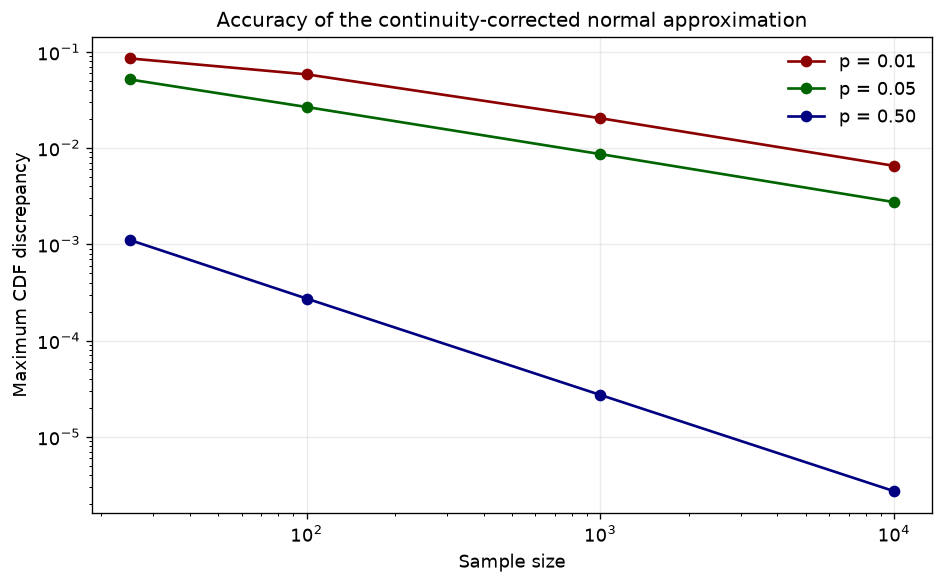

In [72]:
fig, ax = plt.subplots()

for p_true, color in [
    (0.01, "darkred"),
    (0.05, "darkgreen"),
    (0.50, "navy")
]:

    subset = e02_normal_diagnostics.loc[
        np.isclose(
            e02_normal_diagnostics["p_true"], p_true
        )
    ].sort_values("sample_size")

    ax.plot(
        subset["sample_size"],
        subset["cdf_max_difference"],
        marker="o",
        linewidth=1.6,
        color=color,
        label=f"p = {p_true:.2f}"
    )

ax.set(
    xlabel="Sample size",
    ylabel="Maximum CDF discrepancy",
    title="Accuracy of the continuity-corrected normal approximation"
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure26_E02_NormalAccuracy.png")
fig.savefig(FIGS_DIR / "Figure26_E02_NormalAccuracy.pdf")

plt.show()

In [73]:
E02_Z_LIMIT = norm.ppf(0.975)
e02_coverage_records = []

for (n, p_true), group in e02_data.groupby(
    ["sample_size", "p_true"]
):

    z_values = group["z_score"].to_numpy()
    empirical = np.mean(np.abs(z_values) <= E02_Z_LIMIT)

    se = np.sqrt(p_true * (1 - p_true) / n)

    k_min = max(
        0, int(np.ceil(
            n * (p_true - E02_Z_LIMIT * se) - 1e-10
        ))
    )
    k_max = min(
        int(n), int(np.floor(
            n * (p_true + E02_Z_LIMIT * se) + 1e-10
        ))
    )

    exact = binom.sf(k_min - 1, int(n), p_true) - binom.sf(
        k_max, int(n), p_true
    )

    e02_coverage_records.append({
        "sample_size": int(n),
        "p_true": float(p_true),
        "empirical_probability": empirical,
        "exact_probability": float(np.clip(exact, 0, 1)),
        "mc_se": np.sqrt(
            max(exact * (1 - exact), 0) / E02_REPLICATIONS
        )
    })

e02_normal_coverage = pd.DataFrame(e02_coverage_records)

e02_normal_coverage["absolute_difference"] = np.abs(
    e02_normal_coverage["empirical_probability"] -
    e02_normal_coverage["exact_probability"]
)

e02_normal_coverage.to_csv(
    RESULTS_DIR / "E02_Normal_Region_Coverage.csv",
    index=False
)

e02_normal_coverage

,sample_size,p_true,empirical_probability,exact_probability,mc_se,absolute_difference
0,25,0.01,0.975219,0.974241,0.001616,0.000978
1,25,0.05,0.966785,0.965909,0.001852,0.000875
2,25,0.50,0.958559,0.956715,0.002077,0.001844
3,25,0.95,0.964598,0.965909,0.001852,0.001311
4,25,0.99,0.974594,0.974241,0.001616,0.000353
5,100,0.01,0.923990,0.920627,0.002758,0.003363
6,100,0.05,0.966368,0.965891,0.001852,0.000477
7,100,0.50,0.946793,0.943112,0.002364,0.003681
8,100,0.95,0.968242,0.965891,0.001852,0.002351
9,100,0.99,0.917743,0.920627,0.002758,0.002884


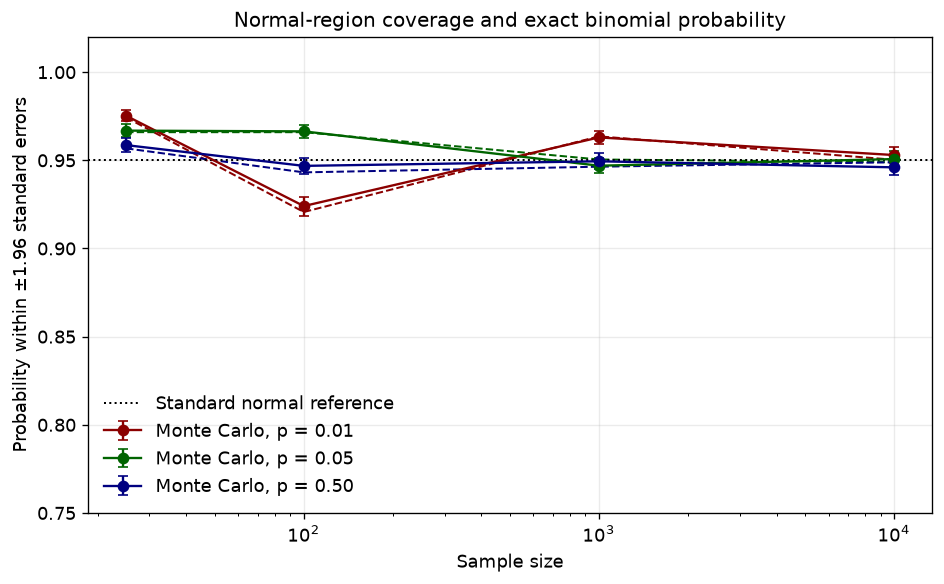

In [74]:
fig, ax = plt.subplots()

for p_true, color in [
    (0.01, "darkred"),
    (0.05, "darkgreen"),
    (0.50, "navy")
]:

    subset = e02_normal_coverage.loc[
        np.isclose(
            e02_normal_coverage["p_true"], p_true
        )
    ].sort_values("sample_size")

    ax.errorbar(
        subset["sample_size"],
        subset["empirical_probability"],
        yerr=1.96 * subset["mc_se"],
        marker="o",
        capsize=3,
        color=color,
        linewidth=1.4,
        label=f"Monte Carlo, p = {p_true:.2f}"
    )

    ax.plot(
        subset["sample_size"],
        subset["exact_probability"],
        linestyle="--",
        color=color,
        linewidth=1.2
    )

ax.axhline(
    0.95,
    color="black",
    linestyle=":",
    linewidth=1.2,
    label="Standard normal reference"
)

ax.set(
    xlabel="Sample size",
    ylabel="Probability within ±1.96 standard errors",
    title="Normal-region coverage and exact binomial probability"
)

ax.set_xscale("log")
ax.set_ylim(0.75, 1.02)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure27_E02_NormalCoverage.png")
fig.savefig(FIGS_DIR / "Figure27_E02_NormalCoverage.pdf")

plt.show()

In [75]:
from scipy.stats import binom, binomtest, norm
from time import perf_counter

E03_SIZES = np.array([25, 100, 1000, 5000])
E03_PROBABILITIES = DESIGN_PROBABILITIES.copy()
E03_REPLICATIONS = DESIGN_REPLICATIONS
E03_ALPHA = ALPHA
E03_SEED = DESIGN_SEED + 3000

records = []
timings = []

for i, n in enumerate(E03_SIZES):
    for j, p_true in enumerate(E03_PROBABILITIES):

        seed = E03_SEED + 100 * i + j
        generator = np.random.default_rng(seed)

        start = perf_counter()

        counts = generator.binomial(
            int(n), float(p_true),
            size=E03_REPLICATIONS
        )

        timings.append({
            "sample_size": int(n),
            "p_true": float(p_true),
            "seed": seed,
            "generation_seconds": perf_counter() - start
        })

        records.append(pd.DataFrame({
            "sample_size": int(n),
            "p_true": float(p_true),
            "replication": np.arange(1, E03_REPLICATIONS + 1),
            "successes": counts
        }))

e03_data = pd.concat(records, ignore_index=True)
e03_timing = pd.DataFrame(timings)

assert len(e03_data) == (
    len(E03_SIZES) * len(E03_PROBABILITIES)
    * E03_REPLICATIONS
)

e03_data.to_csv(
    RESULTS_DIR / "E03_Definitive_Replications.csv.gz",
    index=False,
    compression="gzip"
)

e03_timing.to_csv(
    RESULTS_DIR / "E03_Definitive_Timing.csv",
    index=False
)

In [76]:
records = []

for (n, p_true), group in e03_data.groupby(
    ["sample_size", "p_true"]
):

    counts = group["successes"].to_numpy()
    intervals = binomial_intervals(
        counts, int(n), E03_ALPHA
    )

    for method, (lower, upper) in intervals.items():

        covered = (
            (lower <= p_true + 1e-12) &
            (upper >= p_true - 1e-12)
        )

        widths = upper - lower

        records.append({
            "sample_size": int(n),
            "p_true": float(p_true),
            "method": method,
            "replications": len(counts),
            "covered_count": int(covered.sum()),
            "empirical_coverage": covered.mean(),
            "mean_width": widths.mean(),
            "sd_width": widths.std(ddof=1)
        })

e03_mc = pd.DataFrame(records)

assert e03_mc["empirical_coverage"].between(0, 1).all()
assert e03_mc["mean_width"].between(0, 1).all()

e03_mc.to_csv(
    RESULTS_DIR / "E03_Definitive_MC_Coverage.csv",
    index=False
)

e03_mc

,sample_size,p_true,method,replications,covered_count,empirical_coverage,mean_width,sd_width
0,25,0.01,Wald,9604,2104,0.219075,0.027473,0.053106
1,25,0.01,Wilson,9604,9367,0.975323,0.146323,0.025589
2,25,0.01,Clopper-Pearson,9604,9583,0.997813,0.152777,0.030443
3,25,0.05,Wald,9604,6893,0.717722,0.117117,0.086260
4,25,0.05,Wilson,9604,9311,0.969492,0.191119,0.043993
...,...,...,...,...,...,...,...,...
103,5000,0.95,Wilson,9604,9168,0.954602,0.012088,0.000349
104,5000,0.95,Clopper-Pearson,9604,9208,0.958767,0.012276,0.000349
105,5000,0.99,Wald,9604,9135,0.951166,0.005503,0.000385
106,5000,0.99,Wilson,9604,9080,0.945439,0.005552,0.000381


In [77]:
records = []

for n in E03_SIZES:

    k = np.arange(int(n) + 1)

    intervals = binomial_intervals(
        k, int(n), E03_ALPHA
    )

    for p_true in E03_PROBABILITIES:

        pmf = binom.pmf(k, int(n), float(p_true))

        for method, (lower, upper) in intervals.items():

            covered = (
                (lower <= p_true + 1e-12) &
                (upper >= p_true - 1e-12)
            )

            records.append({
                "sample_size": int(n),
                "p_true": float(p_true),
                "method": method,
                "exact_coverage": pmf[covered].sum(),
                "exact_expected_width": np.sum(
                    pmf * (upper - lower)
                )
            })

e03_exact = pd.DataFrame(records)

e03_comparison = e03_mc.merge(
    e03_exact,
    on=["sample_size", "p_true", "method"],
    validate="one_to_one"
)

e03_comparison["coverage_error"] = (
    e03_comparison["empirical_coverage"] -
    e03_comparison["exact_coverage"]
)

e03_comparison["width_error"] = (
    e03_comparison["mean_width"] -
    e03_comparison["exact_expected_width"]
)

assert e03_exact["exact_coverage"].between(0, 1).all()

assert (
    e03_exact.loc[
        e03_exact["method"] == "Clopper-Pearson",
        "exact_coverage"
    ] >= 1 - E03_ALPHA - 1e-10
).all()

e03_comparison.to_csv(
    RESULTS_DIR / "E03_Definitive_Exact_Comparison.csv",
    index=False
)

e03_comparison

,sample_size,p_true,method,replications,covered_count,empirical_coverage,mean_width,sd_width,exact_coverage,exact_expected_width,coverage_error,width_error
0,25,0.01,Wald,9604,2104,0.219075,0.027473,0.053106,0.222072,0.027868,-0.002996,-0.000395
1,25,0.01,Wilson,9604,9367,0.975323,0.146323,0.025589,0.974241,0.146515,0.001082,-0.000192
2,25,0.01,Clopper-Pearson,9604,9583,0.997813,0.152777,0.030443,0.998049,0.153007,-0.000236,-0.000230
3,25,0.05,Wald,9604,6893,0.717722,0.117117,0.086260,0.721397,0.118617,-0.003676,-0.001500
4,25,0.05,Wilson,9604,9311,0.969492,0.191119,0.043993,0.965909,0.191904,0.003582,-0.000785
...,...,...,...,...,...,...,...,...,...,...,...,...
103,5000,0.95,Wilson,9604,9168,0.954602,0.012088,0.000349,0.952302,0.012091,0.002300,-0.000003
104,5000,0.95,Clopper-Pearson,9604,9208,0.958767,0.012276,0.000349,0.955792,0.012279,0.002976,-0.000003
105,5000,0.99,Wald,9604,9135,0.951166,0.005503,0.000385,0.949916,0.005502,0.001250,0.000001
106,5000,0.99,Wilson,9604,9080,0.945439,0.005552,0.000381,0.945610,0.005551,-0.000170,0.000001


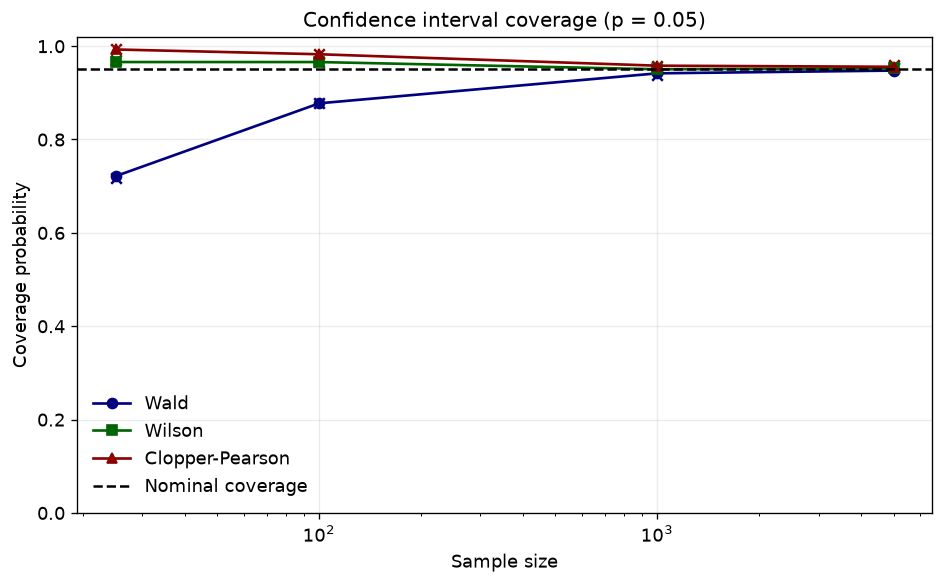

In [78]:
fig, ax = plt.subplots()

for method, color, marker in [
    ("Wald", "navy", "o"),
    ("Wilson", "darkgreen", "s"),
    ("Clopper-Pearson", "darkred", "^")
]:

    subset = e03_comparison.loc[
        (e03_comparison["method"] == method) &
        np.isclose(e03_comparison["p_true"], 0.05)
    ].sort_values("sample_size")

    ax.plot(
        subset["sample_size"],
        subset["exact_coverage"],
        marker=marker,
        color=color,
        linewidth=1.6,
        label=method
    )

    ax.scatter(
        subset["sample_size"],
        subset["empirical_coverage"],
        marker="x",
        color=color,
        s=40
    )

ax.axhline(
    0.95, color="black", linestyle="--",
    label="Nominal coverage"
)

ax.set(
    xlabel="Sample size",
    ylabel="Coverage probability",
    title="Confidence interval coverage (p = 0.05)"
)

ax.set_xscale("log")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure28_E03_CoverageBySize.png")
fig.savefig(FIGS_DIR / "Figure28_E03_CoverageBySize.pdf")

plt.show()

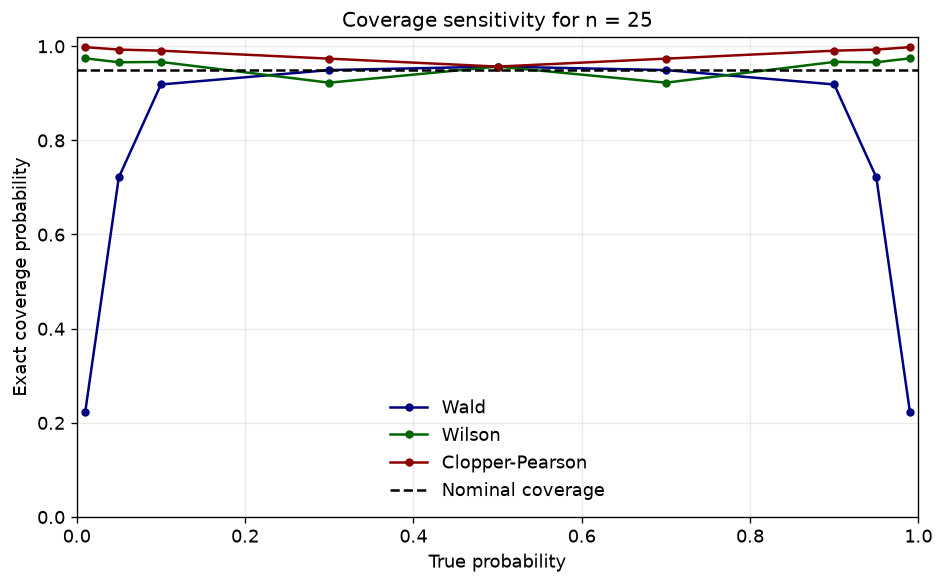

In [79]:
fig, ax = plt.subplots()

for method, color in [
    ("Wald", "navy"),
    ("Wilson", "darkgreen"),
    ("Clopper-Pearson", "darkred")
]:

    subset = e03_comparison.loc[
        (e03_comparison["sample_size"] == 25) &
        (e03_comparison["method"] == method)
    ].sort_values("p_true")

    ax.plot(
        subset["p_true"],
        subset["exact_coverage"],
        marker="o",
        markersize=4,
        color=color,
        linewidth=1.5,
        label=method
    )

ax.axhline(
    0.95, color="black", linestyle="--",
    label="Nominal coverage"
)

ax.set(
    xlabel="True probability",
    ylabel="Exact coverage probability",
    title="Coverage sensitivity for n = 25"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure29_E03_CoverageSensitivity.png")
fig.savefig(FIGS_DIR / "Figure29_E03_CoverageSensitivity.pdf")

plt.show()

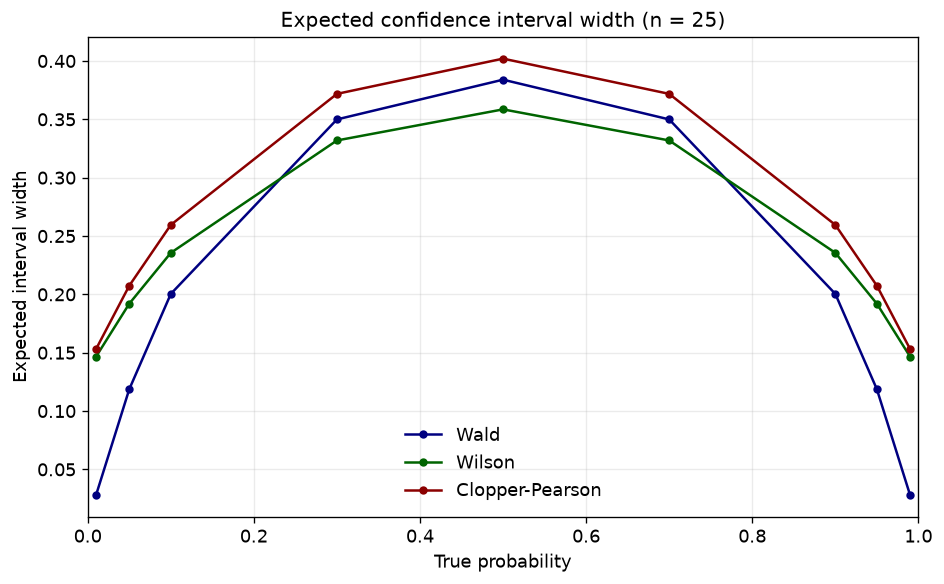

In [80]:
fig, ax = plt.subplots()

for method, color in [
    ("Wald", "navy"),
    ("Wilson", "darkgreen"),
    ("Clopper-Pearson", "darkred")
]:

    subset = e03_comparison.loc[
        (e03_comparison["sample_size"] == 25) &
        (e03_comparison["method"] == method)
    ].sort_values("p_true")

    ax.plot(
        subset["p_true"],
        subset["exact_expected_width"],
        marker="o",
        markersize=4,
        color=color,
        linewidth=1.5,
        label=method
    )

ax.set(
    xlabel="True probability",
    ylabel="Expected interval width",
    title="Expected confidence interval width (n = 25)"
)

ax.set_xlim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure30_E03_ExpectedWidth.png")
fig.savefig(FIGS_DIR / "Figure30_E03_ExpectedWidth.pdf")

plt.show()

In [81]:
E03_FAMILY_ALPHA = 0.05
E03_TESTS = len(e03_comparison)

e03_audit = e03_comparison.copy()

e03_audit["mc_se"] = np.sqrt(
    e03_audit["exact_coverage"] *
    (1 - e03_audit["exact_coverage"]) /
    e03_audit["replications"]
)

e03_audit["exact_p_value"] = [
    binomtest(
        int(row.covered_count),
        int(row.replications),
        float(row.exact_coverage)
    ).pvalue
    for row in e03_audit.itertuples()
]

e03_audit["adjusted_p_value"] = np.minimum(
    1.0,
    e03_audit["exact_p_value"] * E03_TESTS
)

e03_audit["mc_consistent"] = (
    e03_audit["adjusted_p_value"] >= E03_FAMILY_ALPHA
)

e03_audit.to_csv(
    RESULTS_DIR / "E03_Definitive_Statistical_Audit.csv",
    index=False
)

e03_audit_summary = (
    e03_audit.groupby("method", as_index=False)
    .agg(
        scenarios=("sample_size", "count"),
        maximum_absolute_coverage_error=(
            "coverage_error",
            lambda x: np.max(np.abs(x))
        ),
        mean_absolute_coverage_error=(
            "coverage_error",
            lambda x: np.mean(np.abs(x))
        ),
        minimum_adjusted_p_value=(
            "adjusted_p_value", "min"
        ),
        consistent_scenarios=("mc_consistent", "sum")
    )
)

e03_audit_summary.to_csv(
    RESULTS_DIR / "E03_Definitive_Audit_Summary.csv",
    index=False
)

e03_audit_summary

,method,scenarios,maximum_absolute_coverage_error,mean_absolute_coverage_error,minimum_adjusted_p_value,consistent_scenarios
0,Clopper-Pearson,36,0.005782,0.001433,0.826884,36
1,Wald,36,0.007153,0.002368,0.886653,36
2,Wilson,36,0.006081,0.001800,0.619686,36


Parte 6

In [82]:
from scipy.stats import binom, norm
from time import perf_counter

E04_SIZES = np.array([100, 500, 1000])
E04_RHOS = np.array([0.0, 0.30, 0.70])

E04_P = 0.50
E04_REPLICATIONS = DESIGN_REPLICATIONS
E04_ALPHA = ALPHA
E04_SEED = DESIGN_SEED + 4000

E04_CHANGE_PROBABILITIES = (0.20, 0.80)

assert 0 < E04_P < 1
assert np.all((E04_RHOS >= 0) & (E04_RHOS < 1))
assert np.all(E04_SIZES % 2 == 0)

e04_config = pd.DataFrame({
    "parameter": [
        "sample_sizes", "autocorrelations",
        "marginal_probability", "replications",
        "alpha", "change_probabilities", "seed"
    ],
    "value": [
        str(E04_SIZES.tolist()),
        str(E04_RHOS.tolist()),
        E04_P,
        E04_REPLICATIONS,
        E04_ALPHA,
        str(E04_CHANGE_PROBABILITIES),
        E04_SEED
    ]
})

e04_config.to_csv(
    RESULTS_DIR / "E04_Definitive_Configuration.csv",
    index=False
)

In [83]:
e04_markov_records = []
e04_timing_records = []

for i, n in enumerate(E04_SIZES):
    for j, rho_value in enumerate(E04_RHOS):

        seed = E04_SEED + 100 * i + j
        generator = np.random.default_rng(seed)

        p11 = E04_P + rho_value * (1 - E04_P)
        p01 = E04_P * (1 - rho_value)

        start = perf_counter()

        state = generator.binomial(
            1, E04_P, size=E04_REPLICATIONS
        ).astype(np.int8)

        counts = state.astype(np.int32)

        lag1_products = np.zeros(
            E04_REPLICATIONS, dtype=np.int32
        )

        for t in range(1, int(n)):

            transition = np.where(
                state == 1, p11, p01
            )

            next_state = generator.binomial(
                1, transition
            ).astype(np.int8)

            lag1_products += state * next_state
            counts += next_state
            state = next_state

        elapsed = perf_counter() - start

        e04_markov_records.append(pd.DataFrame({
            "sample_size": int(n),
            "rho": float(rho_value),
            "replication": np.arange(
                1, E04_REPLICATIONS + 1
            ),
            "successes": counts,
            "estimate": counts / n,
            "lag1_products": lag1_products
        }))

        e04_timing_records.append({
            "sample_size": int(n),
            "rho": float(rho_value),
            "seed": seed,
            "seconds": elapsed
        })

e04_markov_data = pd.concat(
    e04_markov_records, ignore_index=True
)

e04_timing = pd.DataFrame(e04_timing_records)

assert len(e04_markov_data) == (
    len(E04_SIZES) * len(E04_RHOS) *
    E04_REPLICATIONS
)

assert e04_markov_data["estimate"].between(0, 1).all()

e04_markov_data.to_csv(
    RESULTS_DIR / "E04_Definitive_Markov.csv.gz",
    index=False,
    compression="gzip"
)

e04_timing.to_csv(
    RESULTS_DIR / "E04_Definitive_Timing.csv",
    index=False)

In [84]:
e04_dependence_records = []

for (n, rho_value), group in e04_markov_data.groupby(
    ["sample_size", "rho"]
):

    estimates = group["estimate"].to_numpy()
    counts = group["successes"].to_numpy()

    lags = np.arange(1, int(n))

    inflation = 1 + 2 * np.sum(
        (1 - lags / n) * rho_value**lags
    )

    theoretical_variance = (
        E04_P * (1 - E04_P) / n * inflation
    )

    empirical_variance = estimates.var(ddof=1)

    lower, upper = binomial_intervals(
        counts, int(n), E04_ALPHA
    )["Wilson"]

    coverage = np.mean(
        (lower <= E04_P) & (E04_P <= upper)
    )

    lag1_moment = (
        group["lag1_products"].mean() / (n - 1)
    )

    empirical_rho = (
        (lag1_moment - E04_P**2) /
        (E04_P * (1 - E04_P))
    )

    e04_dependence_records.append({
        "sample_size": int(n),
        "rho": float(rho_value),
        "empirical_rho": empirical_rho,
        "empirical_mean": estimates.mean(),
        "empirical_variance": empirical_variance,
        "theoretical_variance": theoretical_variance,
        "empirical_inflation": (
            empirical_variance /
            (E04_P * (1 - E04_P) / n)
        ),
        "theoretical_inflation": inflation,
        "wilson_coverage": coverage,
        "mc_se_coverage": np.sqrt(
            coverage * (1 - coverage) /
            E04_REPLICATIONS
        )
    })

e04_dependence = pd.DataFrame(
    e04_dependence_records
)

assert np.isfinite(
    e04_dependence.select_dtypes(
        include="number"
    ).to_numpy()
).all()

e04_dependence.to_csv(
    RESULTS_DIR / "E04_Definitive_Dependence.csv",
    index=False
)

e04_dependence

,sample_size,rho,empirical_rho,empirical_mean,empirical_variance,theoretical_variance,empirical_inflation,theoretical_inflation,wilson_coverage,mc_se_coverage
0,100,0.0,-0.000560,0.499744,0.002520,0.002500,1.007825,1.000000,0.941691,0.002391
1,100,0.3,0.305130,0.501177,0.004614,0.004612,1.845544,1.844898,0.837880,0.003761
2,100,0.7,0.700857,0.500336,0.014004,0.013778,5.601442,5.511111,0.566535,0.005057
3,500,0.0,-0.000060,0.500075,0.000490,0.000500,0.979473,1.000000,0.950437,0.002215
4,500,0.3,0.301181,0.500243,0.000936,0.000927,1.872794,1.854694,0.839442,0.003746
5,500,0.7,0.696774,0.499290,0.002870,0.002818,5.740630,5.635556,0.576322,0.005042
6,1000,0.0,-0.000853,0.499803,0.000248,0.000250,0.991936,1.000000,0.948147,0.002263
7,1000,0.3,0.300292,0.500029,0.000460,0.000464,1.840986,1.855918,0.847355,0.003670
8,1000,0.7,0.700572,0.500166,0.001389,0.001413,5.554561,5.651111,0.590379,0.005018


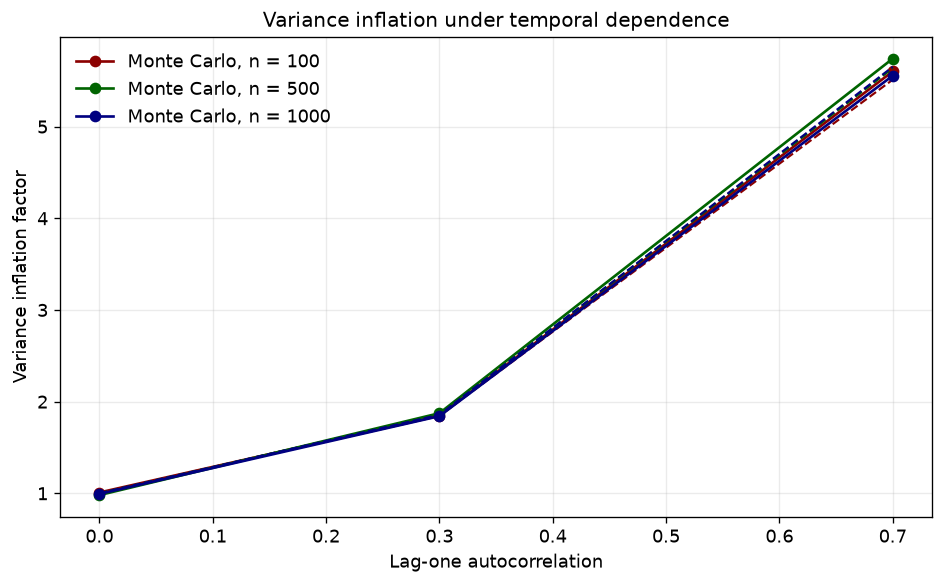

In [85]:
fig, ax = plt.subplots()

for n, color in [
    (100, "darkred"),
    (500, "darkgreen"),
    (1000, "navy")
]:

    subset = e04_dependence.loc[
        e04_dependence["sample_size"] == n
    ].sort_values("rho")

    ax.plot(
        subset["rho"],
        subset["empirical_inflation"],
        marker="o",
        color=color,
        linewidth=1.6,
        label=f"Monte Carlo, n = {n}"
    )

    ax.plot(
        subset["rho"],
        subset["theoretical_inflation"],
        linestyle="--",
        color=color,
        linewidth=1.3
    )

ax.set(
    xlabel="Lag-one autocorrelation",
    ylabel="Variance inflation factor",
    title="Variance inflation under temporal dependence"
)

ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIGS_DIR / "Figure31_E04_VarianceInflation.png"
)
fig.savefig(
    FIGS_DIR / "Figure31_E04_VarianceInflation.pdf"
)

plt.show()

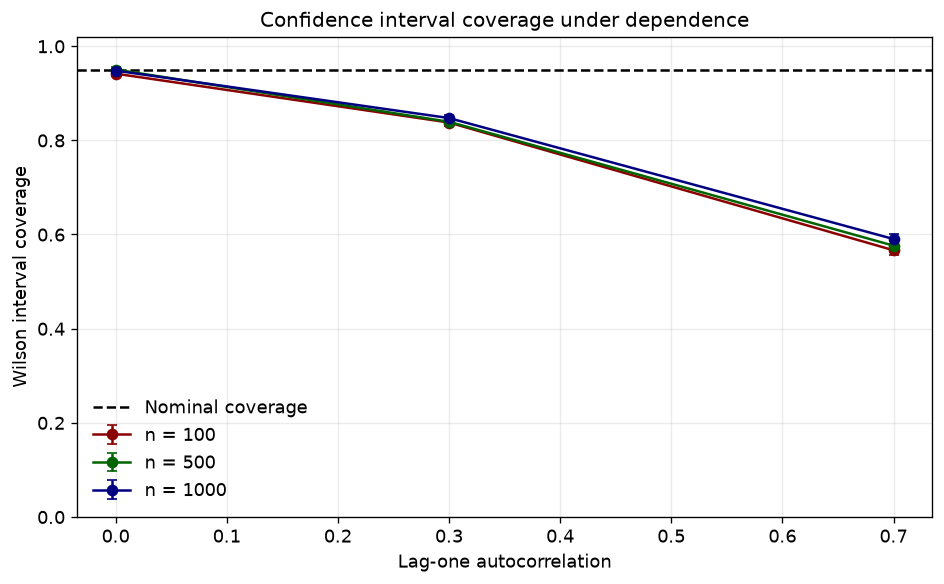

In [86]:
fig, ax = plt.subplots()

for n, color in [
    (100, "darkred"),
    (500, "darkgreen"),
    (1000, "navy")
]:

    subset = e04_dependence.loc[
        e04_dependence["sample_size"] == n
    ].sort_values("rho")

    ax.errorbar(
        subset["rho"],
        subset["wilson_coverage"],
        yerr=1.96 * subset["mc_se_coverage"],
        marker="o",
        capsize=3,
        linewidth=1.5,
        color=color,
        label=f"n = {n}"
    )

ax.axhline(
    1 - E04_ALPHA,
    linestyle="--",
    color="black",
    label="Nominal coverage"
)

ax.set(
    xlabel="Lag-one autocorrelation",
    ylabel="Wilson interval coverage",
    title="Confidence interval coverage under dependence"
)

ax.set_ylim(0, 1.02)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIGS_DIR / "Figure32_E04_DependenceCoverage.png"
)
fig.savefig(
    FIGS_DIR / "Figure32_E04_DependenceCoverage.pdf"
)

plt.show()

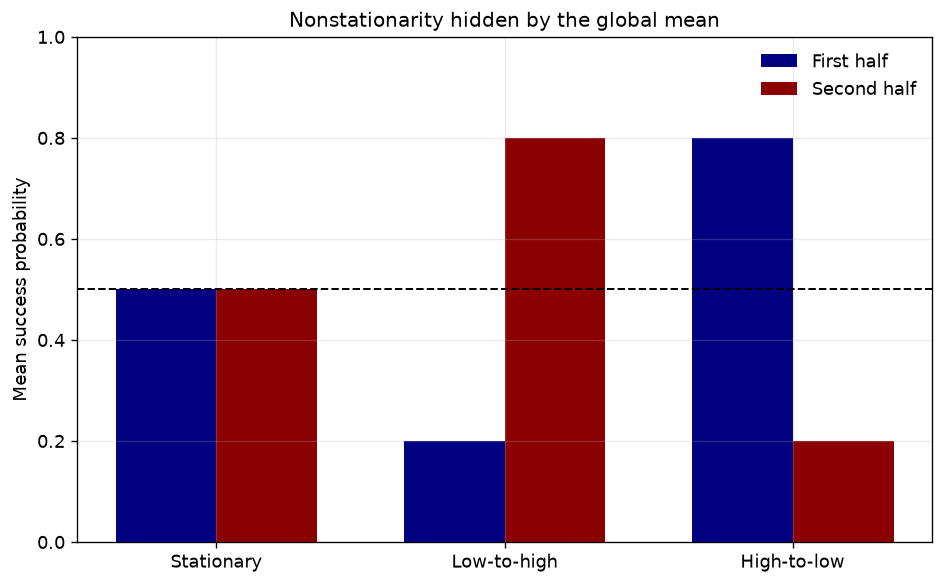

,scenario,p_first,p_second,theoretical_mean,empirical_mean,first_half_mean,second_half_mean,empirical_variance,theoretical_variance
0,Stationary,0.5,0.5,0.5,0.500058,0.500139,0.499976,0.000251,0.00025
1,Low-to-high,0.2,0.8,0.5,0.500006,0.199826,0.800186,0.000160,0.00016
2,High-to-low,0.8,0.2,0.5,0.500171,0.800400,0.199941,0.000156,0.00016


In [87]:
E04_NS_N = 1000
E04_NS_REPLICATIONS = E04_REPLICATIONS

regimes = {
    "Stationary": (0.50, 0.50),
    "Low-to-high": (0.20, 0.80),
    "High-to-low": (0.80, 0.20)
}

e04_ns_records = []

for i, (scenario, (p1, p2)) in enumerate(
    regimes.items()
):

    generator = np.random.default_rng(
        E04_SEED + 2000 + i
    )

    half_n = E04_NS_N // 2

    k1 = generator.binomial(
        half_n, p1, size=E04_NS_REPLICATIONS
    )

    k2 = generator.binomial(
        half_n, p2, size=E04_NS_REPLICATIONS
    )

    estimates = (k1 + k2) / E04_NS_N

    theoretical_variance = (
        half_n * p1 * (1 - p1) +
        half_n * p2 * (1 - p2)
    ) / E04_NS_N**2

    e04_ns_records.append({
        "scenario": scenario,
        "p_first": p1,
        "p_second": p2,
        "theoretical_mean": (p1 + p2) / 2,
        "empirical_mean": estimates.mean(),
        "first_half_mean": (k1 / half_n).mean(),
        "second_half_mean": (k2 / half_n).mean(),
        "empirical_variance": estimates.var(ddof=1),
        "theoretical_variance": theoretical_variance
    })

e04_nonstationary = pd.DataFrame(e04_ns_records)

assert np.allclose(
    e04_nonstationary["theoretical_mean"], 0.50
)

e04_nonstationary.to_csv(
    RESULTS_DIR / "E04_Definitive_Nonstationarity.csv",
    index=False
)

fig, ax = plt.subplots()

x = np.arange(len(e04_nonstationary))
width = 0.35

ax.bar(
    x - width / 2,
    e04_nonstationary["first_half_mean"],
    width,
    color="navy",
    label="First half"
)

ax.bar(
    x + width / 2,
    e04_nonstationary["second_half_mean"],
    width,
    color="darkred",
    label="Second half"
)

ax.axhline(
    0.50, linestyle="--",
    color="black",
    linewidth=1.2
)

ax.set_xticks(x)
ax.set_xticklabels(
    e04_nonstationary["scenario"]
)

ax.set(
    ylabel="Mean success probability",
    title="Nonstationarity hidden by the global mean"
)

ax.set_ylim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIGS_DIR / "Figure33_E04_Nonstationarity.png"
)
fig.savefig(
    FIGS_DIR / "Figure33_E04_Nonstationarity.pdf"
)

plt.show()

e04_nonstationary

In [97]:

# CELL 85 — Corrected E04 statistical audit

audit_records = []

for row in e04_dependence.itertuples():

    n = row.sample_size
    rho = row.rho

    group = e04_markov_data.loc[
        (e04_markov_data["sample_size"] == n) &
        np.isclose(e04_markov_data["rho"], rho)
    ]

    mc_se_mean = np.sqrt(
        row.theoretical_variance / len(group)
    )

    z_mean = (row.empirical_mean - E04_P) / mc_se_mean

    lag1_moments = (
        group["lag1_products"].to_numpy() / (n - 1)
    )

    theoretical_lag1 = (
        E04_P * (E04_P + rho * (1 - E04_P))
    )

    mc_se_lag1 = (
        lag1_moments.std(ddof=1) / np.sqrt(len(group))
    )

    z_lag1 = (
        lag1_moments.mean() - theoretical_lag1
    ) / mc_se_lag1

    for test, z_score in [
        ("Mean", z_mean),
        ("Lag1 moment", z_lag1)
    ]:
        audit_records.append({
            "scenario": f"Markov_n{n}_rho{rho}",
            "test": test,
            "standardized_discrepancy": z_score
        })

for row in e04_nonstationary.itertuples():

    mc_se_mean = np.sqrt(
        row.theoretical_variance / E04_NS_REPLICATIONS
    )

    audit_records.append({
        "scenario": row.scenario,
        "test": "Global mean",
        "standardized_discrepancy": (
            row.empirical_mean - row.theoretical_mean
        ) / mc_se_mean
    })

e04_audit = pd.DataFrame(audit_records)

E04_AUDIT_THRESHOLD = norm.ppf(
    1 - 0.05 / (2 * len(e04_audit))
)

e04_audit["within_tolerance"] = (
    e04_audit["standardized_discrepancy"].abs()
    <= E04_AUDIT_THRESHOLD
)

e04_audit.to_csv(
    RESULTS_DIR / "E04_Definitive_Audit.csv",
    index=False
)

e04_audit

,scenario,test,standardized_discrepancy,within_tolerance
0,Markov_n100_rho0.0,Mean,-0.502041,True
1,Markov_n100_rho0.0,Lag1 moment,-0.242196,True
2,Markov_n100_rho0.3,Mean,1.697838,True
3,Markov_n100_rho0.3,Lag1 moment,1.733013,True
4,Markov_n100_rho0.7,Mean,0.280793,True
5,Markov_n100_rho0.7,Lag1 moment,0.174555,True
6,Markov_n500_rho0.0,Mean,0.326740,True
7,Markov_n500_rho0.0,Lag1 moment,-0.059587,True
8,Markov_n500_rho0.3,Mean,0.782084,True
9,Markov_n500_rho0.3,Lag1 moment,0.892729,True


Parte 7

In [89]:
from scipy.stats import binom, binomtest, norm
from time import perf_counter

E05_N = 1000
E05_REPLICATIONS = DESIGN_REPLICATIONS
E05_BATCH_SIZE = 256
E05_P = 0.50
E05_ALPHA = 0.05
E05_MIN_N = 20
E05_SEED = DESIGN_SEED + 5000

# Predefined apparent-stability criteria
E05_STABILITY_START = 80
E05_STABILITY_END = 100
E05_FUTURE_END = 500

E05_STABILITY_THRESHOLD = 0.05
E05_FUTURE_ERROR_THRESHOLD = 0.10

E05_Z = norm.ppf(1 - E05_ALPHA / 2)
E05_N_GRID = np.arange(E05_MIN_N, E05_N + 1)

assert E05_MIN_N < E05_STABILITY_START
assert E05_STABILITY_START < E05_STABILITY_END
assert E05_STABILITY_END < E05_FUTURE_END <= E05_N

e05_config = pd.DataFrame({
    "parameter": [
        "sample_size", "replications", "batch_size",
        "null_probability", "alpha", "monitoring_start",
        "stability_window", "future_window",
        "stability_threshold", "future_error_threshold", "seed"
    ],
    "value": [
        E05_N, E05_REPLICATIONS, E05_BATCH_SIZE,
        E05_P, E05_ALPHA, E05_MIN_N,
        f"{E05_STABILITY_START}-{E05_STABILITY_END}",
        f"{E05_STABILITY_END + 1}-{E05_FUTURE_END}",
        E05_STABILITY_THRESHOLD,
        E05_FUTURE_ERROR_THRESHOLD,
        E05_SEED
    ]
})

e05_config.to_csv(
    RESULTS_DIR / "E05_Definitive_Configuration.csv",
    index=False)

In [90]:
e05_generator = np.random.default_rng(E05_SEED)

e05_records = []
e05_cumulative_counts = np.zeros(len(E05_N_GRID), dtype=np.int64)
e05_fixed_counts = np.zeros(len(E05_N_GRID), dtype=np.int64)

e05_start = perf_counter()

for start_rep in range(0, E05_REPLICATIONS, E05_BATCH_SIZE):

    batch_size = min(
        E05_BATCH_SIZE, E05_REPLICATIONS - start_rep
    )

    samples = e05_generator.binomial(
        1, E05_P, size=(batch_size, E05_N)
    )

    cumulative = np.cumsum(samples, axis=1)
    counts = cumulative[:, E05_MIN_N - 1:]

    estimates = counts / E05_N_GRID
    denominator = 1 + E05_Z**2 / E05_N_GRID

    center = (
        estimates + E05_Z**2 / (2 * E05_N_GRID)
    ) / denominator

    margin = E05_Z / denominator * np.sqrt(
        estimates * (1 - estimates) / E05_N_GRID
        + E05_Z**2 / (4 * E05_N_GRID**2)
    )

    rejected = (
        (center - margin > E05_P) |
        (center + margin < E05_P)
    )

    cumulative_rejected = np.maximum.accumulate(
        rejected, axis=1
    )

    e05_cumulative_counts += cumulative_rejected.sum(axis=0)
    e05_fixed_counts += rejected.sum(axis=0)

    fixed = rejected[:, -1]
    sequential = rejected.any(axis=1)

    first_n = np.where(
        sequential,
        E05_N_GRID[np.argmax(rejected, axis=1)],
        np.nan
    )

    frequency = cumulative / np.arange(1, E05_N + 1)

    stability_range = np.ptp(
        frequency[
            :, E05_STABILITY_START - 1:E05_STABILITY_END
        ],
        axis=1
    )

    future_max_error = np.max(
        np.abs(
            frequency[:, E05_STABILITY_END:E05_FUTURE_END]
            - E05_P
        ),
        axis=1
    )

    e05_records.append(pd.DataFrame({
        "replication": np.arange(
            start_rep + 1, start_rep + batch_size + 1
        ),
        "final_estimate": frequency[:, -1],
        "fixed_rejection": fixed,
        "sequential_rejection": sequential,
        "first_rejection_n": first_n,
        "stability_range": stability_range,
        "future_max_error": future_max_error
    }))

e05_elapsed = perf_counter() - e05_start

e05_data = pd.concat(e05_records, ignore_index=True)

e05_data["apparently_stable"] = (
    e05_data["stability_range"] <= E05_STABILITY_THRESHOLD
)

e05_data["subsequent_deviation"] = (
    e05_data["future_max_error"] > E05_FUTURE_ERROR_THRESHOLD
)

e05_data["misleading_stability"] = (
    e05_data["apparently_stable"] &
    e05_data["subsequent_deviation"]
)

assert len(e05_data) == E05_REPLICATIONS
assert (
    ~e05_data["fixed_rejection"] |
    e05_data["sequential_rejection"]
).all()

e05_data.to_csv(
    RESULTS_DIR / "E05_Definitive_Replications.csv.gz",
    index=False,
    compression="gzip"
)

e05_timing = pd.DataFrame({
    "replications": [E05_REPLICATIONS],
    "sample_size": [E05_N],
    "elapsed_seconds": [e05_elapsed]
})

e05_timing.to_csv(
    RESULTS_DIR / "E05_Definitive_Timing.csv",
    index=False
)

In [91]:
e05_k = np.arange(E05_N + 1)

e05_intervals = binomial_intervals(
    e05_k, E05_N, E05_ALPHA
)

e05_lower, e05_upper = e05_intervals["Wilson"]

e05_rejection_mask = (
    (e05_lower > E05_P) |
    (e05_upper < E05_P)
)

e05_exact_fixed_rate = binom.pmf(
    e05_k, E05_N, E05_P
)[e05_rejection_mask].sum()

e05_reference = pd.DataFrame({
    "sample_size": [E05_N],
    "null_probability": [E05_P],
    "nominal_alpha": [E05_ALPHA],
    "exact_fixed_rejection_rate": [e05_exact_fixed_rate]
})

assert 0 <= e05_exact_fixed_rate <= 1

e05_reference.to_csv(
    RESULTS_DIR / "E05_Exact_Fixed_Reference.csv",
    index=False
)

e05_reference

,sample_size,null_probability,nominal_alpha,exact_fixed_rejection_rate
0,1000,0.5,0.05,0.053678


In [92]:
e05_fixed_count = int(e05_data["fixed_rejection"].sum())
e05_sequential_count = int(
    e05_data["sequential_rejection"].sum()
)

e05_additional_count = (
    e05_sequential_count - e05_fixed_count
)

e05_summary_records = []

for procedure, count in [
    ("Fixed sample", e05_fixed_count),
    ("Repeated monitoring", e05_sequential_count),
    ("Additional sequential rejection", e05_additional_count)
]:

    ci = binomtest(
        count, E05_REPLICATIONS
    ).proportion_ci(
        confidence_level=0.95,
        method="wilson"
    )

    e05_summary_records.append({
        "procedure": procedure,
        "replications": E05_REPLICATIONS,
        "rejections": count,
        "estimated_rate": count / E05_REPLICATIONS,
        "mc_ci_lower": ci.low,
        "mc_ci_upper": ci.high
    })

e05_summary = pd.DataFrame(e05_summary_records)

e05_fixed_validation_p = binomtest(
    e05_fixed_count,
    E05_REPLICATIONS,
    e05_exact_fixed_rate
).pvalue

e05_validation = pd.DataFrame({
    "criterion": [
        "Exact fixed-sample consistency",
        "Sequential rejection nesting",
        "Valid probability estimates"
    ],
    "passed": [
        e05_fixed_validation_p >= 0.05,
        e05_sequential_count >= e05_fixed_count,
        e05_summary["estimated_rate"].between(0, 1).all()
    ]
})

e05_summary.to_csv(
    RESULTS_DIR / "E05_Definitive_Summary.csv",
    index=False
)

e05_validation.to_csv(
    RESULTS_DIR / "E05_Definitive_Validation.csv",
    index=False
)

e05_summary

,procedure,replications,rejections,estimated_rate,mc_ci_lower,mc_ci_upper
0,Fixed sample,9604,501,0.052166,0.047895,0.056795
1,Repeated monitoring,9604,4230,0.440441,0.430539,0.450392
2,Additional sequential rejection,9604,3729,0.388276,0.378575,0.398066


In [93]:
e05_fixed_count = int(e05_data["fixed_rejection"].sum())
e05_sequential_count = int(
    e05_data["sequential_rejection"].sum()
)

e05_additional_count = (
    e05_sequential_count - e05_fixed_count
)

e05_summary_records = []

for procedure, count in [
    ("Fixed sample", e05_fixed_count),
    ("Repeated monitoring", e05_sequential_count),
    ("Additional sequential rejection", e05_additional_count)
]:

    ci = binomtest(
        count, E05_REPLICATIONS
    ).proportion_ci(
        confidence_level=0.95,
        method="wilson"
    )

    e05_summary_records.append({
        "procedure": procedure,
        "replications": E05_REPLICATIONS,
        "rejections": count,
        "estimated_rate": count / E05_REPLICATIONS,
        "mc_ci_lower": ci.low,
        "mc_ci_upper": ci.high
    })

e05_summary = pd.DataFrame(e05_summary_records)

e05_fixed_validation_p = binomtest(
    e05_fixed_count,
    E05_REPLICATIONS,
    e05_exact_fixed_rate
).pvalue

e05_validation = pd.DataFrame({
    "criterion": [
        "Exact fixed-sample consistency",
        "Sequential rejection nesting",
        "Valid probability estimates"
    ],
    "passed": [
        e05_fixed_validation_p >= 0.05,
        e05_sequential_count >= e05_fixed_count,
        e05_summary["estimated_rate"].between(0, 1).all()
    ]
})

e05_summary.to_csv(
    RESULTS_DIR / "E05_Definitive_Summary.csv",
    index=False
)

e05_validation.to_csv(
    RESULTS_DIR / "E05_Definitive_Validation.csv",
    index=False
)

e05_summary

,procedure,replications,rejections,estimated_rate,mc_ci_lower,mc_ci_upper
0,Fixed sample,9604,501,0.052166,0.047895,0.056795
1,Repeated monitoring,9604,4230,0.440441,0.430539,0.450392
2,Additional sequential rejection,9604,3729,0.388276,0.378575,0.398066


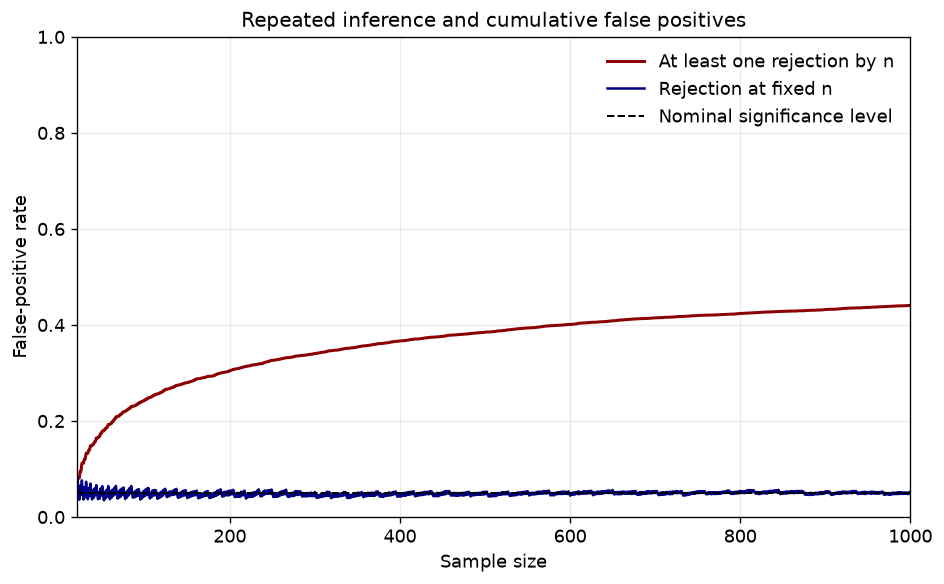

In [94]:
e05_stopping_curve = pd.DataFrame({
    "sample_size": E05_N_GRID,
    "fixed_sample_rate": (
        e05_fixed_counts / E05_REPLICATIONS
    ),
    "cumulative_rate": (
        e05_cumulative_counts / E05_REPLICATIONS
    )
})

assert np.all(
    np.diff(e05_stopping_curve["cumulative_rate"]) >= -1e-12
)

e05_stopping_curve.to_csv(
    RESULTS_DIR / "E05_Definitive_Stopping_Curve.csv",
    index=False
)

fig, ax = plt.subplots()

ax.plot(
    e05_stopping_curve["sample_size"],
    e05_stopping_curve["cumulative_rate"],
    color="darkred",
    linewidth=1.8,
    label="At least one rejection by n"
)

ax.plot(
    e05_stopping_curve["sample_size"],
    e05_stopping_curve["fixed_sample_rate"],
    color="navy",
    linewidth=1.5,
    label="Rejection at fixed n"
)

ax.axhline(
    E05_ALPHA,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Nominal significance level"
)

ax.set(
    xlabel="Sample size",
    ylabel="False-positive rate",
    title="Repeated inference and cumulative false positives"
)

ax.set_xlim(E05_MIN_N, E05_N)
ax.set_ylim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure34_E05_OptionalStopping.png")
fig.savefig(FIGS_DIR / "Figure34_E05_OptionalStopping.pdf")

plt.show()

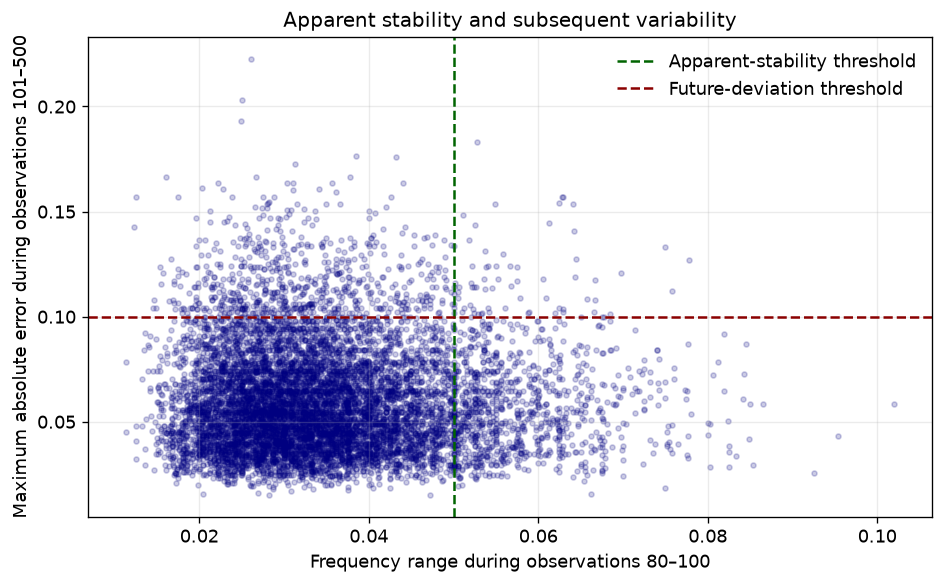

,criterion,count,frequency
0,Apparently stable,8560,0.891295
1,Subsequent deviation,733,0.076322
2,Both conditions,665,0.069242


In [95]:
e05_stability_summary = pd.DataFrame({
    "criterion": [
        "Apparently stable",
        "Subsequent deviation",
        "Both conditions"
    ],
    "count": [
        int(e05_data["apparently_stable"].sum()),
        int(e05_data["subsequent_deviation"].sum()),
        int(e05_data["misleading_stability"].sum())
    ]
})

e05_stability_summary["frequency"] = (
    e05_stability_summary["count"] / E05_REPLICATIONS
)

e05_stability_summary.to_csv(
    RESULTS_DIR / "E05_Stability_Summary.csv",
    index=False
)

fig, ax = plt.subplots()

ax.scatter(
    e05_data["stability_range"],
    e05_data["future_max_error"],
    color="navy",
    s=9,
    alpha=0.20,
    rasterized=True
)

ax.axvline(
    E05_STABILITY_THRESHOLD,
    color="darkgreen",
    linestyle="--",
    label="Apparent-stability threshold"
)

ax.axhline(
    E05_FUTURE_ERROR_THRESHOLD,
    color="darkred",
    linestyle="--",
    label="Future-deviation threshold"
)

ax.set(
    xlabel="Frequency range during observations 80–100",
    ylabel="Maximum absolute error during observations 101–500",
    title="Apparent stability and subsequent variability"
)

ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(FIGS_DIR / "Figure35_E05_ApparentStability.png")
fig.savefig(FIGS_DIR / "Figure35_E05_ApparentStability.pdf")

plt.show()

e05_stability_summary

In [96]:
e05_audit = pd.DataFrame({
    "criterion": [
        "Replications completed",
        "Sequential rejection nesting",
        "Cumulative rejection monotonicity",
        "Exact fixed-sample compatibility",
        "Stability classification consistency",
        "Finite computational time"
    ],
    "passed": [
        len(e05_data) == E05_REPLICATIONS,
        e05_sequential_count >= e05_fixed_count,
        np.all(np.diff(
            e05_stopping_curve["cumulative_rate"]
        ) >= -1e-12),
        e05_fixed_validation_p >= 0.05,
        (
            e05_data["misleading_stability"] ==
            (
                e05_data["apparently_stable"] &
                e05_data["subsequent_deviation"]
            )
        ).all(),
        np.isfinite(e05_elapsed) and e05_elapsed > 0
    ]
})

e05_audit["status"] = np.where(
    e05_audit["passed"], "PASS", "REVIEW"
)

e05_audit.to_csv(
    RESULTS_DIR / "E05_Definitive_Audit.csv",
    index=False
)

e05_audit

,criterion,passed,status
0,Replications completed,True,PASS
1,Sequential rejection nesting,True,PASS
2,Cumulative rejection monotonicity,True,PASS
3,Exact fixed-sample compatibility,True,PASS
4,Stability classification consistency,True,PASS
5,Finite computational time,True,PASS
